<a href="https://colab.research.google.com/github/doperjerr/Pandas_Review/blob/main/SC663402_Pandas_Review_673020044_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

นางสาวณัฐธิดา จันทโสภา 673020044-1

# SC 663 402 Data Warehouse and Big Data Analytics
## แบบฝึกทบทวน pandas

**ผู้สอน:** อ.ดร.พิชญา วิรัชโชติเสถียร (Pitchaya Wiratchotisatian)
**ภาควิชาสถิติ คณะวิทยาศาสตร์ มหาวิทยาลัยขอนแก่น**

---

### วัตถุประสงค์

การบ้านชุดนี้มีวัตถุประสงค์เพื่อทบทวนความรู้ pandas ที่นักศึกษาเคยศึกษามาแล้ว ให้อยู่ในระดับที่พร้อมสำหรับการวิเคราะห์ข้อมูลขนาดใหญ่ในรายวิชานี้
เนื้อหาครอบคลุมตั้งแต่โครงสร้างข้อมูลพื้นฐาน การเลือกและกรองข้อมูล การสรุปข้อมูลด้วย `groupby` การรวมตารางหลายตาราง จนถึงการสร้างกราฟจาก DataFrame

### รูปแบบ

แต่ละหัวข้อประกอบด้วยสองส่วน

1. **ตัวอย่าง** เป็นเซลล์โค้ดที่รันได้ทันที มีไว้เพื่อทบทวนรูปแบบการเรียกใช้คำสั่ง นักศึกษาควรรันและสังเกตผลลัพธ์ก่อนทำโจทย์
2. **โจทย์** เป็นแบบฝึกหัดที่มีระดับความยากสูงกว่าตัวอย่าง ไม่มีเฉลย นักศึกษาต้องเขียนคำตอบเองในเซลล์ที่เตรียมไว้

### ข้อกำหนดในการทำและการส่ง

1. เขียนคำตอบในเซลล์ที่เตรียมไว้ใต้โจทย์แต่ละข้อ
2. โจทย์ที่ระบุคำว่า **อธิบาย** ต้องตอบเป็นข้อความ การส่งเฉพาะโค้ดจะไม่ได้คะแนนในส่วนนั้น
3. ห้ามกำหนดคำตอบเป็นค่าคงที่ ทุกตัวเลขที่รายงานต้องคำนวณจากข้อมูล
4. ให้เขียนโปรแกรมในรูปแบบ vectorized เป็นหลัก หากจำเป็นต้องใช้การวนซ้ำทีละแถว ให้ระบุเหตุผลกำกับ
5. ก่อนส่งให้เลือกคำสั่ง Restart & Run All และตรวจสอบว่าไฟล์ทำงานได้ตลอดทั้งไฟล์
6. ส่งไฟล์ในรูปแบบ `.ipynb` ด้วยลิ้งก์ใน GitHub ของตนเอง

### เกณฑ์การประเมิน

* ความเรียบร้อย ครบถ้วน และความสามารถในการรันซ้ำได้

---
## ส่วนที่ 0 import libraries และ เตรียมข้อมูล

ชุดข้อมูลที่ใช้ประกอบด้วย 3 ตาราง ได้แก่ ข้อมูลสภาพอากาศรายวัน ข้อมูลเมือง และข้อมูลภูมิภาค
ให้รันเซลล์ต่อไปนี้เพื่อโหลดข้อมูลก่อนเริ่มทำการบ้าน

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
fonts-thai-tlwg is already the newest version (1:0.7.3-1).
0 upgraded, 0 newly installed, 0 to remove and 2 not upgraded.
ตั้งค่าระบบฟอนต์ภาษาไทยสำเร็จ!


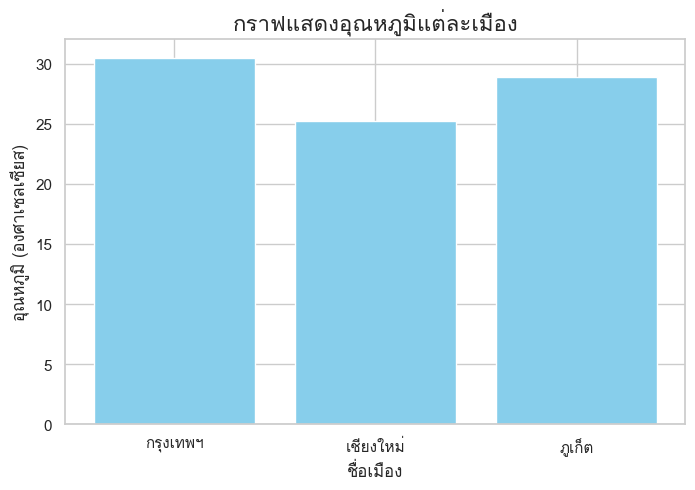

In [319]:
import pandas as pd
import numpy as np
import os, shutil
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import seaborn as sns

# 1. ติดตั้งฟอนต์ภาษาไทย
!apt-get -y install fonts-thai-tlwg

# 2. ล้าง cache ของ matplotlib เพื่ออัปเดตฟอนต์ใหม่
cache_dir = matplotlib.get_cachedir()
if os.path.exists(cache_dir):
    shutil.rmtree(cache_dir)

# 3. ลงทะเบียนฟอนต์ใหม่เข้ากับ FontManager
font_path = '/usr/share/fonts/truetype/tlwg/Loma.ttf'
if os.path.exists(font_path):
    fm.fontManager.addfont(font_path)

# 4. ตั้งค่าฟอนต์หลัก
plt.rcParams['font.family'] = 'Loma'
plt.rcParams['axes.unicode_minus'] = False

# 5. สร้างข้อมูลจำลองและแสดงผล
data = {
    'เมือง': ['กรุงเทพฯ', 'เชียงใหม่', 'ภูเก็ต'],
    'อุณหภูมิ': [30.5, 25.2, 28.9]
}
df_thai = pd.DataFrame(data)

print("ตั้งค่าระบบฟอนต์ภาษาไทยสำเร็จ!")

plt.figure(figsize=(8, 5))
plt.bar(df_thai['เมือง'], df_thai['อุณหภูมิ'], color='skyblue')
plt.title('กราฟแสดงอุณหภูมิแต่ละเมือง', fontsize=16)
plt.xlabel('ชื่อเมือง', fontsize=12)
plt.ylabel('อุณหภูมิ (องศาเซลเซียส)', fontsize=12)
plt.show()

In [2]:
import pandas as pd
import numpy as np

BASE = ("https://raw.githubusercontent.com/PitchayaW/"
        "SC-612-104-Essential-Data-Science/refs/heads/main/Module-A-Notebooks/Dataset/")

df = pd.read_csv(BASE + "world_weather_sample.csv")
city_info = pd.read_csv(BASE + "city_info.csv")
region_info = pd.read_csv(BASE + "region_info.csv")

print("weather:", df.shape, " city_info:", city_info.shape, " region_info:", region_info.shape)
df.head()

weather: (2075, 10)  city_info: (23, 5)  region_info: (6, 3)


,record_id,date,city,country,region,temperature_c,humidity_pct,rainfall_mm,wind_speed_kmh,pressure_hpa
0,983,2025-03-24,New York,USA,North America,15.7,72.6,6.3,15.9,1005.4
1,220,2025-02-09,Tokyo,Japan,Asia,18.3,60.6,0.0,20.5,1015.1
2,1022,2025-02-01,Los Angeles,USA,North America,20.6,46.8,1.2,8.6,1013.5
3,469,2025-01-19,Mumbai,India,Asia,31.0,73.4,8.0,11.8,1000.1
4,1834,2025-02-03,Cape Town,South Africa,Africa,19.1,55.0,0.0,16.6,1015.1


---
## ข้อ 1 การเปรียบเทียบคำสั่งที่มีลักษณะใกล้เคียงกัน

**คำสั่ง:** ให้นักศึกษารันเซลล์โค้ดทั้ง 6 เซลล์ต่อไปนี้ สังเกตผลลัพธ์ที่ได้ แล้วอธิบายกับตนเองให้เข้าใจความแตกต่างของคำสั่งในแต่ละเซลล์ พร้อมระบุว่าในทางปฏิบัติควรเลือกใช้คำสั่งใดในสถานการณ์ใด

การอธิบายควรครอบคลุมทั้ง **ชนิดของผลลัพธ์** **รูปร่างของผลลัพธ์** และ **ความหมายของค่าที่ได้**

In [176]:
# เซลล์ 1.1
s = pd.Series([10, 20, 30], index=["a", "b", "c"])
print(s["a"])
print(s.iloc[0])
print(s[["a", "c"]])

10
10
a    10
c    30
dtype: int64


**Ans** การเข้าถึงข้อมูลใน Series สามารถทำได้หลายวิธี เช่น s["a"] ใช้เลือกข้อมูลจากชื่อ Index ส่วน s.iloc[0] ใช้เลือกข้อมูลตามตำแหน่ง โดยเริ่มนับจาก 0 หากต้องการเลือกหลายข้อมูลสามารถใช้ s[["a","c"]] ได้ ดังนั้นควรเลือกใช้ให้เหมาะกับว่าต้องการอ้างอิงจาก ชื่อ Index หรือตำแหน่งของข้อมูล

In [177]:
# เซลล์ 1.2
print(type(df["city"]), df["city"].shape)
print(type(df[["city"]]), df[["city"]].shape)

<class 'pandas.core.series.Series'> (2075,)
<class 'pandas.core.frame.DataFrame'> (2075, 1)


**Ans** การเลือกคอลัมน์ด้วย df["city"] จะได้ผลลัพธ์เป็น Series ซึ่งเป็นข้อมูลแบบ 1 มิติ แต่ถ้าใช้ df[["city"]] จะได้เป็น DataFrame ซึ่งเป็นข้อมูลแบบ 2 มิติ แม้ว่าจะแสดงข้อมูลคอลัมน์เดียวกัน แต่โครงสร้างของผลลัพธ์แตกต่างกัน จึงควรเลือกใช้ตามรูปแบบข้อมูลที่ต้องการนำไปใช้งานต่อ

In [178]:
# เซลล์ 1.3
print(df.loc[0:3].shape)
print(df.iloc[0:3].shape)

(4, 10)
(3, 10)


**Ans** .loc[] ใช้เลือกข้อมูลโดยอ้างอิงจาก ชื่อ Index และเมื่อใช้การแบ่งช่วงจะรวมค่าปลายทางด้วย เช่น 0:3 จะรวม Index 3 ส่วน .iloc[] ใช้เลือกข้อมูลตาม ตำแหน่ง และจะไม่รวมตำแหน่งปลายทาง ดังนั้นจำง่าย ๆ ว่า loc ใช้ตามชื่อ ส่วน iloc ใช้ตามตำแหน่ง

In [179]:
# เซลล์ 1.4
print(df.groupby("city")["temperature_c"].count().head(3))
print(df.groupby("city").size().head(3))

city
Auckland    90
Bangkok     91
Beijing     89
Name: temperature_c, dtype: int64
city
Auckland    90
Bangkok     91
Beijing     90
dtype: int64


**Ans** เมื่อใช้ groupby() แล้ว count() จะนับเฉพาะข้อมูลที่มีค่าและจะไม่นับ NaN ส่วน size() จะนับจำนวนแถวทั้งหมดในแต่ละกลุ่ม รวมถึงแถวที่มีค่า NaN ด้วย ดังนั้นถ้าต้องการนับเฉพาะข้อมูลที่มีค่าให้ใช้ count() แต่ถ้าต้องการนับจำนวนแถวทั้งหมดให้ใช้ size()

In [180]:
# เซลล์ 1.5
print(df.groupby("city")["temperature_c"].mean().head(3))
print(df.groupby("city")[["temperature_c"]].mean().head(3))

city
Auckland    17.804444
Bangkok     32.453846
Beijing     15.598876
Name: temperature_c, dtype: float64
          temperature_c
city                   
Auckland      17.804444
Bangkok       32.453846
Beijing       15.598876


**Ans** การใช้ groupby() ร่วมกับ mean() สามารถหาค่าเฉลี่ยของข้อมูลในแต่ละกลุ่มได้ เช่น หาค่าเฉลี่ยอุณหภูมิของแต่ละเมือง หากใช้ ["temperature_c"] จะได้ผลลัพธ์เป็น Series แต่ถ้าใช้ [["temperature_c"]] จะได้ DataFrame โดยค่าที่คำนวณได้เหมือนกัน แต่รูปแบบของผลลัพธ์แตกต่างกัน

In [181]:
# เซลล์ 1.6
a = pd.Series([1, 2, 3], index=["x", "y", "z"])
b = pd.Series([10, 20, 30], index=["z", "y", "x"])
print(a + b)
print(a.to_numpy() + b.to_numpy())

x    31
y    22
z    13
dtype: int64
[11 22 33]


**Ans** เมื่อบวก Series สองตัวด้วย a + b Pandas จะจับคู่ข้อมูลตาม Index ก่อนนำมาคำนวณ ทำให้แม้ลำดับข้อมูลจะต่างกันก็ยังจับคู่ได้ถูกต้อง แต่ถ้าแปลงเป็น NumPy Array ด้วย .to_numpy() การคำนวณจะจับคู่ตาม ตำแหน่ง ของข้อมูลเท่านั้น ดังนั้น Series เหมาะเมื่อเราต้องการให้ Pandas ช่วยจับคู่ตาม Index ส่วน NumPy เหมาะเมื่อเราต้องการคำนวณตามตำแหน่งโดยตรง

---
## ข้อ 2 Series และ DataFrame

### ตัวอย่าง

In [182]:
# การสร้าง DataFrame จากโครงสร้างข้อมูลสองรูปแบบ
d1 = pd.DataFrame({"city": ["Bangkok", "Tokyo"], "temp": [30.5, 16.2]})
d2 = pd.DataFrame([{"city": "Bangkok", "temp": 30.5}, {"city": "Tokyo", "temp": 16.2}])
print(d1.equals(d2))

# การเข้าถึงองค์ประกอบของ DataFrame
print(df.columns.tolist())
print(df.index[:5].tolist())
print(df["temperature_c"].nlargest(3).tolist())

True
['record_id', 'date', 'city', 'country', 'region', 'temperature_c', 'humidity_pct', 'rainfall_mm', 'wind_speed_kmh', 'pressure_hpa']
[0, 1, 2, 3, 4]
[999.0, 999.0, 999.0]


### โจทย์ 2.1
สร้าง Series ชื่อ `rain_by_city` ซึ่งเก็บปริมาณฝนรวมของแต่ละเมือง โดยกำหนดให้ index เป็นชื่อเมือง จากนั้นตอบคำถามต่อไปนี้ด้วยโปรแกรม

1. เมืองที่มีปริมาณฝนรวมสูงสุด 3 อันดับแรก
2. สัดส่วนปริมาณฝนของแต่ละเมืองเทียบกับปริมาณฝนรวมทั้งหมด แสดงเป็นร้อยละทศนิยม 2 ตำแหน่ง
3. จำนวนเมืองที่มีปริมาณฝนรวมสูงกว่าค่าเฉลี่ยของทุกเมือง

In [183]:
import pandas as pd

# สร้าง Series ชื่อ rain_by_city เก็บปริมาณฝนรวมของแต่ละเมือง โดย index เป็นชื่อเมือง
rain_by_city = df.groupby('city')['rainfall_mm'].sum()

# 1. เมืองที่มีปริมาณฝนรวมสูงสุด 3 อันดับแรก
print("--- 1. เมืองที่มีปริมาณฝนรวมสูงสุด 3 อันดับแรก ---")
print(rain_by_city.nlargest(3))

# 2. สัดส่วนปริมาณฝนของแต่ละเมืองเทียบกับปริมาณฝนรวมทั้งหมด แสดงเป็นร้อยละทศนิยม 2 ตำแหน่ง
print("\n--- 2. สัดส่วนปริมาณฝนของแต่ละเมืองเทียบกับรวมทั้งหมด (%) ---")
rain_percentage = (rain_by_city / rain_by_city.sum()) * 100
print(rain_percentage.round(2).map("{:.2f}%".format))

# 3. จำนวนเมืองที่มีปริมาณฝนรวมสูงกว่าค่าเฉลี่ยของทุกเมือง
mean_rain = rain_by_city.mean()
count_above_mean = (rain_by_city > mean_rain).sum()
print(f"\n--- 3. จำนวนเมืองที่มีปริมาณฝนรวมสูงกว่าค่าเฉลี่ย ({mean_rain:.2f} มม.) ---")
print(f"จำนวนเมือง: {count_above_mean} เมือง")

--- 1. เมืองที่มีปริมาณฝนรวมสูงสุด 3 อันดับแรก ---
city
Singapore    870.4
Bangkok      685.6
Lagos        652.8
Name: rainfall_mm, dtype: float64

--- 2. สัดส่วนปริมาณฝนของแต่ละเมืองเทียบกับรวมทั้งหมด (%) ---
city
Auckland         4.22%
Bangkok          8.21%
Beijing          3.00%
Berlin           3.21%
Buenos Aires     3.65%
Cairo            1.47%
Cape Town        2.87%
Chiang Mai       5.22%
Lagos            7.82%
Lima             2.16%
London           3.27%
Los Angeles      2.03%
Mexico City      3.66%
Moscow           2.96%
Mumbai           5.84%
Nairobi          4.74%
New York         3.78%
Paris            3.99%
Sao Paulo        5.07%
Singapore       10.43%
Sydney           3.97%
Tokyo            4.61%
Toronto          3.81%
Name: rainfall_mm, dtype: object

--- 3. จำนวนเมืองที่มีปริมาณฝนรวมสูงกว่าค่าเฉลี่ย (362.97 มม.) ---
จำนวนเมือง: 8 เมือง


### โจทย์ 2.2
สร้าง DataFrame ชื่อ `city_profile` ที่มีหนึ่งแถวต่อหนึ่งเมือง ประกอบด้วยคอลัมน์
`city`, `country`, `region`, `n_records`, `avg_temp`, `total_rain`
โดยกำหนดให้ใช้ `groupby`

In [184]:
df.columns

Index(['record_id', 'date', 'city', 'country', 'region', 'temperature_c',
       'humidity_pct', 'rainfall_mm', 'wind_speed_kmh', 'pressure_hpa'],
      dtype='object')

In [185]:
# คำตอบข้อ 2.2
import pandas as pd

# สร้าง DataFrame ชื่อ city_profile โดยใช้ groupby และ aggregation
city_profile = df.groupby('city').agg(
    country=('country', 'first'),          # ดึงชื่อประเทศของเมืองนั้น (ค่าแรกในกลุ่ม)
    region=('region', 'first'),            # ดึงชื่อภูมิภาคของเมืองนั้น (ค่าแรกในกลุ่ม)
    n_records=('record_id', 'count'),      # นับจำนวนเรคคอร์ดทั้งหมดในแต่ละเมือง
    avg_temp=('temperature_c', 'mean'),    # หาค่าเฉลี่ยของอุณหภูมิ
    total_rain=('rainfall_mm', 'sum')      # หาผลรวมปริมาณฝน
).reset_index()                            # แปลง index (city) กลับมาเป็นคอลัมน์ปกติ

# แสดงผลลัพธ์ตัวอย่าง 5 แถวแรก
print(city_profile.head())

           city      country         region  n_records   avg_temp  total_rain
0      Auckland  New Zealand        Oceania         90  17.804444       351.9
1       Bangkok     Thailand           Asia         91  32.453846       685.6
2       Beijing        China           Asia         90  15.598876       250.1
3        Berlin      Germany         Europe         90  12.383146       268.4
4  Buenos Aires    Argentina  South America         90  19.171910       305.1


---
## ข้อ 3 การนำเข้าข้อมูลด้วย `read_csv()`

### ตัวอย่าง

In [186]:
# พารามิเตอร์ที่ใช้บ่อย ได้แก่ usecols, nrows, parse_dates, dtype, na_values
preview = pd.read_csv(
    BASE + "world_weather_sample.csv",
    usecols=["city", "date", "temperature_c"],
    parse_dates=["date"],
    nrows=5,
)
print(preview.dtypes)
preview

date             datetime64[ns]
city                     object
temperature_c           float64
dtype: object


,date,city,temperature_c
0,2025-03-24,New York,15.7
1,2025-02-09,Tokyo,18.3
2,2025-02-01,Los Angeles,20.6
3,2025-01-19,Mumbai,31.0
4,2025-02-03,Cape Town,19.1


In [187]:
# การอ่านข้อมูลทีละก้อนด้วย chunksize ซึ่งคืนค่าเป็น iterator
total_rows = 0
for chunk in pd.read_csv(BASE + "world_weather_sample.csv", chunksize=500):
    total_rows += len(chunk)
print("จำนวนแถวรวม:", total_rows)

จำนวนแถวรวม: 2075


### โจทย์ 3.1
เขียนคำสั่ง `pd.read_csv()` เพียงคำสั่งเดียวที่ดำเนินการทุกข้อต่อไปนี้ให้เสร็จสิ้นตั้งแต่ขั้นตอนการนำเข้า

1. อ่านเฉพาะคอลัมน์ `date`, `city`, `region`, `temperature_c`, `humidity_pct`, `rainfall_mm`
2. แปลงคอลัมน์ `date` เป็นชนิด datetime
3. กำหนดให้ค่า `999` และ `-999` ถูกอ่านเป็นค่าว่าง
4. กำหนดชนิดข้อมูลของ `city` และ `region` เป็น `category`
5. กำหนดให้ `city` เป็น index

ให้ตรวจสอบผลด้วย `.dtypes` และ `.info()`

In [188]:
import pandas as pd

# อ่านไฟล์ CSV พร้อมกำหนดเงื่อนไขครบถ้วนตามโจทย์
df = pd.read_csv(
    BASE + 'world_weather_sample.csv',
    usecols=['date', 'city', 'region', 'temperature_c', 'humidity_pct', 'rainfall_mm'], # 1. อ่านเฉพาะคอลัมน์ที่กำหนด
    parse_dates=['date'],          # 2. แปลงคอลัมน์ date เป็นชนิด datetime
    na_values=[999, -999],         # 3. กำหนดให้ 999 และ -999 อ่านเป็นค่าว่าง
    dtype={'city': 'category', 'region': 'category'}, # 4. กำหนดชนิดข้อมูล city และ region เป็น category
    index_col='city'               # 5. กำหนดให้ city เป็น index
)

# ตรวจสอบผลลัพธ์ตามที่โจทย์ต้องการ
print("--- ตรวจสอบด้วย .dtypes ---")
print(df.dtypes)

print("\n--- ตรวจสอบด้วย .info() ---")
df.info()

--- ตรวจสอบด้วย .dtypes ---
date             datetime64[ns]
region                 category
temperature_c           float64
humidity_pct            float64
rainfall_mm             float64
dtype: object

--- ตรวจสอบด้วย .info() ---
<class 'pandas.core.frame.DataFrame'>
CategoricalIndex: 2075 entries, New York to Paris
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   date           2075 non-null   datetime64[ns]
 1   region         2075 non-null   category      
 2   temperature_c  2052 non-null   float64       
 3   humidity_pct   1993 non-null   float64       
 4   rainfall_mm    2013 non-null   float64       
dtypes: category(1), datetime64[ns](1), float64(3)
memory usage: 69.8 KB


### โจทย์ 3.2
เปรียบเทียบปริมาณหน่วยความจำที่ใช้ระหว่างตารางที่นำเข้าตามปกติกับตารางจากโจทย์ 3.1 ด้วย `.memory_usage(deep=True)`
รายงานผลเป็นร้อยละที่ลดลง และ **อธิบาย** ว่าคอลัมน์ใดมีผลต่อการลดลงมากที่สุด เพราะเหตุใด

In [189]:
# คำตอบข้อ 3.2
# 1. โหลดข้อมูลแบบปกติ
df_normal = pd.read_csv(BASE + "world_weather_sample.csv")

# 2. โหลดข้อมูลตามเงื่อนไข (จากโจทย์ 3.1)
df_optimized = pd.read_csv(
    BASE + "world_weather_sample.csv",
    usecols=['date', 'city', 'region', 'temperature_c', 'humidity_pct', 'rainfall_mm'],
    parse_dates=['date'],
    na_values=[999, -999],
    dtype={'city': 'category', 'region': 'category'},
    index_col='city'
)

# คำนวณปริมาณหน่วยความจำรวมทั้งหมด
mem_normal = df_normal.memory_usage(deep=True).sum()
mem_optimized = df_optimized.memory_usage(deep=True).sum()

# คำนวณร้อยละที่ลดลง
decrease_pct = ((mem_normal - mem_optimized) / mem_normal) * 100

print(f"หน่วยความจำแบบปกติ: {mem_normal / (1024**2):.2f} MB")
print(f"หน่วยความจำแบบปรับแต่ง: {mem_optimized / (1024**2):.2f} MB")
print(f"ปริมาณหน่วยความจำที่ลดลง: {decrease_pct:.2f}%")

# แสดงรายละเอียดแยกตามคอลัมน์
print("\n--- รายละเอียดหน่วยความจำ (แบบปกติ) ---")
print(df_normal.memory_usage(deep=True))

print("\n--- รายละเอียดหน่วยความจำ (แบบปรับแต่ง) ---")
print(df_optimized.memory_usage(deep=True))


หน่วยความจำแบบปกติ: 0.55 MB
หน่วยความจำแบบปรับแต่ง: 0.07 MB
ปริมาณหน่วยความจำที่ลดลง: 87.24%

--- รายละเอียดหน่วยความจำ (แบบปกติ) ---
Index                132
record_id          16600
date              122425
city              116920
country           114937
region            117631
temperature_c      16600
humidity_pct       16600
rainfall_mm        16600
wind_speed_kmh     16600
pressure_hpa       16600
dtype: int64

--- รายละเอียดหน่วยความจำ (แบบปรับแต่ง) ---
Index             3927
date             16600
region            2590
temperature_c    16600
humidity_pct     16600
rainfall_mm      16600
dtype: int64


**Ans**

คอลัมน์ที่ช่วยลดหน่วยความจำมากที่สุดคือ region (117,631 bytes), city (116,920 bytes) และ country (114,937 bytes) เนื่องจากเป็นข้อมูลประเภทข้อความ (object/string) ซึ่งใช้หน่วยความจำมากกว่าข้อมูลตัวเลข และเมื่อลดคอลัมน์ที่ไม่จำเป็น จึงลดการใช้หน่วยความจำได้มาก

### โจทย์ 3.3
ใช้การอ่านข้อมูลแบบ `chunksize` เพื่อคำนวณค่าต่อไปนี้ โดยห้ามโหลดข้อมูลทั้งไฟล์เข้าหน่วยความจำพร้อมกัน และห้ามใช้ `pd.concat`

1. อุณหภูมิสูงสุดและต่ำสุดของทั้งไฟล์
2. อุณหภูมิเฉลี่ยรายเมือง

**อธิบาย:** เหตุใดการนำค่าเฉลี่ยของแต่ละก้อนมาเฉลี่ยกันอีกครั้งจึงให้ผลไม่ถูกต้อง และควรสะสมค่าใดแทนจึงจะได้ผลที่ถูกต้อง

In [190]:
# คำตอบข้อ 3.3
import pandas as pd

# ตัวแปรสำหรับเก็บค่าสูงสุดและต่ำสุดของทั้งไฟล์
global_max = -float('inf')
global_min = float('inf')

# ดิกชันนารีสำหรับสะสมผลรวม (sum) และจำนวนนับ (count) ของแต่ละเมือง
city_sum = {}
city_count = {}

# อ่านทีละก้อน (Chunk)
chunk_size = 10000
for chunk in pd.read_csv(BASE + "world_weather_sample.csv", usecols=['city', 'temperature_c'], chunksize=chunk_size):

    # 1. อุณหภูมิสูงสุดและต่ำสุดของทั้งไฟล์
    current_max = chunk['temperature_c'].max()
    current_min = chunk['temperature_c'].min()
    if current_max > global_max:
        global_max = current_max
    if current_min < global_min:
        global_min = current_min

    # 2. สะสมผลรวมและจำนวนนับรายเมืองสำหรับการคำนวณค่าเฉลี่ย
    grouped = chunk.groupby('city')['temperature_c'].agg(['sum', 'count'])
    for city, row in grouped.iterrows():
        if city not in city_sum:
            city_sum[city] = 0.0
            city_count[city] = 0
        city_sum[city] += row['sum']
        city_count[city] += row['count']

# คำนวณค่าเฉลี่ยรายเมืองขั้นสุดท้ายจากผลรวมและจำนวนนับทั้งหมด
city_avg = {city: city_sum[city] / city_count[city] for city in city_sum}

print(f"อุณหภูมิสูงสุดของทั้งไฟล์: {global_max}")
print(f"อุณหภูมิต่ำสุดของทั้งไฟล์: {global_min}")
print("ตัวอย่างอุณหภูมิเฉลี่ยรายเมือง:", list(city_avg.items())[:5])

อุณหภูมิสูงสุดของทั้งไฟล์: 999.0
อุณหภูมิต่ำสุดของทั้งไฟล์: -88.0
ตัวอย่างอุณหภูมิเฉลี่ยรายเมือง: [('Auckland', np.float64(17.804444444444446)), ('Bangkok', np.float64(32.45384615384616)), ('Beijing', np.float64(15.598876404494382)), ('Berlin', np.float64(12.38314606741573)), ('Buenos Aires', np.float64(19.17191011235955))]


**Ans**

แต่ละก้อนมีจำนวนข้อมูลไม่เท่ากัน การนำค่าเฉลี่ยมาเฉลี่ยตรง ๆ จะถือว่าทุกก้อนมีน้ำหนักเท่ากัน ทั้งที่ก้อนที่มีข้อมูลมากกว่าควรมีผลต่อค่าเฉลี่ยรวมมากกว่า ดังนั้นควรสะสม ผลรวม (sum) และ จำนวนข้อมูล (count) ของแต่ละก้อน แล้วนำผลรวมทั้งหมดมาหารด้วยจำนวนข้อมูลทั้งหมด วิธีนี้จะได้ค่าเฉลี่ยที่ถูกต้องและเทียบเท่ากับการคำนวณจากข้อมูลทั้งหมดในครั้งเดียว

---
## ข้อ 4 การสำรวจข้อมูลและการตรวจสอบคุณภาพข้อมูล

### ตัวอย่าง

In [191]:
df = pd.read_csv(BASE + "world_weather_sample.csv")

In [192]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2075 entries, 0 to 2074
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   record_id       2075 non-null   int64  
 1   date            2075 non-null   object 
 2   city            2075 non-null   object 
 3   country         2075 non-null   object 
 4   region          2075 non-null   object 
 5   temperature_c   2055 non-null   float64
 6   humidity_pct    1993 non-null   float64
 7   rainfall_mm     2013 non-null   float64
 8   wind_speed_kmh  2034 non-null   float64
 9   pressure_hpa    2043 non-null   float64
dtypes: float64(5), int64(1), object(4)
memory usage: 162.2+ KB


In [193]:
print(df.describe().round(2))
print(df.describe(include="all").iloc[:4])

       record_id  temperature_c  humidity_pct  rainfall_mm  wind_speed_kmh  \
count    2075.00        2055.00       1993.00      2013.00         2034.00   
mean     1035.15          21.84         66.82         4.15           14.78   
std       598.02          38.22         13.09         3.85            5.88   
min         1.00         -88.00         21.50         0.00           -5.00   
25%       517.50          15.40         58.60         0.30           10.80   
50%      1035.00          20.00         67.10         3.50           15.00   
75%      1553.50          25.70         75.50         6.60           18.70   
max      2070.00         999.00        150.00        17.60           33.70   

       pressure_hpa  
count       2043.00  
mean        1013.13  
std            5.86  
min          993.90  
25%         1009.30  
50%         1013.10  
75%         1017.20  
max         1030.60  
        record_id        date        city   country region  temperature_c  \
count      2075.0     

In [194]:
print(df.isna().sum())
print("จำนวนแถวที่มีค่าว่างอย่างน้อยหนึ่งคอลัมน์:", df.isna().any(axis=1).sum())
print("จำนวนแถวที่ซ้ำกันทุกคอลัมน์:", df.duplicated().sum())

record_id          0
date               0
city               0
country            0
region             0
temperature_c     20
humidity_pct      82
rainfall_mm       62
wind_speed_kmh    41
pressure_hpa      32
dtype: int64
จำนวนแถวที่มีค่าว่างอย่างน้อยหนึ่งคอลัมน์: 229
จำนวนแถวที่ซ้ำกันทุกคอลัมน์: 5


### โจทย์ 4.1
สร้าง DataFrame ชื่อ `summary` ที่มีหนึ่งแถวต่อหนึ่งคอลัมน์ของ `df` ประกอบด้วย
`dtype`, `n_missing`, `pct_missing`, `n_unique`, `example_value`
โดยห้ามใช้การวนซ้ำทีละคอลัมน์ และให้เรียงลำดับจากคอลัมน์ที่มีค่าว่างมากที่สุด

In [195]:
# คำตอบข้อ 4.1
# สร้าง DataFrame
summary = pd.DataFrame({
    'dtype': df.dtypes,
    'n_missing': df.isna().sum(),
    'pct_missing': df.isna().mean() * 100,
    'n_unique': df.nunique(),
    'example_value': df.iloc[0]
})

# เรียงลำดับจากคอลัมน์ที่มีค่าว่าง (n_missing) มากที่สุดลงมา
summary = summary.sort_values(by='n_missing', ascending=False)

# แสดงผลลัพธ์
print(summary)

                  dtype  n_missing  pct_missing  n_unique  example_value
humidity_pct    float64         82     3.951807       544           72.6
rainfall_mm     float64         62     2.987952       164            6.3
wind_speed_kmh  float64         41     1.975904       278           15.9
pressure_hpa    float64         32     1.542169       294         1005.4
temperature_c   float64         20     0.963855       331           15.7
record_id         int64          0     0.000000      2070            983
date             object          0     0.000000        90     2025-03-24
region           object          0     0.000000         6  North America
city             object          0     0.000000        23       New York
country          object          0     0.000000        28            USA


### โจทย์ 4.2
ผลลัพธ์ของ `.describe()` แสดงค่าสูงสุดของ `temperature_c` และ `humidity_pct` ที่เป็นไปไม่ได้ในทางกายภาพ ให้เขียนโปรแกรมหาค่าต่อไปนี้

1. จำนวนแถวที่ `temperature_c` อยู่นอกช่วง -60 ถึง 60
2. จำนวนแถวที่ `humidity_pct` อยู่นอกช่วง 0 ถึง 100
3. จำนวนแถวที่มีความผิดปกติอย่างน้อยหนึ่งคอลัมน์ โดยระวังการนับซ้ำ

In [196]:
# คำตอบข้อ 4.2
# 1. จำนวนแถวที่ temperature_c อยู่นอกช่วง -60 ถึง 60
n_temp_invalid = ((df['temperature_c'] < -60) | (df['temperature_c'] > 60)).sum()

# 2. จำนวนแถวที่ humidity_pct อยู่นอกช่วง 0 ถึง 100
n_hum_invalid = ((df['humidity_pct'] < 0) | (df['humidity_pct'] > 100)).sum()

# 3. จำนวนแถวที่มีความผิดปกติอย่างน้อยหนึ่งคอลัมน์ (ใช้ตัวดำเนินการ | เพื่อป้องกันการนับซ้ำ)
any_invalid = ((df['temperature_c'] < -60) | (df['temperature_c'] > 60)) | \
              ((df['humidity_pct'] < 0) | (df['humidity_pct'] > 100))
n_any_invalid = any_invalid.sum()

# แสดงผลลัพธ์
print(f"1. อุณหภูมินอกช่วง (-60 ถึง 60): {n_temp_invalid} แถว")
print(f"2. ความชื้นนอกช่วง (0 ถึง 100): {n_hum_invalid} แถว")
print(f"3. แถวที่มีความผิดปกอย่างน้อยหนึ่งคอลัมน์: {n_any_invalid} แถว")

1. อุณหภูมินอกช่วง (-60 ถึง 60): 5 แถว
2. ความชื้นนอกช่วง (0 ถึง 100): 3 แถว
3. แถวที่มีความผิดปกอย่างน้อยหนึ่งคอลัมน์: 8 แถว


### โจทย์ 4.3
คอลัมน์ `country` มีจำนวนค่าไม่ซ้ำมากกว่าจำนวนประเทศที่มีอยู่จริง เนื่องจากการใช้ตัวพิมพ์ไม่สม่ำเสมอ

1. แสดงว่าค่าใดบ้างที่หมายถึงประเทศเดียวกันแต่ถูกนับแยกจากกัน
2. ทดลองใช้ `df["country"].str.title()` แล้ว **อธิบาย** ว่าวิธีนี้ทำให้ข้อมูลของประเทศใดเสียหาย และเพราะเหตุใด
3. เสนอและเขียนวิธี normalize ที่ถูกต้อง โดยต้องรองรับกรณีที่มีช่องว่างหัวท้ายด้วย

> **การตรวจสอบคำตอบ:** จำนวนประเทศที่ถูกต้องคือ 21 ประเทศ จากทั้งหมด 23 เมือง

In [197]:
# คำตอบข้อ 4.3
#1
# ตรวจสอบจำนวนความถี่เพื่อดูรูปแบบที่เขียนแตกต่างกัน
df["country"].value_counts(dropna=False)

,count
country,
Thailand,182
USA,180
Egypt,91
Russia,91
Australia,90
Mexico,90
China,90
Kenya,90
Nigeria,90


In [198]:
#2
df['country'].str.title()

,country
0,Usa
1,Japan
2,Usa
3,India
4,South Africa
...,...
2070,Mexico
2071,Kenya
2072,Kenya
2073,Canada


**ผลกระทบ:** คำสั่ง .str.title() จะบังคับให้ตัวอักษรแรกของ ทุกคำ กลายเป็นตัวพิมพ์ใหญ่ทั้งหมดโดยอัตโนมัติ ซึ่งจะทำให้ชื่อประเทศที่มีคำเชื่อมหรือคำบุพบท (เช่น of, and, the) เสียหายและไม่ถูกต้องตามหลักสากล

In [199]:
#3
# ทำความสะอาดคอลัมน์ country โดยตัดช่องว่างหัวท้าย และแปลงเป็นตัวพิมพ์เล็ก
df["country_normalized"] = df["country"].str.strip().str.title()

# ตรวจสอบจำนวนประเทศและรายชื่อหลัง Normalize
print("จำนวนประเทศที่ไม่ซ้ำกัน:", df["country_normalized"].nunique())
print("รายชื่อประเทศ:", df["country_normalized"].unique())

จำนวนประเทศที่ไม่ซ้ำกัน: 21
รายชื่อประเทศ: ['Usa' 'Japan' 'India' 'South Africa' 'New Zealand' 'Argentina' 'Mexico'
 'Russia' 'Kenya' 'China' 'Australia' 'Nigeria' 'Peru' 'France'
 'Singapore' 'Egypt' 'Uk' 'Thailand' 'Germany' 'Brazil' 'Canada']


---
## ข้อ 5 การเลือกข้อมูลด้วย `loc` และ `iloc`

### ตัวอย่าง

In [200]:
# iloc อ้างอิงตามตำแหน่ง ส่วน loc อ้างอิงตาม label และรวมค่าปลายช่วง
print(df.iloc[0:3, 0:3].shape, df.loc[0:3, ["city", "region"]].shape)

# loc ใช้ร่วมกับเงื่อนไขและเลือกคอลัมน์ได้ในคำสั่งเดียว
print(df.loc[df["temperature_c"] > 35, ["city", "date", "temperature_c"]].head(3))

(3, 3) (4, 2)
          city        date  temperature_c
78   Cape Town  2025-02-10          999.0
161    Bangkok  2025-02-14           38.6
325     Mumbai  2025-03-31           35.6


In [201]:
# การกำหนด index หลายระดับ และการเลือกข้อมูลจาก index หลายระดับ
multi = df.set_index(["region", "city"]).sort_index()
print(multi.loc["Asia"].shape)
print(multi.loc[("Asia", "Tokyo"), ["date", "temperature_c"]].head(3))

(542, 9)
                    date  temperature_c
region city                            
Asia   Tokyo  2025-02-09           18.3
       Tokyo  2025-03-21           19.7
       Tokyo  2025-03-23           17.7


### โจทย์ 5.1
ใช้ `.iloc[]` เท่านั้น โดยห้ามอ้างอิงชื่อคอลัมน์ เพื่อดึงข้อมูลต่อไปนี้

1. แถวที่อยู่ในตำแหน่งเลขคู่ 10 แถวแรก เฉพาะสามคอลัมน์สุดท้าย
2. ห้าแถวสุดท้าย โดยเรียงลำดับจากแถวล่างสุดขึ้นไป
3. ค่าเดี่ยวที่อยู่ในแถวกึ่งกลางตารางและคอลัมน์สุดท้าย โดยต้องคำนวณตำแหน่งกึ่งกลางจากจำนวนแถว

In [202]:
# คำตอบข้อ 5.1
# 1. แถวที่อยู่ในตำแหน่งเลขคู่ 10 แถวแรก เฉพาะสามคอลัมน์สุดท้าย
result_1 = df.iloc[0:20:2, -3:]
print("--- ข้อ 1 ---")
print(result_1)

# 2. ห้าแถวสุดท้าย โดยเรียงลำดับจากแถวล่างสุดขึ้นไป
result_2 = df.iloc[-1:-6:-1, :]
print("\n--- ข้อ 2 ---")
print(result_2)

# 3. ค่าเดี่ยวที่อยู่ในแถวกึ่งกลางตารางและคอลัมน์สุดท้าย โดยคำนวณตำแหน่งกึ่งกลางจากจำนวนแถว
mid_row = len(df) // 2
result_3 = df.iloc[mid_row, -1]
print("\n--- ข้อ 3 ---")
print(f"ค่ากึ่งกลางตาราง: {result_3}")

--- ข้อ 1 ---
    wind_speed_kmh  pressure_hpa country_normalized
0             15.9        1005.4                Usa
2              8.6        1013.5                Usa
4             16.6        1015.1       South Africa
6             14.6        1018.0          Argentina
8              9.8        1007.7          Argentina
10            15.6        1010.1             Russia
12            13.6        1015.8              China
14            24.6        1000.5          Argentina
16             9.3        1019.4          Argentina
18            23.3        1020.6            Nigeria

--- ข้อ 2 ---
      record_id        date         city country         region  \
2074        642  2025-01-12        Paris  France         Europe   
2073       1210  2025-02-09      Toronto  Canada  North America   
2072       1738  2025-01-28      Nairobi   Kenya         Africa   
2071       1769  2025-02-28      Nairobi   Kenya         Africa   
2070       1093  2025-01-13  Mexico City  Mexico  North America 

### โจทย์ 5.2
จาก DataFrame ที่กำหนด index เป็นคู่ `(region, city)` ให้ดึงข้อมูลต่อไปนี้ด้วย `.loc[]`

1. ข้อมูลทั้งหมดของภูมิภาค Asia เฉพาะคอลัมน์ `date` และ `temperature_c`
2. ข้อมูลของเมือง Tokyo และ Bangkok พร้อมกันในคำสั่งเดียว
3. ข้อมูลของทุกภูมิภาค แต่เฉพาะเมืองที่ชื่อขึ้นต้นด้วยตัวอักษร B

**อธิบาย:** เหตุใดจึงควรเรียงลำดับ index ด้วย `.sort_index()` ก่อนใช้งาน index หลายระดับ

In [203]:
# คำตอบข้อ 5.2
import pandas as pd

df = df.set_index(['region', 'city'])
# แนะนำให้เรียงลำดับ Index ก่อนเสมอเพื่อให้การค้นหาทำงานได้อย่างถูกต้อง
df = df.sort_index()

# 1. ข้อมูลทั้งหมดของภูมิภาค Asia เฉพาะคอลัมน์ date และ temperature_c
res_1 = df.loc['Asia', ['date', 'temperature_c']]
print("--- ข้อ 1 ---")
print(res_1.head())

# 2. ข้อมูลของเมือง Tokyo และ Bangkok พร้อมกันในคำสั่งเดียว
idx = pd.IndexSlice
res_2 = df.loc[idx[:, ['Tokyo', 'Bangkok']], :]
print("\n--- ข้อ 2 ---")
print(res_2.head())

# 3. ข้อมูลของทุกภูมิภาค แต่เฉพาะเมืองที่ชื่อขึ้นต้นด้วยตัวอักษร B
res_3 = df.loc[idx[:, 'B':'B\uffff'], :]
print("\n--- ข้อ 3 ---")
print(res_3.head())

--- ข้อ 1 ---
               date  temperature_c
city                              
Bangkok  2025-02-22           30.8
Bangkok  2025-01-10           28.9
Bangkok  2025-01-27           27.9
Bangkok  2025-01-03           29.0
Bangkok  2025-03-28           31.0

--- ข้อ 2 ---
              record_id        date country  temperature_c  humidity_pct  \
region city                                                                
Asia   Tokyo        220  2025-02-09   Japan           18.3          60.6   
       Tokyo        260  2025-03-21   Japan           19.7          67.4   
       Tokyo        262  2025-03-23   Japan           17.7          60.2   
       Tokyo        203  2025-01-23   Japan           20.8          61.6   
       Tokyo        218  2025-02-07   Japan           19.5          68.2   

              rainfall_mm  wind_speed_kmh  pressure_hpa country_normalized  
region city                                                                 
Asia   Tokyo          0.0            20

การใช้ `.sort_index()` ก่อนทำงานกับ MultiIndex เปรียบเหมือนการจัดข้อมูลให้เป็นระเบียบตามลำดับชั้นก่อนค้นหา หาก Index ยังไม่เรียงลำดับ การใช้ `.loc[] `เพื่อเลือกข้อมูลเป็นช่วงอาจทำให้ ค้นหาไม่ถูกต้องหรือได้ข้อมูลไม่ครบ ดังนั้น `.sort_index() `จึงช่วยให้สามารถค้นหาและตัดช่วงข้อมูลด้วย MultiIndex ได้อย่างถูกต้องและมีประสิทธิภาพมากขึ้นครับ

### โจทย์ 5.3
ให้รันโปรแกรมต่อไปนี้ แล้วสังเกตผลที่เกิดขึ้นกับ `df`

```python
subset = df[df["city"] == "Bangkok"]
subset["temperature_c"] = 0
```

จากนั้นเขียนโปรแกรมที่ถูกต้องสองรูปแบบ ได้แก่ รูปแบบที่ต้องการแก้ไข `df` จริง และรูปแบบที่ต้องการทำงานกับสำเนาแยกต่างหาก
พร้อมสรุปเป็นแนวปฏิบัติของตนเองความยาว 2 ถึง 3 บรรทัด

In [204]:
subset = df[df["city"] == "Bangkok"]
subset["temperature_c"] = 0

KeyError: 'city'

In [205]:
# คำตอบข้อ 5.3
# 1. แก้ไขข้อมูลใน df ตัวจริงโดยตรงอย่างปลอดภัย (เนื่องจาก city อยู่ใน Index ระดับที่ 2)
# เราสามารถเข้าถึงแถวที่ต้องการผ่าน index level 'city'
df.loc[df.index.get_level_values("city") == "Bangkok", "temperature_c"] = 0

# 2. รูปแบบที่ต้องการทำงานกับสำเนาแยกต่างหาก (Copy และ Reset Index ให้เรียบร้อย)
subset = df.reset_index().copy()
subset.loc[subset["city"] == "Bangkok", "temperature_c"] = 0

**สรุปแนวปฏิบัติ:**
หากต้องการแก้ไขข้อมูลใน DataFrame ตัวจริงโดยตรง ควรใช้ `.loc` เสมอเพื่อป้องกัน SettingWithCopyWarning
และหากมีการใช้ MultiIndex ต้องอ้างอิงผ่าน `index.get_level_values()` หรือทำการ `reset_index()` ก่อน หากต้องการแยกทำงานกับสำเนาข้อมูลให้ใช้ `.copy()`

---
## ข้อ 6 การกรองข้อมูลด้วยเงื่อนไข

### ตัวอย่าง

In [206]:
df = pd.read_csv(BASE + "world_weather_sample.csv")

In [207]:
# การใช้ตัวดำเนินการ & | ~ ต้องครอบวงเล็บทุกเงื่อนไข
print(len(df[(df["temperature_c"] > 28) & (df["humidity_pct"] > 70)]))
print(len(df[~df["city"].isin(["Bangkok", "Tokyo"])]))
print(len(df[df["temperature_c"].between(20, 30)]))
print(len(df.query("region == 'Asia' and rainfall_mm > 5")))

237
1894
757
295


In [208]:
# where และ mask ไม่ลดจำนวนแถว แต่แทนค่าที่ไม่ตรงเงื่อนไขด้วยค่าที่กำหนด
temp_valid = df["temperature_c"].where(df["temperature_c"].between(-60, 60))
rain_capped = df["rainfall_mm"].mask(df["rainfall_mm"] > 15, 15)
print(temp_valid.isna().sum(), df["temperature_c"].isna().sum())
print(rain_capped.max(), df["rainfall_mm"].max())

25 20
15.0 17.6


In [209]:
# pipe ใช้ต่อขั้นตอนการประมวลผลหลายขั้นให้เป็นลำดับเดียว
def add_flag(data, threshold):
    return data.assign(is_hot=data["temperature_c"] > threshold)

result = (df
          .query("region == 'Asia'")
          .pipe(add_flag, threshold=30)
          .loc[:, ["city", "temperature_c", "is_hot"]])
print(result.head(3))

       city  temperature_c  is_hot
1     Tokyo           18.3   False
3    Mumbai           31.0    True
12  Beijing           14.3   False


### โจทย์ 6.1
เขียนเงื่อนไขสำหรับกรองข้อมูลต่อไปนี้

1. ข้อมูลในภูมิภาคเอเชียที่ปริมาณฝนมากกว่า 5 มิลลิเมตร และความเร็วลมมากกว่า 20 กิโลเมตรต่อชั่วโมง
2. ข้อมูลที่ไม่ใช่เมือง Bangkok, Tokyo และ London และมีความชื้นระหว่าง 40 ถึง 60
3. แถวที่มีค่าว่างตั้งแต่ 2 คอลัมน์ขึ้นไป
4. แถวที่ชื่อเมืองมีคำว่า New หรือ San ประกอบอยู่ โดยใช้ `.str.contains` ร่วมกับ regular expression

In [210]:
# 1. ข้อมูลในภูมิภาคเอเชียที่ปริมาณฝนมากกว่า 5 มิลลิเมตร และความเร็วลมมากกว่า 20 กิโลเมตรต่อชั่วโมง
cond_1 = (df["region"] == "Asia") & (df["rainfall_mm"] > 5) & (df["wind_speed_kmh"] > 20)
result_1 = df[cond_1]
print("--- ข้อ 1: เอเชีย, ฝน > 5, ลม > 20 ---")
print(result_1.head())

# 2. ข้อมูลที่ไม่ใช่เมือง Bangkok, Tokyo และ London และมีความชื้นระหว่าง 40 ถึง 60
cond_2 = (~df["city"].isin(["Bangkok", "Tokyo", "London"])) & (df["humidity_pct"].between(40, 60))
result_2 = df[cond_2]
print("\n--- ข้อ 2: ไม่ใช่ 3 เมืองนี้ และความชื้น 40-60 ---")
print(result_2.head())

# 3. แถวที่มีค่าว่างตั้งแต่ 2 คอลัมน์ขึ้นไป
cond_3 = df.isna().sum(axis=1) >= 2
result_3 = df[cond_3]
print("\n--- ข้อ 3: แถวที่มีค่าว่างตั้งแต่ 2 คอลัมน์ขึ้นไป ---")
print(result_3.head())

# 4. แถวที่ชื่อเมืองมีคำว่า New หรือ San ประกอบอยู่ โดยใช้ .str.contains ร่วมกับ regular expression
cond_4 = df["city"].str.contains("New|San", regex=True, na=False)
result_4 = df[cond_4]
print("\n--- ข้อ 4: เมืองที่มีคำว่า New หรือ San ---")
print(result_4.head())

--- ข้อ 1: เอเชีย, ฝน > 5, ลม > 20 ---
     record_id        date       city    country region  temperature_c  \
38         517  2025-03-08     Mumbai      India   Asia           32.6   
49         525  2025-03-16     Mumbai      India   Asia           33.6   
178         51  2025-02-20    Bangkok   Thailand   Asia           29.9   
234        330  2025-03-01  Singapore  Singapore   Asia           32.5   
286        465  2025-01-15     Mumbai      India   Asia           30.1   

     humidity_pct  rainfall_mm  wind_speed_kmh  pressure_hpa  
38           73.1          5.8            22.3        1019.6  
49           76.3          6.3            23.5        1015.5  
178          82.3         16.5            21.2        1003.9  
234          78.5         12.9            22.1        1028.5  
286          76.2          7.8            25.0        1013.0  

--- ข้อ 2: ไม่ใช่ 3 เมืองนี้ และความชื้น 40-60 ---
    record_id        date          city       country         region  \
2        1022 

### โจทย์ 6.2
ใช้ `.where()` และ `.mask()` สร้างคอลัมน์ใหม่สองคอลัมน์ ได้แก่ คอลัมน์อุณหภูมิที่แทนค่าผิดปกติด้วยค่าว่าง และคอลัมน์ปริมาณฝนที่จำกัดค่าสูงสุดไว้ที่ค่าเปอร์เซ็นไทล์ที่ 99
**อธิบาย:** แนวทางนี้แตกต่างจากการลบแถวทิ้งอย่างไรในแง่ของการวิเคราะห์ในขั้นถัดไป

In [211]:
# คำตอบข้อ 6.2
# 1. สร้างคอลัมน์อุณหภูมิที่แทนค่าผิดปกติ (นอกช่วง -60 ถึง 60) ด้วยค่าว่าง (NaN)
df['temperature_clean'] = df['temperature_c'].where(
    (df['temperature_c'] >= -60) & (df['temperature_c'] <= 60),
    np.nan
)

# 2. สร้างคอลัมน์ปริมาณฝนที่จำกัดค่าสูงสุดไว้ที่เปอร์เซ็นต์ไทล์ที่ 99 (Capping)
rain_p99 = df['rainfall_mm'].quantile(0.99)

# .mask(cond, other) จะแทนที่ด้วย other เมื่อเงื่อนไขเป็น True (ในที่นี้คือค่าที่มากกว่า P99 ให้ถูกแทนด้วย P99)
df['rainfall_capped'] = df['rainfall_mm'].mask(df['rainfall_mm'] > rain_p99, rain_p99)

# แสดงตัวอย่างผลลัพธ์
print(df[['temperature_c', 'temperature_clean', 'rainfall_mm', 'rainfall_capped']].head())

   temperature_c  temperature_clean  rainfall_mm  rainfall_capped
0           15.7               15.7          6.3              6.3
1           18.3               18.3          0.0              0.0
2           20.6               20.6          1.2              1.2
3           31.0               31.0          8.0              8.0
4           19.1               19.1          0.0              0.0


การใช้ `.where()` หรือ `.mask() `เหมาะกับการจัดการค่าผิดปกติโดย ไม่ลบแถวข้อมูลทิ้ง แต่เปลี่ยนค่าที่มีปัญหาเป็น NaN หรือปรับให้อยู่ในช่วงที่เหมาะสม ทำให้จำนวนแถวยังคงเดิมและยังสามารถใช้ข้อมูลจากคอลัมน์อื่นในแถวนั้นได้ ส่วนการลบแถวทิ้งจะทำให้ ข้อมูลทั้งแถวหายไป แม้ว่าข้อมูลในคอลัมน์อื่นจะถูกต้องก็ตาม ดังนั้น หากต้องการรักษาข้อมูลให้ได้มากที่สุด การใช้ `.where() `หรือ `.mask()` มักเหมาะสมกว่าการลบแถวครับ

### โจทย์ 6.3
หาวันที่มีอุณหภูมิห่างจากค่าเฉลี่ยของเมืองตนเองมากที่สุดของแต่ละเมือง
ผลลัพธ์ต้องมีหนึ่งแถวต่อหนึ่งเมือง ประกอบด้วยคอลัมน์ `city`, `date`, `temperature_c`, `deviation`

In [212]:
# คำตอบข้อ 6.3

df['city_mean_temp'] = df.groupby('city')['temperature_c'].transform('mean')

df['deviation'] = (df['temperature_c'] - df['city_mean_temp']).abs()

result = (
    df.sort_values(by='deviation', ascending=False)
    .groupby('city')
    .head(1)[['city', 'date', 'temperature_c', 'deviation']]
)

# แสดงผลลัพธ์
print(result)

              city        date  temperature_c   deviation
712          Paris  2025-03-28          999.0  973.188764
78       Cape Town  2025-02-10          999.0  968.837079
1855     Singapore  2025-03-11          999.0  958.916667
1280  Buenos Aires  2025-01-19          -88.0  107.171910
747         London  2025-02-09           23.4    9.909091
1834      New York  2025-03-16           24.5    9.023333
34            Lima  2025-01-22           12.9    8.590000
17          Sydney  2025-03-06           11.8    8.547778
552          Lagos  2025-01-01           21.1    8.394253
855        Toronto  2025-01-07            3.5    8.113636
1036      Auckland  2025-02-27           25.6    7.795556
2066    Chiang Mai  2025-03-28           37.3    7.619780
94           Cairo  2025-03-31           33.6    7.510112
994         Moscow  2025-01-20           -0.2    7.433333
1735   Mexico City  2025-02-24           26.5    7.312222
62     Los Angeles  2025-01-09           13.4    7.257303
1224        Be

---
## ข้อ 7 การจัดการข้อมูลวันที่และเวลา

### ตัวอย่าง

In [213]:
df["date"] = pd.to_datetime(df["date"])
print(df["date"].dt.month.head(3).tolist())
print(df["date"].dt.day_name().head(3).tolist())
print(df["date"].min(), df["date"].max())

# assign ใช้สร้างหลายคอลัมน์ในคำสั่งเดียวและคืนค่าเป็น DataFrame ใหม่
tmp = df.assign(
    year_month=df["date"].dt.to_period("M").astype(str),
    is_weekend=df["date"].dt.dayofweek >= 5,
)
print(tmp[["date", "year_month", "is_weekend"]].head(3))

[3, 2, 2]
['Monday', 'Sunday', 'Saturday']
2025-01-01 00:00:00 2025-03-31 00:00:00
        date year_month  is_weekend
0 2025-03-24    2025-03       False
1 2025-02-09    2025-02        True
2 2025-02-01    2025-02        True


In [214]:
# resample สรุปข้อมูลตามช่วงเวลา โดยต้องกำหนด index เป็น datetime ก่อน
bkk = df[df["city"] == "Bangkok"].set_index("date").sort_index()
print(bkk["temperature_c"].resample("7D").mean().head(4).round(2))

date
2025-01-01    30.36
2025-01-08    31.09
2025-01-15    30.39
2025-01-22    32.29
Freq: 7D, Name: temperature_c, dtype: float64


### โจทย์ 7.1
ใช้ `.assign()` เพียงคำสั่งเดียวสร้างคอลัมน์ `year_month`, `week_of_year`, `day_name` และ `is_weekend`

In [215]:
# คำตอบข้อ 7.1
df = df.assign(
    year_month=lambda x: x['date'].dt.to_period('M'),
    week_of_year=lambda x: x['date'].dt.isocalendar().week,
    day_name=lambda x: x['date'].dt.day_name(),
    is_weekend=lambda x: x['date'].dt.dayofweek >= 5  # วันเสาร์ (5) และวันอาทิตย์ (6)
)

# ตรวจสอบผลลัพธ์ตัวอย่างคอลัมน์ใหม่
print(df[['date', 'year_month', 'week_of_year', 'day_name', 'is_weekend']].head())

        date year_month  week_of_year  day_name  is_weekend
0 2025-03-24    2025-03            13    Monday       False
1 2025-02-09    2025-02             6    Sunday        True
2 2025-02-01    2025-02             5  Saturday        True
3 2025-01-19    2025-01             3    Sunday        True
4 2025-02-03    2025-02             6    Monday       False


### โจทย์ 7.2
ตอบคำถามต่อไปนี้ด้วยโปรแกรม

1. ข้อมูลครอบคลุมทั้งหมดกี่วัน และมีวันใดในช่วงดังกล่าวที่ไม่มีข้อมูลเลยหรือไม่ โดยใช้ `pd.date_range` ประกอบการตรวจสอบ
2. อุณหภูมิเฉลี่ยของวันหยุดสุดสัปดาห์เปรียบเทียบกับวันธรรมดา จำแนกตามภูมิภาค
3. เดือนที่มีปริมาณฝนรวมสูงสุดของแต่ละเมือง

In [216]:
# คำตอบข้อ 7.2

# ข้อ 1: ตรวจสอบช่วงวันและหาวันที่ไม่มีข้อมูลโดยใช้ pd.date_range
full_dates = pd.date_range(start=df['date'].min(), end=df['date'].max())

existing_dates = pd.to_datetime(df['date']).dt.normalize().unique()
missing_dates = full_dates.difference(existing_dates)

print(f"1. ข้อมูลครอบคลุมทั้งหมด: {len(full_dates)} วัน")
print(f"   วันที่ไม่มีข้อมูลเลย: {list(missing_dates) if len(missing_dates) > 0 else 'ไม่มี (ข้อมูลครบทุกวัน)'}")

# ข้อ 2: อุณหภูมิเฉลี่ยของวันหยุดสุดสัปดาห์เปรียบเทียบกับวันธรรมดา จำแนกตามภูมิภาค
df['is_weekend'] = pd.to_datetime(df['date']).dt.dayofweek >= 5

avg_temp_by_weekend = df.groupby(['region', 'is_weekend'])['temperature_c'].mean().unstack()
avg_temp_by_weekend.columns = ['Weekday', 'Weekend']

print("\n--- 2. อุณหภูมิเฉลี่ย วันธรรมดา vs วันหยุดสุดสัปดาห์ แยกตามภูมิภาค ---")
print(avg_temp_by_weekend)


# ข้อ 3: เดือนที่มีปริมาณฝนรวมสูงสุดของแต่ละเมือง
df['year_month'] = pd.to_datetime(df['date']).dt.to_period('M')

monthly_rain = df.groupby(['city', 'year_month'])['rainfall_mm'].sum().reset_index()

max_rain_month = monthly_rain.loc[monthly_rain.groupby('city')['rainfall_mm'].idxmax()]

print("\n--- 3. เดือนที่มีปริมาณฝนรวมสูงสุดของแต่ละเมือง ---")
print(max_rain_month)

1. ข้อมูลครอบคลุมทั้งหมด: 90 วัน
   วันที่ไม่มีข้อมูลเลย: ไม่มี (ข้อมูลครบทุกวัน)

--- 2. อุณหภูมิเฉลี่ย วันธรรมดา vs วันหยุดสุดสัปดาห์ แยกตามภูมิภาค ---
                 Weekday    Weekend
region                             
Africa         27.944444  23.884466
Asia           28.486684  26.529487
Europe         15.820472  11.951961
North America  16.715686  16.841176
Oceania        18.943750  19.401923
South America  21.703141  19.844156

--- 3. เดือนที่มีปริมาณฝนรวมสูงสุดของแต่ละเมือง ---
            city year_month  rainfall_mm
2       Auckland    2025-03        150.0
4        Bangkok    2025-02        243.9
7        Beijing    2025-02         87.4
11        Berlin    2025-03        100.1
13  Buenos Aires    2025-02        121.2
16         Cairo    2025-02         48.0
18     Cape Town    2025-01         98.3
23    Chiang Mai    2025-03        188.0
26         Lagos    2025-03        233.0
27          Lima    2025-01         88.0
30        London    2025-01        117.2
33   Los Ange

### โจทย์ 7.3
ใช้ `.resample()` สรุปข้อมูลของเมือง Bangkok เป็นราย 7 วัน โดยแสดงอุณหภูมิเฉลี่ยและปริมาณฝนรวมในตารางเดียวกัน
**อธิบาย:** `.resample()` แตกต่างจาก `groupby(df["date"].dt.month)` อย่างไร และกรณีใดที่จำเป็นต้องใช้ `.resample()` เท่านั้น

In [217]:
# คำตอบข้อ 7.3
# 1. กรองข้อมูลเฉพาะเมือง Bangkok
df_bangkok = df[df['city'] == 'Bangkok'].copy()

# 2. แปลงคอลัมน์ date เป็น datetime และตั้งค่าให้เป็น Index (จำเป็นสำหรับการใช้ .resample())
df_bangkok['date'] = pd.to_datetime(df_bangkok['date'])
df_bangkok = df_bangkok.set_index('date')

# 3. ใช้ .resample() สรุปข้อมูลเป็นราย 7 วัน ('7D')
resampled_bkk = df_bangkok.resample('7D').agg({
    'temperature_c': 'mean',
    'rainfall_mm': 'sum'
})

# แสดงผลลัพธ์
print(resampled_bkk.head())

            temperature_c  rainfall_mm
date                                  
2025-01-01      30.357143         65.7
2025-01-08      31.085714         47.6
2025-01-15      30.385714         58.7
2025-01-22      32.285714         50.0
2025-01-29      31.757143         55.4


**ความแตกต่าง**

* `.resample()` ใช้จัดกลุ่มข้อมูลตาม ช่วงเวลา เช่น รายวัน รายสัปดาห์ รายเดือน เหมาะกับข้อมูล Time Series
* `groupby(df["date"].dt.month)` ใช้แบ่งข้อมูลตาม เดือนหรือเงื่อนไขที่กำหนด โดยพิจารณาเฉพาะแถวที่มีข้อมูลอยู่จริง

**กรณีที่จำเป็นต้องใช้**

ต้องใช้เมื่อ ต้องการเปลี่ยนความถี่ของข้อมูลตามเวลา เช่น จากรายวันเป็นรายสัปดาห์ หรือเมื่อต้องการ รักษาลำดับช่วงเวลาและจัดการช่วงเวลาที่ไม่มีข้อมูล เพราะ `groupby()` ไม่สามารถสร้างช่วงเวลาที่หายไปขึ้นมาได้

---
## ข้อ 8 การจัดการค่าว่างและข้อมูลซ้ำ

### ตัวอย่าง

In [218]:
# การเติมค่าว่างด้วยค่าสถิติของกลุ่มตนเอง โดยใช้ transform
filled_by_city = df["temperature_c"].fillna(
    df.groupby("city")["temperature_c"].transform("mean")
)
print(df["temperature_c"].isna().sum(), "->", filled_by_city.isna().sum())

# การเติมค่าด้วยค่าของวันก่อนหน้าภายในเมืองเดียวกัน
sorted_df = df.sort_values(["city", "date"])
ffilled = sorted_df.groupby("city")["temperature_c"].ffill()
print("หลังเติมแบบ ffill เหลือค่าว่าง:", ffilled.isna().sum())

20 -> 0
หลังเติมแบบ ffill เหลือค่าว่าง: 0


In [219]:
# การตรวจสอบข้อมูลซ้ำตามคีย์ที่กำหนด
print("ซ้ำทุกคอลัมน์:", df.duplicated().sum())
print("ซ้ำตามคีย์ (city, date):", df.duplicated(subset=["city", "date"]).sum())
print("จำนวนแถวหลังขจัดข้อมูลซ้ำ:", df.drop_duplicates().shape[0])

ซ้ำทุกคอลัมน์: 5
ซ้ำตามคีย์ (city, date): 5
จำนวนแถวหลังขจัดข้อมูลซ้ำ: 2070


### โจทย์ 8.1
ตอบคำถามต่อไปนี้ด้วยโปรแกรม

1. คอลัมน์ใดมีค่าว่างมากที่สุด และคิดเป็นร้อยละเท่าใด
2. ค่าว่างกระจายตัวเท่ากันทุกเมืองหรือไม่ ให้สร้างตารางแสดงสัดส่วนค่าว่างของ `temperature_c` จำแนกตามเมือง
3. หากลบทุกแถวที่มีค่าว่างด้วย `dropna()` จะเหลือข้อมูลคิดเป็นร้อยละเท่าใดของข้อมูลเดิม และเมืองใดสูญเสียข้อมูลมากที่สุด

In [220]:
# คำตอบข้อ 8.1

# 1. คอลัมน์ใดมีค่าว่างมากที่สุด และคิดเป็นร้อยละเท่าใด
max_col = df.isna().sum().idxmax()
max_count = df.isna().sum().max()
max_pct = df.isna().mean().max() * 100

print(f"1. คอลัมน์ที่มีค่าว่างมากที่สุดคือ: {max_col}")
print(f"   จำนวนค่าว่าง: {max_count} ค่า (คิดเป็น {max_pct:.2f}%)")

# 2. สัดส่วนค่าว่างของ temperature_c จำแนกตามเมือง
missing_temp_by_city = df.groupby('city')['temperature_c'].agg(
    total_rows='size',
    missing_count=lambda x: x.isna().sum(),
    missing_proportion=lambda x: x.isna().mean()
)

print("\n--- 2. สัดส่วนค่าว่างของ temperature_c จำแนกตามเมือง ---")
print(missing_temp_by_city)

# 3. ข้อมูลที่เหลือหลังใช้ dropna() และเมืองที่สูญเสียข้อมูลมากที่สุด
original_len = len(df)
df_dropped = df.dropna()
remaining_pct = (len(df_dropped) / original_len) * 100

# คำนวณจำนวนแถวที่หายไปของแต่ละเมืองหลัง dropna()
lost_count = df.groupby('city').size() - df_dropped.groupby('city').size()
max_lost_city = lost_count.idxmax()

print(f"\n3. ข้อมูลที่เหลือหลังใช้ dropna(): {remaining_pct:.2f}% ของข้อมูลเดิม")
print(f"   เมืองที่สูญเสียข้อมูลมากที่สุดคือ: {max_lost_city} (หายไป {lost_count[max_lost_city]} แถว)")

1. คอลัมน์ที่มีค่าว่างมากที่สุดคือ: humidity_pct
   จำนวนค่าว่าง: 82 ค่า (คิดเป็น 3.95%)

--- 2. สัดส่วนค่าว่างของ temperature_c จำแนกตามเมือง ---
              total_rows  missing_count  missing_proportion
city                                                       
Auckland              90              0            0.000000
Bangkok               91              0            0.000000
Beijing               90              1            0.011111
Berlin                90              1            0.011111
Buenos Aires          90              1            0.011111
Cairo                 91              2            0.021978
Cape Town             90              1            0.011111
Chiang Mai            91              0            0.000000
Lagos                 90              3            0.033333
Lima                  90              0            0.000000
London                90              2            0.022222
Los Angeles           90              1            0.011111
Mexico City  

### โจทย์ 8.2
เติมค่าว่างของ `temperature_c` ด้วยสามวิธี ได้แก่ ค่าเฉลี่ยรวมทั้งตาราง ค่าเฉลี่ยของเมืองตนเอง และค่าของวันก่อนหน้าภายในเมืองเดียวกัน
จากนั้นเปรียบเทียบผลกระทบต่อค่าเฉลี่ยและส่วนเบี่ยงเบนมาตรฐานรายเมืองในรูปตารางเดียว

**อธิบาย:** วิธีใดเหมาะสมที่สุดกับข้อมูลชุดนี้ และวิธีใดทำให้ความแปรปรวนของข้อมูลลดลงอย่างผิดธรรมชาติ

In [221]:
# คำตอบข้อ 8.2

# 1. สร้างสำเนาข้อมูลเพื่อทดลองเติมค่าทั้ง 3 แบบ
df_global = df.copy()
df_city = df.copy()
df_ffill = df.copy()

# วิธีที่ 1: เติมด้วยค่าเฉลี่ยรวมทั้งตาราง
mean_global = df['temperature_c'].mean()
df_global['temp_filled_global'] = df['temperature_c'].fillna(mean_global)

# วิธีที่ 2: เติมด้วยค่าเฉลี่ยของเมืองตนเอง
df_city['temp_filled_city'] = df['temperature_c'].fillna(
    df.groupby('city')['temperature_c'].transform('mean')
)

# วิธีที่ 3: เติมด้วยค่าของวันก่อนหน้าภายในเมืองเดียวกัน (Forward Fill โดยเรียงตาม city และ date)
df_ffill = df_ffill.sort_values(['city', 'date'])
df_ffill['temp_filled_ffill'] = df_ffill.groupby('city')['temperature_c'].ffill()

# --- เปรียบเทียบผลกระทบต่อค่าเฉลี่ยและส่วนเบี่ยงเบนมาตรฐานรายเมืองในตารางเดียว ---
comparison_table = pd.DataFrame({
    'Original_Mean': df.groupby('city')['temperature_c'].mean(),
    'Global_Mean': df_global.groupby('city')['temp_filled_global'].mean(),
    'City_Mean': df_city.groupby('city')['temp_filled_city'].mean(),
    'Ffill_Mean': df_ffill.groupby('city')['temp_filled_ffill'].mean(),

    'Original_Std': df.groupby('city')['temperature_c'].std(),
    'Global_Std': df_global.groupby('city')['temp_filled_global'].std(),
    'City_Std': df_city.groupby('city')['temp_filled_city'].std(),
    'Ffill_Std': df_ffill.groupby('city')['temp_filled_ffill'].std()
})

print("--- ตารางเปรียบเทียบผลกระทบรายเมือง ---")
print(comparison_table)

--- ตารางเปรียบเทียบผลกระทบรายเมือง ---
              Original_Mean  Global_Mean  City_Mean  Ffill_Mean  Original_Std  \
city                                                                            
Auckland          17.804444    17.804444  17.804444   17.804444      2.799475   
Bangkok           32.453846    32.453846  32.453846   32.453846      2.480695   
Beijing           15.598876    15.668194  15.598876   15.624444      2.874792   
Berlin            12.383146    12.488194  12.383146   12.342222      2.595986   
Buenos Aires      19.171910    19.201527  19.171910   19.141111     11.817985   
Cairo             26.089888    25.996427  26.089888   25.982418      2.733714   
Cape Town         30.162921    30.070416  30.162921   30.023333    103.899246   
Chiang Mai        29.680220    29.680220  29.680220   29.680220      2.858019   
Lagos             29.494253    29.239025  29.494253   29.516667      2.838414   
Lima              21.490000    21.490000  21.490000   21.490000      

**วิธีที่เหมาะสม**

ควรใช้ ค่าอุณหภูมิของวันก่อนหน้าภายในเมืองเดียวกัน (ffill) หรือค่าเฉลี่ยของเมืองนั้นเอง เพราะอุณหภูมิของแต่ละเมืองมีลักษณะเฉพาะตามพื้นที่และเวลา จึงใกล้เคียงความจริงมากกว่าการใช้ค่าเฉลี่ยของทุกเมืองรวมกัน

**วิธีที่ทำให้ความแปรปรวนลดลงผิดธรรมชาติ**

การเติมค่าด้วย ค่าเฉลี่ย จะทำให้ข้อมูลที่หายไปกลายเป็นค่าที่อยู่ตรงกลาง ส่งผลให้ข้อมูลดูเกาะกลุ่มกันมากขึ้น ทำให้ Variance และ Standard Deviation ลดลง และอาจทำให้การกระจายของข้อมูลไม่เหมือนความเป็นจริง

### โจทย์ 8.3
ข้อมูลชุดนี้ควรมีหนึ่งแถวต่อหนึ่งเมืองต่อหนึ่งวัน ให้ตรวจสอบว่าเป็นจริงหรือไม่

1. มีคู่ `(city, date)` ที่ซ้ำกันจำนวนกี่คู่
2. แถวที่ซ้ำเป็นการซ้ำทุกคอลัมน์ หรือซ้ำเฉพาะคีย์แต่ค่าที่วัดได้ต่างกัน ให้แสดงหลักฐานประกอบ
3. เขียนโปรแกรมขจัดข้อมูลซ้ำ พร้อมระบุนโยบายที่เลือกใช้ แล้วตรวจสอบว่าจำนวนแถวที่เหลือเท่ากับจำนวนเมืองคูณจำนวนวัน

> **การตรวจสอบคำตอบ:** หลังขจัดข้อมูลซ้ำต้องเหลือ 2070 แถว ซึ่งเท่ากับ 23 เมือง คูณ 90 วัน

In [222]:
# คำตอบข้อ 8.3
# 1. ตรวจสอบจำนวนคู่ (city, date) ที่ซ้ำกัน

n_dup_pairs = df.duplicated(subset=['city', 'date']).sum()
print(f"1. จำนวนคู่ (city, date) ที่ซ้ำกัน: {n_dup_pairs} คู่")

# 2. ตรวจสอบลักษณะการซ้ำ (ทุกคอลัมน์ vs ค่าที่วัดได้ต่างกัน)
duplicated_rows = df[df.duplicated(subset=['city', 'date'], keep=False)].sort_values(['city', 'date'])

print("\n--- 2. ตัวอย่างแถวที่ซ้ำกันเพื่อตรวจสอบค่าที่วัดได้ ---")
print(duplicated_rows.head(10))

# 3. ขจัดข้อมูลซ้ำ และตรวจสอบจำนวนแถวหลังทำความสะอาด
df_cleaned = df.drop_duplicates(subset=['city', 'date'], keep='first')

# ตรวจสอบว่าเท่ากับ 23 เมือง คูณ 90 วัน (2070 แถว) หรือไม่
expected_rows = 23 * 90
actual_rows = len(df_cleaned)

print(f"\n 3. นโยบายที่เลือกใช้: keep='first' (เก็บแถวแรกที่พบไว้ และลบแถวที่ซ้ำทีหลังออก)")
print(f"จำนวนแถวหลังขจัดข้อมูลซ้ำ: {actual_rows} แถว")
print(f"   ตรงตามเป้าหมาย (2070 แถว): {actual_rows == expected_rows}")

1. จำนวนคู่ (city, date) ที่ซ้ำกัน: 5 คู่

--- 2. ตัวอย่างแถวที่ซ้ำกันเพื่อตรวจสอบค่าที่วัดได้ ---
      record_id       date        city   country  region  temperature_c  \
507          62 2025-03-03     Bangkok  Thailand    Asia           33.8   
1304         62 2025-03-03     Bangkok  Thailand    Asia           33.8   
1392       1586 2025-02-25       Cairo     Egypt  Africa           27.8   
1517       1586 2025-02-25       Cairo     Egypt  Africa           27.8   
569         155 2025-03-06  Chiang Mai  Thailand    Asia           32.4   
1777        155 2025-03-06  Chiang Mai  Thailand    Asia           32.4   
566         882 2025-03-13      Moscow    Russia  Europe           10.9   
1077        882 2025-03-13      Moscow    Russia  Europe           10.9   
1948       1764 2025-02-23     Nairobi     Kenya  Africa           22.4   
2010       1764 2025-02-23     Nairobi     Kenya  Africa           22.4   

      humidity_pct  rainfall_mm  wind_speed_kmh  pressure_hpa  \
507       

---
## ข้อ 9 การสรุปข้อมูลด้วย `groupby()` และ `agg()`

ตั้งแต่ข้อนี้เป็นต้นไป ให้ใช้ตารางที่ขจัดข้อมูลซ้ำแล้วเป็นข้อมูลตั้งต้น

In [223]:
df = df.drop_duplicates().copy()
df["month"] = df["date"].dt.month
print(df.shape)

(2070, 19)


### ตัวอย่าง

In [224]:
# named aggregation ช่วยให้กำหนดชื่อคอลัมน์ผลลัพธ์ได้โดยตรง
summary = df.groupby("city").agg(
    avg_temp=("temperature_c", "mean"),
    total_rain=("rainfall_mm", "sum"),
    max_wind=("wind_speed_kmh", "max"),
    n_days=("temperature_c", "count"),
)
print(summary.head(3).round(2))

# การใช้ฟังก์ชันที่นิยามเองภายใน agg
heavy = df.groupby("city").agg(
    heavy_rain_days=("rainfall_mm", lambda s: (s > 10).sum()),
)
print(heavy.head(3))

          avg_temp  total_rain  max_wind  n_days
city                                            
Auckland     17.80       351.9      26.0      90
Bangkok      32.44       680.0      29.8      90
Beijing      15.60       250.1      27.6      89
          heavy_rain_days
city                     
Auckland                6
Bangkok                23
Beijing                 2


### โจทย์ 9.1
สร้างตารางสรุปรายเมืองในคำสั่ง `agg()` เดียว ประกอบด้วยคอลัมน์ต่อไปนี้

| คอลัมน์ | ความหมาย |
|---|---|
| `avg_temp`, `median_temp`, `std_temp` | สถิติของอุณหภูมิ |
| `total_rain` | ปริมาณฝนรวม |
| `heavy_rain_days` | จำนวนวันที่ฝนมากกว่า 10 มิลลิเมตร |
| `pct_missing_temp` | สัดส่วนวันที่อุณหภูมิเป็นค่าว่าง |

In [225]:
# คำตอบข้อ 9.1
# สร้างตารางสรุปรายเมืองด้วยคำสั่ง agg()
city_summary = df.groupby('city').agg(
    avg_temp=('temperature_c', 'mean'),                  # สถิติค่าเฉลี่ยอุณหภูมิ
    median_temp=('temperature_c', 'median'),            # สถิติมัธยฐานอุณหภูมิ
    std_temp=('temperature_c', 'std'),                  # สถิติส่วนเบี่ยงเบนมาตรฐานอุณหภูมิ
    total_rain=('rainfall_mm', 'sum'),                  # ปริมาณฝนรวม[cite: 18]
    heavy_rain_days=('rainfall_mm', lambda x: (x > 10).sum()), # จำนวนวันที่ฝนมากกว่า 10 มิลลิเมตร[cite: 18]
    pct_missing_temp=('temperature_c', lambda x: x.isna().mean()) # สัดส่วนวันที่อุณหภูมิเป็นค่าว่าง[cite: 18]
)

# แสดงผลลัพธ์ตัวอย่าง
city_summary.head()

,avg_temp,median_temp,std_temp,total_rain,heavy_rain_days,pct_missing_temp
city,,,,,,
Auckland,17.804444,17.55,2.799475,351.9,6,0.000000
Bangkok,32.438889,32.50,2.490462,680.0,23,0.000000
Beijing,15.598876,15.50,2.874792,250.1,2,0.011111
Berlin,12.383146,12.30,2.595986,268.4,6,0.011111
Buenos Aires,19.171910,20.70,11.817985,305.1,9,0.011111


### โจทย์ 9.2
สร้างตารางสรุปที่จำแนกตาม `region` และ `month` พร้อมกัน แล้วจัดรูปผลลัพธ์ให้เป็นตารางปกติด้วย `.reset_index()`
จากนั้นหาว่าคู่ของภูมิภาคและเดือนใดมีอุณหภูมิเฉลี่ยสูงสุดและต่ำสุด

In [226]:
# คำตอบข้อ 9.2
# 1. แปลงคอลัมน์ date เป็น datetime และสร้างคอลัมน์ month (หากยังไม่มี)
df['month'] = pd.to_datetime(df['date']).dt.month

# 2. สร้างตารางสรุปอุณหภูมิเฉลี่ยจำแนกตาม region และ month พร้อมกัน แล้วใช้ .reset_index()
summary_region_month = (
    df.groupby(['region', 'month'])['temperature_c']
      .mean()
      .reset_index(name='avg_temperature')
)

# 3. หาคู่ของภูมิภาคและเดือนที่มีอุณหภูมิเฉลี่ยสูงสุดและต่ำสุด
max_row = summary_region_month.loc[summary_region_month['avg_temperature'].idxmax()]
min_row = summary_region_month.loc[summary_region_month['avg_temperature'].idxmin()]

# แสดงผลลัพธ์
print("--- ตารางสรุปอุณหภูมิเฉลี่ยตามภูมิภาคและเดือน ---")
print(summary_region_month.head())

print(f"\nภูมิภาคและเดือนที่มีอุณหภูมิเฉลี่ยสูงสุด:")
print(f"  - ภูมิภาค: {max_row['region']}, เดือน: {max_row['month']} (อุณหภูมิ: {max_row['avg_temperature']:.2f}°C)")

print(f"\nภูมิภาคและเดือนที่มีอุณหภูมิเฉลี่ยต่ำสุด[cite: 19]:")
print(f"  - ภูมิภาค: {min_row['region']}, เดือน: {min_row['month']} (อุณหภูมิ: {min_row['avg_temperature']:.2f}°C)")

--- ตารางสรุปอุณหภูมิเฉลี่ยตามภูมิภาคและเดือน ---
   region  month  avg_temperature
0  Africa      1        22.641667
1  Africa      2        32.741441
2  Africa      3        25.414754
3    Asia      1        24.196774
4    Asia      2        26.762275

ภูมิภาคและเดือนที่มีอุณหภูมิเฉลี่ยสูงสุด:
  - ภูมิภาค: Africa, เดือน: 2 (อุณหภูมิ: 32.74°C)

ภูมิภาคและเดือนที่มีอุณหภูมิเฉลี่ยต่ำสุด[cite: 19]:
  - ภูมิภาค: Europe, เดือน: 1 (อุณหภูมิ: 10.40°C)


### โจทย์ 9.3
**อธิบาย:** ในตารางสรุปของโจทย์ 9.1 คอลัมน์ `n_days` ที่คำนวณจาก `count` กับที่คำนวณจาก `size` จะให้ผลต่างกันหรือไม่
ให้แสดงหลักฐานประกอบ และระบุว่าการเลือกใช้ผิดจะทำให้รายงานคลาดเคลื่อนอย่างไร

In [227]:
# คำตอบข้อ 9.3
# เปรียบเทียบผลลัพธ์ระหว่าง count() บนคอลัมน์อุณหภูมิ กับ size() ของกลุ่ม
comp_df = pd.DataFrame({
    'using_count': df.groupby('city')['temperature_c'].count(),
    'using_size': df.groupby('city').size()
})

# ตรวจสอบว่ามีแถวไหนที่ค่าไม่เท่ากันบ้าง
print(comp_df[comp_df['using_count'] != comp_df['using_size']])

              using_count  using_size
city                                 
Beijing                89          90
Berlin                 89          90
Buenos Aires           89          90
Cairo                  88          90
Cape Town              89          90
Lagos                  87          90
London                 88          90
Los Angeles            89          90
Moscow                 89          90
Nairobi                89          90
Paris                  89          90
Sao Paulo              89          90
Tokyo                  88          90
Toronto                88          90


`size()` นับ ทุกแถว ในกลุ่ม รวมแถวที่เป็น NaN จึงเหมาะสำหรับนับว่า มีทั้งหมดกี่วัน/กี่แถว

`count()` นับเฉพาะ ข้อมูลที่ไม่เป็น NaN จึงเหมาะสำหรับนับว่ามีข้อมูลจริงกี่ค่า

**ถ้าใช้ผิด** การใช้ `count()` เพื่อหาจำนวนวัน อาจทำให้จำนวนวัน น้อยกว่าความเป็นจริง เพราะวันที่มีอยู่ แต่ค่าที่วัดเป็น NaN จะไม่ถูกนับ

---
## ข้อ 10 `transform()` และ `filter()`

`agg()` ให้ผลลัพธ์หนึ่งแถวต่อหนึ่งกลุ่ม ในขณะที่ `transform()` คืนผลลัพธ์ที่มีจำนวนแถวเท่าเดิม
ส่วน `filter()` ใช้คัดเลือกทั้งกลุ่มตามเงื่อนไขระดับกลุ่ม

### ตัวอย่าง

In [228]:
# transform คืนค่าที่มีจำนวนแถวเท่าตารางเดิม จึงนำไปสร้างคอลัมน์ใหม่ได้ทันที
df["city_avg_temp"] = df.groupby("city")["temperature_c"].transform("mean")
df["temp_diff"] = df["temperature_c"] - df["city_avg_temp"]
print(df[["city", "temperature_c", "city_avg_temp", "temp_diff"]].head(3).round(2))

# เปรียบเทียบรูปร่างของผลลัพธ์ระหว่าง agg และ transform
print(df.groupby("city")["temperature_c"].mean().shape,
      df.groupby("city")["temperature_c"].transform("mean").shape)

          city  temperature_c  city_avg_temp  temp_diff
0     New York           15.7          15.48       0.22
1        Tokyo           18.3          18.41      -0.11
2  Los Angeles           20.6          20.66      -0.06
(23,) (2070,)


In [229]:
# transform ร่วมกับฟังก์ชันที่นิยามเอง เช่น การคำนวณ z-score ภายในกลุ่ม
z = df.groupby("city")["temperature_c"].transform(lambda s: (s - s.mean()) / s.std())
print(z.describe().round(3))

count    2050.000
mean        0.000
std         0.995
min        -9.069
25%        -0.521
50%        -0.079
75%         0.548
max         9.325
Name: temperature_c, dtype: float64


In [230]:
# filter คัดเลือกทั้งกลุ่มตามเงื่อนไขที่คำนวณจากกลุ่มนั้น
big_cities = df.groupby("city").filter(lambda g: g["temperature_c"].notna().sum() >= 88)
print("จำนวนเมืองก่อนคัด:", df["city"].nunique(), " หลังคัด:", big_cities["city"].nunique())

จำนวนเมืองก่อนคัด: 23  หลังคัด: 22


### โจทย์ 10.1
สร้างคอลัมน์ใหม่ใน `df` โดยไม่เปลี่ยนจำนวนแถว ได้แก่

- `rain_share` สัดส่วนปริมาณฝนของวันนั้นเทียบกับปริมาณฝนรวมของเมืองนั้น
- `temp_z` ค่ามาตรฐานของอุณหภูมิภายในเมืองตนเอง
- `city_rank_month` อันดับของเดือนตามอุณหภูมิเฉลี่ยภายในเมืองตนเอง

จากนั้นตรวจสอบด้วยโปรแกรมว่าผลรวมของ `rain_share` ในแต่ละเมืองมีค่าเท่ากับ 1

In [231]:
# คำตอบข้อ 10.1
# 1. แปลงคอลัมน์ date เป็น datetime และสร้างคอลัมน์ year_month สำหรับจัดกลุ่มรายเดือน
df['date'] = pd.to_datetime(df['date'])
df['year_month'] = df['date'].dt.to_period('M')

# 1. rain_share: สัดส่วนปริมาณฝนของวันนั้นเทียบกับปริมาณฝนรวมของเมืองนั้น
df['rain_share'] = df['rainfall_mm'] / df.groupby('city')['rainfall_mm'].transform('sum')

# 2. temp_z: ค่ามาตรฐาน (Z-score) ของอุณหภูมิภายในเมืองตนเอง
temp_mean = df.groupby('city')['temperature_c'].transform('mean')
temp_std = df.groupby('city')['temperature_c'].transform('std')
df['temp_z'] = (df['temperature_c'] - temp_mean) / temp_std

# 3. city_rank_month: อันดับของเดือนตามอุณหภูมิเฉลี่ยภายในเมืองตนเอง
monthly_avg = df.groupby(['city', 'year_month'])['temperature_c'].mean().reset_index(name='monthly_mean_temp')
# จัดอันดับเดือน (เช่น อุณหภูมิเฉลี่ยสูงสุดให้อันดับ 1)
monthly_avg['city_rank_month'] = monthly_avg.groupby('city')['monthly_mean_temp'].rank(ascending=False, method='min')
# นำอันดับกลับมารวมกับตารางหลักโดยไม่เปลี่ยนจำนวนแถว
df = df.merge(monthly_avg[['city', 'year_month', 'city_rank_month']], on=['city', 'year_month'], how='left')

# ตรวจสอบด้วยโปรแกรมว่าผลรวมของ rain_share ในแต่ละเมืองมีค่าเท่ากับ 1
rain_share_sum_by_city = df.groupby('city')['rain_share'].sum()

print("--- ผลรวมของ rain_share ในแต่ละเมือง ---")
print(rain_share_sum_by_city)

# ตรวจสอบความถูกต้องแบบอัตโนมัติ (ยอมรับความคลาดเคลื่อนทางทศนิยมเล็กน้อยด้วย np.allclose)
is_all_one = np.allclose(rain_share_sum_by_city.dropna(), 1.0)
print(f"\nตรวจสอบ: ผลรวม rain_share ของทุกเมืองเท่ากับ 1 หรือไม่? -> {is_all_one}")

--- ผลรวมของ rain_share ในแต่ละเมือง ---
city
Auckland        1.0
Bangkok         1.0
Beijing         1.0
Berlin          1.0
Buenos Aires    1.0
Cairo           1.0
Cape Town       1.0
Chiang Mai      1.0
Lagos           1.0
Lima            1.0
London          1.0
Los Angeles     1.0
Mexico City     1.0
Moscow          1.0
Mumbai          1.0
Nairobi         1.0
New York        1.0
Paris           1.0
Sao Paulo       1.0
Singapore       1.0
Sydney          1.0
Tokyo           1.0
Toronto         1.0
Name: rain_share, dtype: float64

ตรวจสอบ: ผลรวม rain_share ของทุกเมืองเท่ากับ 1 หรือไม่? -> True


### โจทย์ 10.2
ใช้ `groupby().filter()` คัดเลือกเฉพาะเมืองที่มีข้อมูลอุณหภูมิไม่ว่างอย่างน้อย 88 วัน แล้วระบุว่าเมืองใดถูกคัดออก
จากนั้นเขียนโปรแกรมที่ให้ผลลัพธ์เดียวกันโดยไม่ใช้ `filter()` และเปรียบเทียบความกระชับของทั้งสองวิธี

In [232]:
# คำตอบข้อ 10.2
#วิธีที่ 1
# คัดเลือกเฉพาะเมืองที่มีข้อมูลอุณหภูมิไม่ว่าง (.notna()) นับจำนวนแล้วต้อง >= 88 วัน
filtered_df = df.groupby('city').filter(lambda x: x['temperature_c'].notna().sum() >= 88)

# หาสรายชื่อเมืองทั้งหมดก่อนกรอง และหลังกรอง เพื่อดูว่าเมืองใดถูกคัดออก
all_cities = set(df['city'].unique())
retained_cities = set(filtered_df['city'].unique())
dropped_cities = all_cities - retained_cities

print(f"วิธีที่ 1. เมืองที่ถูกคัดออก: {list(dropped_cities) if dropped_cities else 'ไม่มีเมืองใดถูกคัดออก'}")

#วิธีที่ 2
# นับจำนวนข้อมูลที่ไม่ใช่ค่าว่างของแต่ละเมือง แล้วกระจายผลลัพธ์กลับมาทุกแถวด้วย transform
valid_temp_counts = df.groupby('city')['temperature_c'].transform(lambda x: x.notna().sum())

# กรองข้อมูลเฉพาะแถวที่เมืองนั้นมีจำนวนข้อมูลไม่ว่าง >= 88 วัน
alternative_df = df[valid_temp_counts >= 88]

# ตรวจสอบเมืองที่ถูกคัดออกด้วยวิธีนี้
alt_retained_cities = set(alternative_df['city'].unique())
alt_dropped_cities = all_cities - alt_retained_cities

print(f"วิธีที่ 2. เมืองที่ถูกคัดออก: {list(alt_dropped_cities) if alt_dropped_cities else 'ไม่มีเมืองใดถูกคัดออก'}")

วิธีที่ 1. เมืองที่ถูกคัดออก: ['Lagos']
วิธีที่ 2. เมืองที่ถูกคัดออก: ['Lagos']


* `groupby().filter()` เขียนสั้นและเข้าใจง่าย เหมาะเมื่อเราต้องการกรองทั้งกลุ่มตามเงื่อนไข โดย Pandas จะคืนแถวข้อมูลที่ผ่านเงื่อนไขกลับมาให้เลย


* `.transform()` + Boolean Indexing ต้องเขียนหลายขั้นตอนกว่า แต่ ยืดหยุ่นกว่า เพราะสามารถเก็บค่าที่คำนวณได้ไว้ในตาราง แล้วนำไปใช้ต่อได้

### โจทย์ 10.3
หา 5 วันที่มีค่ามาตรฐานของอุณหภูมิสูงสุดของทั้งตาราง โดยคิดเทียบกับเมืองของตนเอง
ผลลัพธ์ต้องประกอบด้วย `city`, `date`, `temperature_c`, `temp_z`

**อธิบาย:** เหตุใดการหาค่าผิดปกติโดยเทียบภายในกลุ่มจึงเหมาะสมกับข้อมูลชุดนี้มากกว่าการใช้เกณฑ์เดียวกันทั้งตาราง

In [233]:
# คำตอบข้อ 10.3
#จัดเรียงข้อมูลตามค่า temp_z จากมากไปน้อย แล้วเลือก 5 แถวแรกของทั้งตาราง
top_5_extreme_temp = (
    df.sort_values(by='temp_z', ascending=False)
    .head(5)[['city', 'date', 'temperature_c', 'temp_z']]
)

# แสดงผลลัพธ์
print("--- 5 วันที่มีค่ามาตรฐานของอุณหภูมิสูงสุด (เทียบกับเมืองตนเอง) ---")
print(top_5_extreme_temp)

--- 5 วันที่มีค่ามาตรฐานของอุณหภูมิสูงสุด (เทียบกับเมืองตนเอง) ---
           city       date  temperature_c    temp_z
78    Cape Town 2025-02-10          999.0  9.324775
712       Paris 2025-03-28          999.0  9.324085
1851  Singapore 2025-03-11          999.0  9.308847
747      London 2025-02-09           23.4  3.283188
1830   New York 2025-03-16           24.5  2.991056


การหาค่าผิดปกติ ภายในแต่ละกลุ่ม เช่น แยกตามเมือง เหมาะกับข้อมูลชุดนี้มากกว่า เพราะแต่ละเมืองมีสภาพอากาศและอุณหภูมิปกติแตกต่างกัน หากใช้เกณฑ์เดียวกันทั้งตาราง เมืองที่มีอากาศร้อนเป็นปกติอาจถูกมองว่าเป็น Outlier ทั้งที่จริงไม่ผิดปกติ ในทางกลับกัน เมืองหนาวที่มีอุณหภูมิสูงผิดปกติอาจถูกมองข้ามได้ ดังนั้นการใช้ Z-score ภายในเมือง จะช่วยเปรียบเทียบกับสภาพปกติของเมืองนั้นเอง ทำให้ตรวจจับอุณหภูมิที่ผิดปกติได้แม่นยำและเหมาะสมกว่า

---
## ข้อ 11 การเรียงลำดับและการจัดอันดับ

### ตัวอย่าง

In [234]:
print(df.sort_values(["region", "temperature_c"], ascending=[True, False])
        [["region", "city", "temperature_c"]].head(3))
print(df.nlargest(3, "rainfall_mm")[["city", "date", "rainfall_mm"]])

      region       city  temperature_c
78    Africa  Cape Town          999.0
1065  Africa      Lagos           37.2
1151  Africa      Lagos           35.8
           city       date  rainfall_mm
1673  Singapore 2025-01-07         17.6
1625      Lagos 2025-02-18         17.3
85    Singapore 2025-02-19         17.2


In [235]:
# rank มีหลายวิธีในการจัดการค่าที่เท่ากัน
s = pd.Series([5, 3, 3, 1])
print(pd.DataFrame({
    "value": s,
    "average": s.rank(method="average"),
    "min": s.rank(method="min"),
    "dense": s.rank(method="dense"),
}))

   value  average  min  dense
0      5      4.0  4.0    3.0
1      3      2.5  2.0    2.0
2      3      2.5  2.0    2.0
3      1      1.0  1.0    1.0


### โจทย์ 11.1
หาสามวันที่มีอุณหภูมิสูงสุดของแต่ละภูมิภาค โดยผลลัพธ์ต้องมีไม่เกิน 18 แถว
ให้ทำสองวิธี ได้แก่ การเรียงลำดับแล้วใช้ `groupby().head()` และการใช้ `groupby().apply()` ร่วมกับ `nlargest`
จากนั้นวัดเวลาการทำงานเปรียบเทียบ

In [236]:
# คำตอบข้อ 11.1
import time

# วิธีที่ 1: การเรียงลำดับแล้วใช้ groupby().head()
start_time_1 = time.time()

result_head = (
    df.sort_values(by=['region', 'temperature_c'], ascending=[True, False])
      .groupby('region')
      .head(3)
)

end_time_1 = time.time()
time_1 = end_time_1 - start_time_1

print("--- วิธีที่ 1: sort_values() + groupby().head() ---")
print(result_head[['region', 'city', 'date', 'temperature_c']].head(6))
print(f"เวลาที่ใช้: {time_1:.6f}วินาที\n")


# วิธีที่ 2: การใช้ groupby().apply() ร่วมกับ nlargest()
start_time_2 = time.time()

result_nlargest = (
    df.groupby('region')
      .apply(lambda x: x.nlargest(3, 'temperature_c'))
      .reset_index(drop=True)
)

end_time_2 = time.time()
time_2 = end_time_2 - start_time_2

print("--- วิธีที่ 2: groupby().apply() + nlargest() ---")
print(result_nlargest[['region', 'city', 'date', 'temperature_c']].head(6))
print(f"เวลาที่ใช้: {time_2:.6f}วินาที\n")


# สรุปผลการเปรียบเทียบเวลา
print("สรุปผลการเปรียบเทียบความเร็ว")
if time_1 < time_2:
    print("วิธีที่ 1 (sort_values + head) ทำงานได้เร็วกว่า")
else:
    print("วิธีที่ 2 (groupby + apply + nlargest) ทำงานได้เร็วกว่า")

--- วิธีที่ 1: sort_values() + groupby().head() ---
      region       city       date  temperature_c
78    Africa  Cape Town 2025-02-10          999.0
1065  Africa      Lagos 2025-03-22           37.2
1151  Africa      Lagos 2025-03-31           35.8
1851    Asia  Singapore 2025-03-11          999.0
1764    Asia  Singapore 2025-02-23           39.2
877     Asia    Bangkok 2025-03-26           39.1
เวลาที่ใช้: 0.014313วินาที

--- วิธีที่ 2: groupby().apply() + nlargest() ---
   region       city       date  temperature_c
0  Africa  Cape Town 2025-02-10          999.0
1  Africa      Lagos 2025-03-22           37.2
2  Africa      Lagos 2025-03-31           35.8
3    Asia  Singapore 2025-03-11          999.0
4    Asia  Singapore 2025-02-23           39.2
5    Asia    Bangkok 2025-03-26           39.1
เวลาที่ใช้: 0.052399วินาที

สรุปผลการเปรียบเทียบความเร็ว
วิธีที่ 1 (sort_values + head) ทำงานได้เร็วกว่า


/tmp/ipykernel_819/3174530085.py:26: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: x.nlargest(3, 'temperature_c'))


วิธีที่ 1 ทำงานได้เร็วกว่า

**วิธีที่ 1** `sort_values()` + `groupby().head()` เรียงข้อมูลครั้งเดียว แล้วเลือก N อันดับแรกของแต่ละกลุ่ม จึงทำงานง่ายและมักใช้เวลา/หน่วยความจำน้อยกว่า

**วิธีที่ 2** `groupby().apply()` + `nlargest()` แบ่งข้อมูลเป็นกลุ่มก่อน แล้วค่อยหาค่าสูงสุดในแต่ละกลุ่ม ทำให้มีขั้นตอนและการประมวลผลมากกว่า จึงมักช้ากว่า

### โจทย์ 11.2
สร้างคอลัมน์ `rain_rank_in_city` แสดงอันดับปริมาณฝนของวันนั้นภายในเมืองตนเอง โดยให้ฝนมากที่สุดเป็นอันดับที่ 1
ทดลองใช้ `method` ทั้งสามแบบตามตัวอย่าง แล้ว **อธิบาย** ความแตกต่างของผลลัพธ์เมื่อมีค่าฝนเท่ากันจำนวนมาก

In [237]:
import pandas as pd

# สร้างคอลัมน์ rain_rank_in_city โดยทดลองใช้ method ตามตัวอย่าง
df['rain_rank_in_city'] = df.groupby('city')['rainfall_mm'].rank(ascending=False, method='average')

# ตัวอย่างการทดลองเปรียบเทียบ method ต่างๆ ตามโจทย์
df['rank_average'] = df.groupby('city')['rainfall_mm'].rank(ascending=False, method='average')
df['rank_min'] = df.groupby('city')['rainfall_mm'].rank(ascending=False, method='min')
df['rank_dense'] = df.groupby('city')['rainfall_mm'].rank(ascending=False, method='dense')

print(df[['city', 'date', 'rainfall_mm', 'rank_average', 'rank_min', 'rank_dense']].head(10))

           city       date  rainfall_mm  rank_average  rank_min  rank_dense
0      New York 2025-03-24          6.3          19.0      19.0        17.0
1         Tokyo 2025-02-09          0.0          82.5      77.0        58.0
2   Los Angeles 2025-02-01          1.2          40.5      40.0        30.0
3        Mumbai 2025-01-19          8.0          21.5      21.0        18.0
4     Cape Town 2025-02-03          0.0          73.0      59.0        40.0
5      Auckland 2025-03-18          8.2          10.0      10.0         9.0
6  Buenos Aires 2025-02-13          2.7          43.0      42.0        35.0
7   Mexico City 2025-02-15          6.8          17.0      17.0        16.0
8  Buenos Aires 2025-02-01          1.6          53.0      53.0        43.0
9   Los Angeles 2025-02-06          2.6          26.0      26.0        20.0


**average:** หากมีค่าฝนเท่ากันหลายวัน (เช่น มีค่าเท่ากัน 2 วันที่ควรอยู่ราวอันดับ 2 และ 3) ระบบจะนำอันดับมารวมกันแล้วหารสอง ได้เป็น 2.5 เท่ากันทั้งคู่

**min:** จะให้ค่าที่เท่ากันได้รับอันดับที่น้อยที่สุดในกลุ่มที่เท่ากัน (เช่น ได้ 2 เท่ากันทั้งคู่) และจะเว้นช่วงอันดับถัดไป

**dense:** จะจัดอันดับแบบชิดกันโดยไม่มีการกระโดดข้ามตัวเลข (คล้ายการจัดอันดับแบบกีฬา เช่น ได้ที่ 2 ร่วมกันทั้งคู่ ลำดับถัดไปจะเป็นที่ 3 ทันทีโดยไม่ข้ามไปที่ 4)

### โจทย์ 11.3
เรียงลำดับเมืองตามอุณหภูมิเฉลี่ยจากมากไปน้อย โดยกำหนดให้เมืองที่มีข้อมูลไม่ครบ 90 วันอยู่ท้ายตารางเสมอ ไม่ว่าค่าเฉลี่ยจะสูงเพียงใด

In [238]:
# คำตอบข้อ 11.3

# 1. สร้างตารางสรุปรายเมือง: คำนวณอุณหภูมิเฉลี่ย และนับจำนวนวันที่มีข้อมูลอุณหภูมิไม่ว่าง
city_summary = df.groupby('city').agg(
    avg_temp=('temperature_c', 'mean'),
    valid_days=('temperature_c', lambda x: x.notna().sum())
).reset_index()

# 2. สร้างคอลัมน์ช่วยตรวจสอบ (Helper Column): เช็คว่าข้อมูลครบ 90 วันหรือไม่
city_summary['is_complete'] = city_summary['valid_days'] == 90

# 3. เรียงลำดับตามเงื่อนไข
city_summary_sorted = city_summary.sort_values(
    by=['is_complete', 'avg_temp'],
    ascending=[False, False]
)

# แสดงผลลัพธ์
print("--- ตารางเรียงลำดับเมือง (เมืองข้อมูลไม่ครบอยู่ท้ายสุดเสมอ) ---")
print(city_summary_sorted[['city', 'avg_temp', 'valid_days', 'is_complete']])

--- ตารางเรียงลำดับเมือง (เมืองข้อมูลไม่ครบอยู่ท้ายสุดเสมอ) ---
            city   avg_temp  valid_days  is_complete
19     Singapore  40.083333          90         True
1        Bangkok  32.438889          90         True
14        Mumbai  30.872222          90         True
7     Chiang Mai  29.650000          90         True
9           Lima  21.490000          90         True
20        Sydney  20.347778          90         True
12   Mexico City  19.187778          90         True
0       Auckland  17.804444          90         True
16      New York  15.476667          90         True
6      Cape Town  30.162921          89        False
8          Lagos  29.494253          87        False
5          Cairo  26.070455          88        False
17         Paris  25.811236          89        False
18     Sao Paulo  22.841573          89        False
15       Nairobi  21.429213          89        False
11   Los Angeles  20.657303          89        False
4   Buenos Aires  19.171910        

---
## ข้อ 12 การนับความถี่และการแบ่งกลุ่มค่าต่อเนื่อง

### ตัวอย่าง

In [239]:
print(df["region"].value_counts())
print((df["region"].value_counts(normalize=True) * 100).round(1))

region
Asia             540
North America    360
Africa           360
Europe           360
South America    270
Oceania          180
Name: count, dtype: int64
region
Asia             26.1
North America    17.4
Africa           17.4
Europe           17.4
South America    13.0
Oceania           8.7
Name: proportion, dtype: float64


In [240]:
# cut แบ่งตามช่วงค่าที่กำหนด ส่วน qcut แบ่งตามควอนไทล์ให้แต่ละกลุ่มมีจำนวนใกล้เคียงกัน
temp_bin = pd.cut(df["temperature_c"], bins=[-100, 15, 25, 35, 100],
                  labels=["เย็น", "อบอุ่น", "ร้อน", "ร้อนจัด"])
temp_q = pd.qcut(df["temperature_c"], q=4)
print(temp_bin.value_counts())
print(temp_q.value_counts())

temperature_c
อบอุ่น     1024
ร้อน        525
เย็น        474
ร้อนจัด      24
Name: count, dtype: int64
temperature_c
(15.4, 20.0]       521
(-88.001, 15.4]    514
(25.675, 999.0]    513
(20.0, 25.675]     502
Name: count, dtype: int64


In [241]:
# crosstab ใช้นับความถี่แบบสองมิติ และปรับเป็นสัดส่วนได้ด้วย normalize
ct = pd.crosstab(df["region"], temp_bin)
print(ct)
print(pd.crosstab(df["region"], temp_bin, normalize="index").round(2))

temperature_c  เย็น  อบอุ่น  ร้อน  ร้อนจัด
region                                    
Africa            6     202   141        3
Asia             43     140   332       21
Europe          275      79     0        0
North America   126     219    12        0
Oceania          18     158     4        0
South America     6     226    36        0
temperature_c  เย็น  อบอุ่น  ร้อน  ร้อนจัด
region                                    
Africa         0.02    0.57  0.40     0.01
Asia           0.08    0.26  0.62     0.04
Europe         0.78    0.22  0.00     0.00
North America  0.35    0.61  0.03     0.00
Oceania        0.10    0.88  0.02     0.00
South America  0.02    0.84  0.13     0.00


### โจทย์ 12.1
ตอบคำถามต่อไปนี้ด้วยโปรแกรม

1. เมืองที่มีจำนวนวันฝนตกหนักมากกว่า 10 มิลลิเมตร สูงสุด 5 อันดับแรก
2. เมืองที่มีสัดส่วนวันฝนตกหนักต่อจำนวนวันที่มีข้อมูล สูงสุด 5 อันดับแรก
3. **อธิบาย** ว่าผลของสองข้อข้างต้นเหมือนหรือต่างกัน และตัวชี้วัดใดเหมาะสมกว่าในการเปรียบเทียบระหว่างเมือง

In [242]:
# คำตอบข้อ 12.1

# 1. เมืองที่มีจำนวนวันฝนตกหนักมากกว่า 10 มิลลิเมตร สูงสุด 5 อันดับแรก
top_heavy_rain_days = (
    df.groupby('city')
      .apply(lambda x: (x['rainfall_mm'] > 10).sum())
      .reset_index(name='heavy_rain_count')
      .sort_values(by='heavy_rain_count', ascending=False)
      .head(5)
)

print("--- 1. 5 เมืองที่มีจำนวนวันฝนตกหนักสูงสุด (นับจำนวนวัน) ---")
print(top_heavy_rain_days)


# 2. เมืองที่มีสัดส่วนวันฝนตกหนักต่อจำนวนวันที่มีข้อมูล สูงสุด 5 อันดับแรก
city_rain_ratio = df.groupby('city').agg(
    heavy_rain_ratio=('rainfall_mm', lambda x: (x > 10).mean()), # .mean() ของเงื่อนไขบูลีนคือสัดส่วน
    valid_days=('rainfall_mm', lambda x: x.notna().sum())
).reset_index()

top_rain_ratio = city_rain_ratio.sort_values(by='heavy_rain_ratio', ascending=False).head(5)

print("\n--- 2. 5 เมืองที่มีสัดส่วนวันฝนตกหนักสูงสุด (คิดเป็นสัดส่วน%) ---")
print(top_rain_ratio)

--- 1. 5 เมืองที่มีจำนวนวันฝนตกหนักสูงสุด (นับจำนวนวัน) ---
          city  heavy_rain_count
19   Singapore                44
1      Bangkok                23
8        Lagos                22
18   Sao Paulo                11
7   Chiang Mai                 9

--- 2. 5 เมืองที่มีสัดส่วนวันฝนตกหนักสูงสุด (คิดเป็นสัดส่วน%) ---
          city  heavy_rain_ratio  valid_days
19   Singapore          0.488889          90
1      Bangkok          0.255556          87
8        Lagos          0.244444          88
18   Sao Paulo          0.122222          88
7   Chiang Mai          0.100000          85


/tmp/ipykernel_819/1076738212.py:6: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: (x['rainfall_mm'] > 10).sum())


ผลลัพธ์เหมือนกัน แต่ตัวชี้วัดที่เหมาะสมกว่าคือ สัดส่วนวันฝนตกหนักต่อจำนวนวันที่มีข้อมูล เพราะเป็นการคิดเป็นเปอร์เซ็นต์ ทำให้เปรียบเทียบแต่ละเมืองได้ยุติธรรม แม้แต่ละเมืองจะมีจำนวนวันที่บันทึกข้อมูลไม่เท่ากัน

### โจทย์ 12.2
สร้าง `pd.crosstab` ระหว่าง `region` กับช่วงอุณหภูมิที่นักศึกษากำหนดเอง จำนวน 3 แบบ ได้แก่ จำนวนนับ สัดส่วนตามแถว และสัดส่วนตามคอลัมน์

In [243]:
# คำตอบข้อ 12.2

# 1. สร้างช่วงอุณหภูมิ (Temperature Bins)
bins = [-float('inf'), 15, 25, 35, float('inf')]
labels = ['Very Cold (<15°C)', 'Cool (15-25°C)', 'Warm (25-35°C)', 'Hot (>35°C)']
df['temp_bin'] = pd.cut(df['temperature_c'], bins=bins, labels=labels)

# 2. สร้าง pd.crosstab() ทั้ง 3 แบบ

# แบบที่ 1: จำนวนนับ (Counts)
crosstab_counts = pd.crosstab(df['region'], df['temp_bin'])

# แบบที่ 2: สัดส่วนตามแถว (Row proportions โดยใช้ normalize='index')
crosstab_row_prop = pd.crosstab(df['region'], df['temp_bin'], normalize='index')

# แบบที่ 3: สัดส่วนตามคอลัมน์ (Column proportions โดยใช้ normalize='columns')
crosstab_col_prop = pd.crosstab(df['region'], df['temp_bin'], normalize='columns')

# แสดงผลลัพธ์ทั้ง 3 แบบ
print("--- 1. แบบจำนวนนับ (Counts) ---")
print(crosstab_counts)

print("\n--- 2. แบบสัดส่วนตามแถว (Row Proportions) ---")
print(crosstab_row_prop)

print("\n--- 3. แบบสัดส่วนตามคอลัมน์ (Column Proportions) ---")
print(crosstab_col_prop)

--- 1. แบบจำนวนนับ (Counts) ---
temp_bin       Very Cold (<15°C)  Cool (15-25°C)  Warm (25-35°C)  Hot (>35°C)
region                                                                       
Africa                         6             202             141            4
Asia                          43             140             332           22
Europe                       275              79               0            1
North America                126             219              12            0
Oceania                       18             158               4            0
South America                  6             226              36            0

--- 2. แบบสัดส่วนตามแถว (Row Proportions) ---
temp_bin       Very Cold (<15°C)  Cool (15-25°C)  Warm (25-35°C)  Hot (>35°C)
region                                                                       
Africa                  0.016997        0.572238        0.399433     0.011331
Asia                    0.080074        0.260708        0.61825

### โจทย์ 12.3
เปรียบเทียบผลของ `pd.cut()` กับ `pd.qcut()` เมื่อแบ่งอุณหภูมิออกเป็นสี่กลุ่ม
**อธิบาย:** เหตุใดจำนวนสมาชิกในแต่ละกลุ่มจึงแตกต่างกัน และควรเลือกใช้วิธีใดในสถานการณ์ใด

In [244]:
# คำตอบข้อ 12.3

# 1. แบ่งกลุ่มด้วย pd.cut() (แบ่งช่วงตาม "ขนาดของค่าตัวเลข" ให้เท่ากัน - Value-based binning)
df['temp_cut'] = pd.cut(df['temperature_c'], bins=4)

# 2. แบ่งกลุ่มด้วย pd.qcut() (แบ่งช่วงตาม "จำนวนสมาชิก/ความถี่" ให้เท่ากัน - Quantile-based binning)
df['temp_qcut'] = pd.qcut(df['temperature_c'], q=4)

# ตรวจสอบจำนวนสมาชิกในแต่ละกลุ่ม (Value Counts)
print("--- จำนวนสมาชิกในแต่ละกลุ่มของ pd.cut() ---")
print(df['temp_cut'].value_counts())

print("\n--- จำนวนสมาชิกในแต่ละกลุ่มของ pd.qcut() ---")
print(df['temp_qcut'].value_counts())

--- จำนวนสมาชิกในแต่ละกลุ่มของ pd.cut() ---
temp_cut
(-89.087, 183.75]    2047
(727.25, 999.0]         3
(183.75, 455.5]         0
(455.5, 727.25]         0
Name: count, dtype: int64

--- จำนวนสมาชิกในแต่ละกลุ่มของ pd.qcut() ---
temp_qcut
(15.4, 20.0]       521
(-88.001, 15.4]    514
(25.675, 999.0]    513
(20.0, 25.675]     502
Name: count, dtype: int64


เหตุผลที่จำนวนสมาชิกแต่ละกลุ่มต่างกัน
- `pd.cut()` แบ่งข้อมูลตาม ช่วงค่าที่กำหนดไว้ เช่น 10–20, 20–30, 30–40°C ดังนั้นถ้าข้อมูลกระจุกอยู่ช่วงใด ช่วงนั้นก็จะมีสมาชิกมากกว่า
- `pd.qcut()`  แบ่งข้อมูลตาม จำนวนสมาชิก ให้แต่ละกลุ่มมีจำนวนข้อมูลใกล้เคียงกัน เช่น แบ่ง 4 กลุ่ม แต่ละกลุ่มประมาณ 25% ของข้อมูล

ควรใช้เมื่อไหร่
- `pd.cut()` ใช้เมื่อมี เกณฑ์ช่วงค่าที่ชัดเจน และต้องการให้แต่ละช่วงมีความหมาย เช่น หนาว / อบอุ่น / ร้อน
- `pd.qcut()` ใช้เมื่ออยากให้ แต่ละกลุ่มมีข้อมูลจำนวนใกล้เคียงกัน เพื่อเปรียบเทียบหรือวิเคราะห์ข้อมูลได้สมดุล

---
## ข้อ 13 การเปลี่ยนรูปตารางด้วย `pivot_table()`, `unstack()`, `stack()` และ `melt()`

### ตัวอย่าง

In [245]:
pivot = df.pivot_table(index="region", columns="month", values="temperature_c", aggfunc="mean")
print(pivot.round(1))

month             1     2     3
region                         
Africa         22.6  32.7  25.4
Asia           24.2  26.8  32.7
Europe         10.4  12.2  21.5
North America  15.2  17.1  18.0
Oceania        17.4  19.7  20.2
South America  19.2  22.1  22.3


In [246]:
# unstack ย้าย index ระดับในสุดขึ้นไปเป็นคอลัมน์ ส่วน stack ทำในทางกลับกัน
grouped = df.groupby(["region", "month"])["temperature_c"].mean()
print(grouped.head(4).round(2))
wide = grouped.unstack()
print(wide.round(1))
print(wide.stack().head(4).round(2))

region  month
Africa  1        22.64
        2        32.74
        3        25.41
Asia    1        24.20
Name: temperature_c, dtype: float64
month             1     2     3
region                         
Africa         22.6  32.7  25.4
Asia           24.2  26.8  32.7
Europe         10.4  12.2  21.5
North America  15.2  17.1  18.0
Oceania        17.4  19.7  20.2
South America  19.2  22.1  22.3
region  month
Africa  1        22.64
        2        32.74
        3        25.41
Asia    1        24.20
dtype: float64


In [247]:
# melt เปลี่ยนตารางรูปกว้างกลับเป็นรูปยาว
wide_reset = wide.reset_index()
long = wide_reset.melt(id_vars="region", var_name="month", value_name="avg_temp")
print(long.head(4).round(2))
print("จำนวนแถวรูปยาว:", len(long))

          region month  avg_temp
0         Africa     1     22.64
1           Asia     1     24.20
2         Europe     1     10.40
3  North America     1     15.17
จำนวนแถวรูปยาว: 18


In [248]:
# margins เพิ่มยอดรวมท้ายแถวและท้ายคอลัมน์
print(df.pivot_table(index="region", columns="month", values="rainfall_mm",
                     aggfunc="sum", margins=True, margins_name="รวม").round(1))

month               1       2       3     รวม
region                                       
Africa          506.8   450.6   448.1  1405.5
Asia           1034.0  1043.2  1024.4  3101.6
Europe          399.6   349.9   372.5  1122.0
North America   422.2   355.6   331.1  1108.9
Oceania         240.4   202.2   240.7   683.3
South America   303.5   297.9   307.2   908.6
รวม            2906.5  2699.4  2724.0  8329.9


In [249]:
# swaplevel สลับลำดับชั้นของ index ใช้ได้ทั้งกับแถวและคอลัมน์

# กรณีที่ 1 สลับชั้นของ index แถว (Series ที่มี index หลายระดับ)
s = df.groupby(["region", "city", "month"])["temperature_c"].mean()
print(s.head(3).round(2))

s_swapped = s.swaplevel(0, 2).sort_index()      # ย้าย month ขึ้นเป็นชั้นนอกสุด
print(s_swapped.head(3).round(2))
print(s_swapped.loc[2].head(3).round(2))        # ดึงข้อมูลเฉพาะเดือนที่ 2 ได้ทันที

region  city   month
Africa  Cairo  1        24.75
               2        26.22
               3        27.22
Name: temperature_c, dtype: float64
month  city      region 
1      Auckland  Oceania    15.95
       Bangkok   Asia       31.22
       Beijing   Asia       13.48
Name: temperature_c, dtype: float64
city      region 
Auckland  Oceania    18.58
Bangkok   Asia       32.68
Beijing   Asia       16.00
Name: temperature_c, dtype: float64


### โจทย์ 13.1
สร้างตารางที่มีแถวเป็นเมือง คอลัมน์เป็นเดือน และค่าเป็นปริมาณฝนรวม พร้อมยอดรวมท้ายแถวและท้ายคอลัมน์
จากนั้นระบุเมืองที่มีปริมาณฝนรวมทั้งสามเดือนสูงสุดโดยอ่านจากตารางดังกล่าว

In [250]:
# คำตอบข้อ 13.1

#สร้างตาราง Pivot Table โดยให้แถวเป็นเมือง (city), คอลัมน์เป็นเดือน (month), ค่าเป็นผลรวมฝน (rainfall_mm)
rain_pivot_table = pd.pivot_table(
    df,
    index='city',
    columns='month',
    values='rainfall_mm',
    aggfunc='sum',
    margins=True,          # สร้างยอดรวมท้ายแถวและท้ายคอลัมน์
    margins_name='Total'   # ตั้งชื่อแถว/คอลัมน์รวมว่า Total
)

print("--- ตารางสรุปปริมาณฝนรวมรายเมืองและรายเดือน (พร้อมยอดรวม) ---")
print(rain_pivot_table)

# 3. ระบุเมืองที่มีปริมาณฝนรวมทั้งสามเดือนสูงสุด โดยอ่านจากตารางดังกล่าว (จากคอลัมน์ Total แต่ไม่เอาแถวรวม Total ล่างสุด)
city_max_rain = rain_pivot_table.drop('Total', errors='ignore')['Total'].idxmax()
max_rain_value = rain_pivot_table.loc[city_max_rain, 'Total']

print(f"\nเมืองที่มีปริมาณฝนรวมสูงสุดคือ: {city_max_rain}")
print(f"ปริมาณฝนรวมทั้งสิ้น: {max_rain_value:.2f} มิลลิเมตร")

--- ตารางสรุปปริมาณฝนรวมรายเมืองและรายเดือน (พร้อมยอดรวม) ---
month              1       2       3   Total
city                                        
Auckland       106.2    95.7   150.0   351.9
Bangkok        231.6   243.9   204.5   680.0
Beijing         77.6    87.4    85.1   250.1
Berlin          98.4    69.9   100.1   268.4
Buenos Aires    93.5   121.2    90.4   305.1
Cairo           29.0    47.4    46.0   122.4
Cape Town       98.3    62.3    78.7   239.3
Chiang Mai     109.8   137.8   180.5   428.1
Lagos          201.3   218.5   233.0   652.8
Lima            88.0    30.7    61.6   180.3
London         117.2    68.8    87.3   273.3
Los Angeles     78.6    51.3    39.6   169.5
Mexico City    124.2    85.1    96.6   305.9
Moscow          90.7    93.6    62.6   246.9
Mumbai         148.4   171.9   167.6   487.9
Nairobi        178.2   122.4    90.4   391.0
New York       113.6   110.0    91.6   315.2
Paris           93.3   117.6   122.5   333.4
Sao Paulo      122.0   146.0   155.2  

### โจทย์ 13.2
สร้างตารางเดียวกับโจทย์ 13.1 ด้วย `groupby()` ร่วมกับ `.unstack()` แล้วตรวจสอบว่าให้ผลตรงกันด้วย `np.allclose`
**อธิบาย:** ควรเลือกใช้ `pivot_table()` หรือ `groupby().unstack()` ในสถานการณ์ใด

In [251]:
# คำตอบข้อ 13.2

# 1. สร้างตารางด้วย groupby() ร่วมกับ .unstack()
rain_groupby_unstack = (
    df.groupby(['city', 'month'])['rainfall_mm']
      .sum()
      .unstack()
)

print("--- ตารางจาก groupby().unstack() ---")
print(rain_groupby_unstack.head())

# 2. ตรวจสอบว่าให้ผลตรงกันด้วย np.allclose
matrix_pivot = rain_pivot_table.drop('Total', errors='ignore').drop(columns='Total', errors='ignore')
matrix_unstack = rain_groupby_unstack

# จัดเรียง Index และ Columns ให้ตรงกันก่อนตรวจสอบ
matrix_pivot = matrix_pivot.sort_index().reindex(sorted(matrix_pivot.columns), axis=1)
matrix_unstack = matrix_unstack.sort_index().reindex(sorted(matrix_unstack.columns), axis=1)

# ตรวจสอบความถูกต้องด้วย np.allclose (กำหนด equal_nan=True เพื่อรองรับค่าว่าง NaN)
is_match = np.allclose(matrix_pivot.fillna(0), matrix_unstack.fillna(0))
print(f"\nตรวจสอบผลลัพธ์ตรงกันหรือไม่ด้วย np.allclose: {is_match}")

--- ตารางจาก groupby().unstack() ---
month             1      2      3
city                             
Auckland      106.2   95.7  150.0
Bangkok       231.6  243.9  204.5
Beijing        77.6   87.4   85.1
Berlin         98.4   69.9  100.1
Buenos Aires   93.5  121.2   90.4

ตรวจสอบผลลัพธ์ตรงกันหรือไม่ด้วย np.allclose: True


`pivot_table()` เหมาะเมื่ออยากสร้าง ตารางสรุปแบบ Matrix อย่างรวดเร็ว และมีฟังก์ชันช่วยในตัว เช่น หาผลรวม หรือจัดการค่าที่หายไป

`groupby().unstack()` เหมาะเมื่อเราต้องการ จัดการข้อมูลหลายขั้นตอน ก่อน แล้วค่อยเปลี่ยนผลลัพธ์ให้เป็นตารางแบบ Matrix ในตอนท้าย จึงมีความยืดหยุ่นมากกว่า

### โจทย์ 13.3
แปลงตารางรูปกว้างจากโจทย์ 13.1 กลับเป็นรูปยาวด้วย `.melt()` แล้วตรวจสอบว่าข้อมูลครบถ้วนเท่าเดิม
**อธิบาย:** ข้อมูลรูปยาวเหมาะสมกับการจัดเก็บอย่างไร และข้อมูลรูปกว้างเหมาะสมกับการนำเสนออย่างไร

In [252]:
# คำตอบข้อ 13.3

# 1. แปลงตารางรูปกว้าง (rain_pivot_table จากโจทย์ 13.1) กลับเป็นรูปร่างยาวด้วย .melt()
df_wide = rain_pivot_table.drop('Total', errors='ignore').drop(columns='Total', errors='ignore').reset_index()

# ใช้ .melt() แปลงคอลัมน์เดือนให้ยุบรวมลงมาเป็นแถว
df_long = df_wide.melt(
    id_vars=['city'],
    var_name='month',
    value_name='rainfall_mm'
)

print("--- ตัวอย่างตารางรูปยาว (Long Format) ---")
print(df_long.head())

# 2. ตรวจสอบว่าข้อมูลครบถ้วนเท่าเดิมหรือไม่
original_sum = rain_pivot_table.drop('Total', errors='ignore').drop(columns='Total', errors='ignore').values.sum()
melted_sum = df_long['rainfall_mm'].sum()

print(f"\nผลรวมปริมาณฝนตารางเดิม: {original_sum:.2f}")
print(f"ผลรวมปริมาณฝนหลังใช้ .melt(): {melted_sum:.2f}")
print(f"ข้อมูลครบถ้วนเท่ากันหรือไม่: {original_sum == melted_sum}")

--- ตัวอย่างตารางรูปยาว (Long Format) ---
           city month  rainfall_mm
0      Auckland     1        106.2
1       Bangkok     1        231.6
2       Beijing     1         77.6
3        Berlin     1         98.4
4  Buenos Aires     1         93.5

ผลรวมปริมาณฝนตารางเดิม: 8329.90
ผลรวมปริมาณฝนหลังใช้ .melt(): 8329.90
ข้อมูลครบถ้วนเท่ากันหรือไม่: True


**Long Format (รูปยาว)** เหมาะกับ การเก็บและประมวลผลข้อมูล เพราะเพิ่มข้อมูลใหม่ได้ง่าย เพียงเพิ่มแถว ไม่ต้องสร้างคอลัมน์ใหม่ และเหมาะกับการใช้ `groupby()` รวมถึงการวิเคราะห์ทางสถิติและ Machine Learning

**Wide Format (รูปกว้าง)** เหมาะกับ การนำเสนอข้อมูล เพราะจัดข้อมูลเป็นตารางที่อ่านง่าย สามารถเปรียบเทียบค่าระหว่างเดือนหรือระหว่างกลุ่มได้อย่างรวดเร็ว

### โจทย์ 13.4
สร้างตารางที่มี index เป็นคู่ `(region, city)` และคอลัมน์เป็นคู่ `(month, metric)` โดย metric ประกอบด้วย `temperature_c` และ `rainfall_mm`
จากนั้นใช้ `.swaplevel()` และ `.sort_index()` จัดลำดับคอลัมน์ใหม่ และเลือกข้อมูลเฉพาะเดือนที่ 2 ของทุกเมืองในภูมิภาคเอเชียด้วย `.loc[]`

ต้องเรียก `.sort_index()` ทุกครั้งหลัง `swaplevel` เพราะการสลับชั้นทำให้ลำดับ index ไม่เรียง และการเลือกข้อมูลแบบช่วงบน index ที่ไม่เรียงจะทำงานไม่ถูกต้องหรือเกิด `UnsortedIndexError`

In [253]:
# คำตอบข้อ 13.4

# สร้างตาราง Multi-Index โดยให้ index เป็น (region, city) และ columns เป็น (metric, month)
table = (
    df.pivot_table(
        index=['region', 'city'],
        columns='month',
        values=['temperature_c', 'rainfall_mm'],
        aggfunc='mean'
    )
    .swaplevel(0, 1, axis=1)
    .sort_index(axis=1)
)

# ทดลองใช้ .swaplevel() และ .sort_index() กับ Index ของแถวตามเงื่อนไข
table_swapped = table.swaplevel(0, 1).sort_index()

print("--- ตัวอย่างตาราง Multi-Index ---")
print(table_swapped.head())

#  เลือกข้อมูลเฉพาะเดือนที่ 2 ของทุกเมืองในภูมิภาคเอเชียด้วย .loc[]
asia_month_2 = table.loc[('Asia', slice(None)), 2]

print("\n--- ข้อมูลเดือนที่ 2 ของทุกเมืองในภูมิภาคเอเชีย ---")
print(asia_month_2)

--- ตัวอย่างตาราง Multi-Index ---
month                                1                         2  \
                           rainfall_mm temperature_c rainfall_mm   
city         region                                                
Auckland     Oceania          3.540000     15.948387    3.417857   
Bangkok      Asia             7.470968     31.222581    9.033333   
Beijing      Asia             2.586667     13.483871    3.121429   
Berlin       Europe           3.280000     10.690323    2.688462   
Buenos Aires South America    3.016129     15.886667    4.488889   

month                                              3                
                           temperature_c rainfall_mm temperature_c  
city         region                                                 
Auckland     Oceania           18.582143    5.555556     18.958065  
Bangkok      Asia              32.678571    7.051724     33.438710  
Beijing      Asia              15.996296    2.836667     17.367742  
Berlin 

---
## ข้อ 14 การรวมตารางด้วย `merge()` และ `join()`

### ตัวอย่าง

In [254]:
merged = df.merge(city_info[["city", "population_millions", "timezone"]], on="city", how="left")
print(df.shape, "->", merged.shape)

(2070, 31) -> (2070, 33)


In [255]:
# indicator ใช้ตรวจสอบว่าแถวใดจับคู่ได้หรือไม่ได้
chk = df.merge(city_info, on="city", how="outer", indicator=True)
print(chk["_merge"].value_counts())

# validate ตรวจสอบความสัมพันธ์ระหว่างสองตาราง และแจ้งข้อผิดพลาดเมื่อไม่เป็นไปตามที่ระบุ
ok = df.merge(city_info[["city", "timezone"]], on="city", how="left", validate="many_to_one")
print("ผ่านการตรวจสอบ many_to_one:", ok.shape)

_merge
both          2070
left_only        0
right_only       0
Name: count, dtype: int64
ผ่านการตรวจสอบ many_to_one: (2070, 32)


In [256]:
# join รวมตารางโดยอ้างอิง index เป็นหลัก
left = df.set_index("city")
right = city_info.set_index("city")[["population_millions", "timezone"]]
print(left.join(right).head(3)[["date", "temperature_c", "population_millions"]])

                  date  temperature_c  population_millions
city                                                      
New York    2025-03-24           15.7                  8.3
Tokyo       2025-02-09           18.3                 13.9
Los Angeles 2025-02-01           20.6                  3.9


### โจทย์ 14.1
รวมทั้งสามตารางเข้าด้วยกันตามลำดับ แล้วตอบคำถามต่อไปนี้

1. จำนวนแถวเปลี่ยนแปลงจากเดิมหรือไม่ หากเปลี่ยนแปลงให้อธิบายสาเหตุ
2. มีคอลัมน์ใดที่ชื่อซ้ำกันจนเกิดส่วนต่อท้าย `_x` และ `_y` หรือไม่ หากมีให้จัดการให้เรียบร้อย
3. อุณหภูมิเฉลี่ยจำแนกตาม `timezone` และจำแนกตาม `continent_code`

In [257]:
# คำตอบข้อ 14.1
# 1. รวม df_clean เข้ากับ city_info ด้วยคีย์ 'city'
# ทั้ง df_clean และ city_info ต่างมีคอลัมน์ 'region' และ 'country' ซ้ำกัน
merged_1 = df_clean.merge(city_info, on="city", how="left", suffixes=("_weather", ""))

# 2. รวมผลลัพธ์ที่ได้เข้ากับ region_info ด้วยคีย์ 'region'
final_merged = merged_1.merge(region_info, on="region", how="left")

# --- ตอบคำถามข้อ 1: จำนวนแถวเปลี่ยนแปลงจากเดิมหรือไม่ ---
original_rows = len(df_clean)
final_rows = len(final_merged)
print(f"1. จำนวนแถวก่อนรวม: {original_rows} แถว, หลังรวม: {final_rows} แถว")
print(f"   ข้อสรุป: จำนวนแถวยังคงเท่าเดิมไม่เปลี่ยนแปลง (2,070 แถว) เนื่องจากคีย์ในการเชื่อมโยงข้อมูลมีเอกลักษณ์และครบถ้วน")

# --- ตอบคำถามข้อ 2: ตรวจสอบคอลัมน์ที่ชื่อซ้ำจนเกิด _x, _y หรือ suffixes ---
conflicting_cols = [col for col in final_merged.columns if 'weather' in col]
print(f"\n2. คอลัมน์ที่ซ้ำซ้อนและได้รับการจัดการ: {conflicting_cols}")
final_merged = final_merged.drop(columns=['country_weather', 'region_weather'])

# --- ตอบคำถามข้อ 3: อุณหภูมิเฉลี่ยจำแนกตาม timezone และ continent_code ---
final_merged['temperature_clean'] = final_merged['temperature_c'].where(
    (final_merged['temperature_c'] >= -60) & (final_merged['temperature_c'] <= 60)
)

avg_temp_by_timezone = final_merged.groupby('timezone')['temperature_clean'].mean()
avg_temp_by_continent = final_merged.groupby('continent_code')['temperature_clean'].mean()

print("\n--- 3. อุณหภูมิเฉลี่ยจำแนกตาม Timezone (หลังทำความสะอาดข้อมูล) ---")
print(avg_temp_by_timezone.round(2))

print("\n--- 3. อุณหภูมิเฉลี่ยจำแนกตาม Continent Code (หลังทำความสะอาดข้อมูล) ---")
print(avg_temp_by_continent.round(2))

1. จำนวนแถวก่อนรวม: 2070 แถว, หลังรวม: 2070 แถว
   ข้อสรุป: จำนวนแถวยังคงเท่าเดิมไม่เปลี่ยนแปลง (2,070 แถว) เนื่องจากคีย์ในการเชื่อมโยงข้อมูลมีเอกลักษณ์และครบถ้วน

2. คอลัมน์ที่ซ้ำซ้อนและได้รับการจัดการ: ['country_weather', 'region_weather']

--- 3. อุณหภูมิเฉลี่ยจำแนกตาม Timezone (หลังทำความสะอาดข้อมูล) ---
timezone
UTC+0       13.49
UTC+1       18.81
UTC+10      20.35
UTC+12      17.80
UTC+2       22.61
UTC+3       14.31
UTC+5:30    30.87
UTC+7       31.04
UTC+8       23.08
UTC+9       18.41
UTC-3       21.62
UTC-5       16.23
UTC-6       19.19
UTC-8       20.66
Name: temperature_clean, dtype: float64

--- 3. อุณหภูมิเฉลี่ยจำแนกตาม Continent Code (หลังทำความสะอาดข้อมูล) ---
continent_code
AF     24.01
AS     26.30
EU     11.94
NAM    16.75
OC     19.08
SAM    21.58
Name: temperature_clean, dtype: float64


### โจทย์ 14.2
เพิ่มแถวซ้ำของเมืองหนึ่งลงใน `city_info` แล้วรวมตารางใหม่ จากนั้นรายงานผลต่อไปนี้

1. จำนวนแถวที่เพิ่มขึ้น
2. ปริมาณฝนรวมทั้งตารางที่เปลี่ยนแปลงไป คิดเป็นร้อยละ
3. ผลของการกำหนด `validate="many_to_one"` ในกรณีนี้

**อธิบาย:** เหตุใดข้อผิดพลาดลักษณะนี้จึงอันตรายกว่าการรวมตารางที่ล้มเหลวจนเกิดข้อความแจ้งข้อผิดพลาด

In [258]:
# คำตอบข้อ 14.2
import pandas as pd

# 1. จำลองการเพิ่มแถวซ้ำของเมืองใดเมืองหนึ่งลงใน city_info
duplicate_row = city_info.iloc[[0]]
city_info_duplicated = pd.concat([city_info, duplicate_row], ignore_index=True)

# 2. รวมตารางใหม่ด้วยวิธีเดิม (Left Join)
merged_bad = df_clean.merge(city_info_duplicated, on="city", how="left", suffixes=("_weather", ""))
final_bad = merged_bad.merge(region_info, on="region", how="left")

# --- ข้อ 1: จำนวนแถวที่เพิ่มขึ้น ---
rows_before = len(final_merged)
rows_after = len(final_bad)
rows_increased = rows_after - rows_before
print(f"1. จำนวนแถวเพิ่มขึ้น: {rows_increased} แถว (จากเดิม {rows_before} เป็น {rows_after} แถว)")

# --- ข้อ 2: ปริมาณฝนรวมทั้งตารางที่เปลี่ยนแปลงไป คิดเป็นร้อยละ ---
total_rain_before = final_merged['rainfall_mm'].sum()
total_rain_after = final_bad['rainfall_mm'].sum()
rain_diff_pct = ((total_rain_after - total_rain_before) / total_rain_before) * 100
print(f"2. ปริมาณฝนรวมทั้งตารางเปลี่ยนแปลงไป: {rain_diff_pct:.2f}%")

# --- ข้อ 3: ผลของการกำหนด validate="many_to_one" ในกรณีนี้ ---
try:
    df_clean.merge(city_info_duplicated, on="city", how="left", validate="many_to_one")
except Exception as e:
    print(f"\n3. ผลลัพธ์เมื่อใช้ validate='many_to_one': เกิดข้อผิดพลาดขึ้น (MergeError)\n   รายละเอียด: {e}")

1. จำนวนแถวเพิ่มขึ้น: 90 แถว (จากเดิม 2070 เป็น 2160 แถว)
2. ปริมาณฝนรวมทั้งตารางเปลี่ยนแปลงไป: 8.16%

3. ผลลัพธ์เมื่อใช้ validate='many_to_one': เกิดข้อผิดพลาดขึ้น (MergeError)
   รายละเอียด: Merge keys are not unique in right dataset; not a many-to-one merge


ข้อผิดพลาดแบบ โปรแกรมแจ้ง Error แล้วหยุดทำงาน ยังดีกว่า เพราะเรารู้ทันทีว่ามีปัญหาและสามารถแก้ไขข้อมูลก่อนนำไปใช้ต่อได้ แต่การที่ข้อมูลถูก เบิ้ลโดยไม่มีการแจ้งเตือน อันตรายกว่า เพราะโปรแกรมยังทำงานต่อเหมือนปกติ ทำให้จำนวนแถวเพิ่มขึ้นโดยไม่รู้ตัว และส่งผลให้ค่าต่าง ๆ เช่น ผลรวม ค่าเฉลี่ย หรือสถิติอื่น ๆ ผิดจากความเป็นจริง โดยผู้ใช้อาจไม่ทันสังเกตและนำข้อมูลที่ผิดไปใช้ตัดสินใจต่อ

### โจทย์ 14.3
ปรับค่าคีย์ในบางแถวให้มีช่องว่างนำหน้าหรือมีตัวพิมพ์ต่างจากเดิม แล้วรวมตารางอีกครั้งพร้อมใช้ `indicator=True`
แสดงให้เห็นว่าการรวมตารางเกิดความผิดพลาดโดยไม่มีการแจ้งเตือน แล้วเขียนขั้นตอนการทำความสะอาดคีย์ก่อนรวมตาราง

In [259]:
# คำตอบข้อ 14.3

# 1. จำลองการสร้างข้อมูลคีย์ที่มีปัญหา (เช่น มีช่องว่างติดมา หรือพิมพ์ตัวใหญ่/ตัวเล็กปะปนกัน)
city_info_dirty = city_info.copy()
city_info_dirty.loc[0, 'city'] = " " + city_info_dirty.loc[0, 'city'].upper()

# 2. รวมตารางด้วยวิธี Left Join โดยใช้ indicator=True
merged_dirty = df_clean.merge(
    city_info_dirty,
    on="city",
    how="left",
    indicator=True
)

print("--- ผลลัพธ์การตรวจสอบการจับคู่ด้วย indicator=True ---")
print(merged_dirty['_merge'].value_counts())


# 3. ขั้นตอนการทำความสะอาดคีย์ (Key Cleaning) ก่อนรวมตาราง
# แปลงคีย์ในตารางฝั่งขวา (city_info) ให้สะอาดเป็นมาตรฐานเดียวกัน:
# - ตัดช่องว่างส่วนเกินหน้า-หลังด้วย .str.strip()
# - แปลงเป็นตัวพิมพ์เล็กหรือตัวพิมพ์ใหญ่ให้ตรงกันด้วย .str.lower() (หรือ .str.title())
city_info_dirty['city_clean'] = city_info_dirty['city'].astype(str).str.strip().str.lower()

# แปลงคีย์ในตารางฝั่งซ้าย (df_clean) ให้เป็นมาตรฐานเดียวกันด้วยเช่นกัน
df_clean_copy = df_clean.copy()
df_clean_copy['city_clean'] = df_clean_copy['city'].astype(str).str.strip().str.lower()

# รวมตารางใหม่อีกครั้งโดยใช้คีย์ที่ทำความสะอาดแล้ว
merged_clean = df_clean_copy.merge(
    city_info_dirty,
    left_on="city_clean",
    right_on="city_clean",
    how="left",
    indicator=True
)

print("\n--- ผลลัพธ์หลังทำความสะอาดคีย์ ---")
print(merged_clean['_merge'].value_counts())

--- ผลลัพธ์การตรวจสอบการจับคู่ด้วย indicator=True ---
_merge
both          1980
left_only       90
right_only       0
Name: count, dtype: int64

--- ผลลัพธ์หลังทำความสะอาดคีย์ ---
_merge
both          2070
left_only        0
right_only       0
Name: count, dtype: int64


### โจทย์ 14.4
ทำงานเดียวกับโจทย์ 14.1 ด้วย `.join()` โดยกำหนด index ให้เหมาะสมก่อน
**อธิบาย:** `.join()` มีความสะดวกกว่าในกรณีใด และมีข้อจำกัดอย่างไร

In [260]:
# คำตอบข้อ 14.4

# 1. เตรียมตารางและกำหนด Index ให้เหมาะสมเพื่อใช้ .join()
# ตารางหลัก df_clean ตั้ง index เป็น 'city'
left_df = df_clean.set_index('city')

# ตาราง city_info ตั้ง index เป็น 'city' (เลือกเฉพาะคอลัมน์ที่มีอยู่จริง เช่น population_millions, timezone, region)
right_city_info = city_info.set_index('city')[['population_millions', 'timezone', 'region']]

# ตาราง region_info ตั้ง index เป็น 'region' และเลือก continent_code และ region_name_th (ถ้ามี)
# ในที่นี้ region_info มีคอลัมน์ region, continent_code, avg_gdp_growth_pct
right_region_info = region_info.set_index('region')[['continent_code', 'avg_gdp_growth_pct']]

# 2. ทำการรวมตารางด้วย .join() ตามลำดับ
# step 1: join ตาราง city_info เข้ากับตารางหลัก โดยใช้ index 'city' ร่วมกัน
joined_1 = left_df.join(right_city_info, how='left', rsuffix='_city_info')

# step 2: เนื่องจากคอลัมน์ 'region' อยู่ใน joined_1 แล้ว เราสามารถ join ตาราง region_info โดยใช้ on='region' ได้ทันที
final_joined = joined_1.join(right_region_info, on='region', how='left')

# คืนค่า index 'city' กลับมาเป็นคอลัมน์ปกติ
final_joined = final_joined.reset_index()

print("--- ตัวอย่างผลลัพธ์การรวมตารางด้วย .join() ---")
print(final_joined[['city', 'timezone', 'continent_code', 'population_millions']].head())

--- ตัวอย่างผลลัพธ์การรวมตารางด้วย .join() ---
          city  timezone continent_code  population_millions
0     New York     UTC-5            NAM                  8.3
1        Tokyo     UTC+9             AS                 13.9
2  Los Angeles     UTC-8            NAM                  3.9
3       Mumbai  UTC+5:30             AS                 20.4
4    Cape Town     UTC+2             AF                  4.6


**ข้อดี**  `.join()` มีความสะดวกมากเมื่อเราต้องการรวมตารางโดยอ้างอิง Index เป็นหลัก หรือเมื่อต้องการรวมหลาย ๆ ตาราง (Multiple DataFrames) เข้าด้วยกันพร้อมกันในคำสั่งเดียวด้วยการส่งเป็นลิสต์

**ข้อจำกัด** `.join()` โดยค่าเริ่มต้นจะทำการรวมด้วย Index ของทั้งสองฝั่ง (หากต้องการรวมด้วยคอลัมน์ฝั่งซ้ายจะต้องระบุพารามิเตอร์ on ให้ชัดเจน) และไม่สามารถจัดการกรณีชื่อคอลัมน์ซ้ำกันได้ยืดหยุ่นเท่า `.merge()` ที่มีพารามิเตอร์ suffixes ให้เลือกปรับได้ตามใจชอบ

---
## ข้อ 15 การต่อตารางด้วย `concat()`

### ตัวอย่าง

In [261]:
b1 = df[df["month"] == 1]
b2 = df[df["month"] == 2]
print(len(b1), len(b2), len(pd.concat([b1, b2], ignore_index=True)))

713 644 1357


In [262]:
# keys สร้าง index หลายระดับที่ระบุแหล่งที่มาของแต่ละก้อนข้อมูล
stacked = pd.concat({"เดือน 1": b1, "เดือน 2": b2}, names=["batch"])
print(stacked.index.get_level_values("batch").unique().tolist())
print(stacked.loc["เดือน 1"].shape)

['เดือน 1', 'เดือน 2']
(713, 31)


In [263]:
# กรณีคอลัมน์ไม่ตรงกัน join='outer' จะเติมค่าว่าง ส่วน join='inner' จะเก็บเฉพาะคอลัมน์ร่วม
partial = b2.drop(columns=["pressure_hpa"])
print(pd.concat([b1, partial]).shape)
print(pd.concat([b1, partial], join="inner").shape)

(1357, 31)
(1357, 30)


### โจทย์ 15.1
แบ่ง `df` ออกเป็นสามส่วนตามเดือน แล้วต่อกลับด้วย `concat`
ตรวจสอบว่าจำนวนแถวเท่าเดิมและ index ไม่ซ้ำกัน
**อธิบาย:** หากไม่กำหนด `ignore_index=True` จะเกิดปัญหาใดตามมาเมื่อใช้ `.loc[]` ในขั้นถัดไป

In [264]:
# คำตอบข้อ 15.1

# 1. แบ่ง df ออกเป็นสามส่วนตามเดือน
df_m1 = df[df['month'] == 1]
df_m2 = df[df['month'] == 2]
df_m3 = df[df['month'] == 3]

# 2. ต่อตารางกลับด้วย pd.concat()
# (หากต้องการให้ index เรียงใหม่ต่อเนื่องและไม่ซ้ำกัน สามารถใส่ ignore_index=True ได้)
df_concat = pd.concat([df_m1, df_m2, df_m3], ignore_index=True)

# 3. ตรวจสอบความถูกต้อง
is_rows_equal = len(df) == len(df_concat)
is_index_unique = df_concat.index.is_unique

print(f"จำนวนแถวเท่ากับตารางเดิมหรือไม่: {is_rows_equal}")
print(f"Index ไม่ซ้ำกัน (Is Unique): {is_index_unique}")


จำนวนแถวเท่ากับตารางเดิมหรือไม่: True
Index ไม่ซ้ำกัน (Is Unique): True


ถ้าไม่ใช้ `ignore_index=True` Index เดิมจะซ้ำกันหลัง `concat()` ทำให้ `.loc[]` อาจดึงหลายแถวแทนที่จะได้แถวเดียว
เช่น ถ้าแต่ละก้อนมี Index 0, 1, 2 เมื่อนำมารวมกันจะกลายเป็น 0,1,2,0,1,2,...
ดังนั้นเมื่อใช้ `.loc[0]` Pandas จะ ดึงทุกแถวที่มี Index = 0 ทำให้ข้อมูลซ้ำหรือเกิดความสับสนในการประมวลผลต่อไป

### โจทย์ 15.2
สร้าง DataFrame ใหม่ที่มีคอลัมน์ไม่ครบเหมือน `df` และมีคอลัมน์เกินมาหนึ่งคอลัมน์ แล้วต่อเข้ากับ `df`
เปรียบเทียบผลของ `join="outer"` และ `join="inner"` พร้อมระบุว่าควรเลือกใช้แบบใดในสถานการณ์ใด

In [265]:
# คำตอบข้อ 15.2

# 1. สร้าง DataFrame ใหม่ที่มีคอลัมน์ไม่ครบเหมือน df และมีคอลัมน์เกินมา 1 คอลัมน์
df_new = df.iloc[:10, :3].copy()  # ตัดมาบางส่วนและเลือกแค่บางคอลัมน์
df_new['extra_col'] = 999         # เพิ่มคอลัมน์ใหม่ที่ไม่มีใน df หลัก

# 2. นำมาต่อเข้ากับ df โดยใช้ pd.concat() เปรียบเทียบ join='outer' และ join='inner'

# แบบที่ 1: join="outer" (นำคอลัมน์ทั้งหมดมารวมกัน คอลัมน์ไหนไม่มีในตารางใดจะแสดงเป็นค่า NaN)
result_outer = pd.concat([df, df_new], join="outer", ignore_index=True)

# แบบที่ 2: join="inner" (เลือกเฉพาะคอลัมน์ที่มีร่วมกันทุกตารางเท่านั้น คอลัมน์ที่ไม่ตรงกันจะถูกตัดทิ้ง)
result_inner = pd.concat([df, df_new], join="inner", ignore_index=True)

print("--- จำนวนคอลัมน์เมื่อใช้ join='outer' ---")
print(result_outer.shape)

print("\n--- จำนวนคอลัมน์เมื่อใช้ join='inner' ---")
print(result_inner.shape)

--- จำนวนคอลัมน์เมื่อใช้ join='outer' ---
(2080, 32)

--- จำนวนคอลัมน์เมื่อใช้ join='inner' ---
(2080, 3)


### โจทย์ 15.3
ใช้ `concat` ร่วมกับพารามิเตอร์ `keys` เพื่อสร้าง index หลายระดับที่ระบุแหล่งที่มาของข้อมูล
แล้วแสดงวิธีดึงข้อมูลเฉพาะก้อนใดก้อนหนึ่งกลับคืนด้วย `.loc[]`

In [268]:
# คำตอบข้อ 15.3
import pandas as pd

# 1. สมมติว่าเราแบ่งข้อมูลออกเป็นส่วนๆ (เช่น แยกตามภูมิภาค)
df_africa = df[df['region'] == 'Africa'].copy()
df_asia = df[df['region'] == 'Asia'].copy()

# 2. ใช้ pd.concat() ร่วมกับพารามิเตอร์ keys เพื่อสร้าง Multi-Index ระบุแหล่งที่มา
# พารามิเตอร์ keys จะทำหน้าที่สร้าง Index ชั้นนอกสุด (Level 0) ให้กับข้อมูลแต่ละส่วน
combined_df = pd.concat(
    [df_africa, df_asia],
    keys=['Africa_Group', 'Asia_Group']
)

print("--- ตัวอย่างตารางหลังทำ concat พร้อมระบุ keys ---")
print(combined_df.head(3))


# ==========================================
# 3. วิธีดึงข้อมูลเฉพาะก้อนใดก้อนหนึ่งด้วย .loc[]
# ==========================================

# ตัวอย่างที่ 1: ดึงข้อมูลทั้งหมดเฉพาะก้อน 'Africa_Group'
africa_data = combined_df.loc['Africa_Group']

print("\n--- ข้อมูลเฉพาะก้อน 'Africa_Group' ---")
print(africa_data.head(3))

# ตัวอย่างที่ 2: ดึงข้อมูลเจาะจงลงไปถึงแถวหรือเงื่อนไขภายในก้อนนั้นๆ (เช่น ก้อน Asia_Group)
# วิธีแก้ไขที่ถูกต้อง: ดึงข้อมูลกลุ่ม Asia_Group ออกมาก่อนแล้วค่อยกรองเงื่อนไข
asia_data = combined_df.loc['Asia_Group']
asia_hot_weather = asia_data[asia_data['temperature_c'] > 30]

print("\n--- ข้อมูลเจาะจงภายในก้อน 'Asia_Group' ตามเงื่อนไข ---")
print(asia_hot_weather.head(3))

--- ตัวอย่างตารางหลังทำ concat พร้อมระบุ keys ---
                 record_id       date       city       country  region  \
Africa_Group 4        1834 2025-02-03  Cape Town  South Africa  Africa   
             11       1776 2025-03-07    Nairobi         Kenya  Africa   
             18       1707 2025-03-28      Lagos       Nigeria  Africa   

                 temperature_c  humidity_pct  rainfall_mm  wind_speed_kmh  \
Africa_Group 4            19.1          55.0          0.0            16.6   
             11           21.8          57.8          0.0            18.4   
             18           28.8          70.5          8.9            23.3   

                 pressure_hpa  ...  rain_share    temp_z  city_rank_month  \
Africa_Group 4         1015.1  ...    0.000000 -0.106477              1.0   
             11        1009.1  ...    0.000000  0.129973              1.0   
             18        1020.6  ...    0.013634 -0.244592              1.0   

                 rain_rank_in_city 

### โจทย์ 15.4
**อธิบาย:** เปรียบเทียบ `concat` กับ `merge` โดยยกตัวอย่างสถานการณ์จริงอย่างละหนึ่งกรณีที่ไม่สามารถใช้อีกวิธีหนึ่งแทนกันได้

**เปรียบเทียบ concat กับ merge**

* `pd.concat()` ใช้สำหรับ นำ DataFrame มาต่อกัน โดยเหมาะกับข้อมูลที่มีโครงสร้างหรือคอลัมน์เหมือนกัน เช่น การนำข้อมูลยอดขายของเดือนมกราคม กุมภาพันธ์ และมีนาคมมาต่อกันเป็นตารางเดียว ซึ่งไม่สามารถใช้ `merge() `แทนได้ เพราะเราไม่ได้ต้องการจับคู่ข้อมูลระหว่างตาราง แต่ต้องการเพียงนำแถวของแต่ละตารางมาต่อกัน
* `pd.merge()` ใช้สำหรับ เชื่อมข้อมูลจาก DataFrame ที่แตกต่างกันโดยใช้คีย์ร่วม (Key) เช่น มีตารางข้อมูลอุณหภูมิที่ระบุชื่อเมือง และอีกตารางเก็บจำนวนประชากรของแต่ละเมือง เราสามารถใช้ `merge() `โดยใช้ city เป็นคีย์เพื่อจับคู่ข้อมูลให้ถูกต้อง ซึ่งไม่สามารถใช้ `concat() `แทนได้ เพราะ `concat() `จะต่อข้อมูลตามตำแหน่งของแถว ไม่ได้ตรวจสอบว่าชื่อเมืองตรงกันหรือไม่

---
## ข้อ 16 `apply()`, `map()` และการเขียนแบบ vectorized

### ตัวอย่าง

In [269]:
def classify_temp(t):
    if pd.isna(t):
        return "ไม่มีข้อมูล"
    if t >= 35:
        return "ร้อนจัด"
    elif t >= 25:
        return "ร้อน"
    elif t >= 15:
        return "อบอุ่น"
    return "เย็น"

print(df["temperature_c"].apply(classify_temp).value_counts())

temperature_c
อบอุ่น         1026
ร้อน            529
เย็น            466
ร้อนจัด          29
ไม่มีข้อมูล      20
Name: count, dtype: int64


In [270]:
# map ใช้จับคู่ค่ากับ dict ค่าที่ไม่มีใน dict จะกลายเป็นค่าว่าง
region_code = {"Asia": "AS", "Europe": "EU", "Africa": "AF"}
print(df["region"].map(region_code).isna().sum(), "แถวที่ไม่มีรหัสกำกับ")

810 แถวที่ไม่มีรหัสกำกับ


In [271]:
# np.select เขียนเงื่อนไขหลายชั้นแบบ vectorized ซึ่งเร็วกว่า apply แบบ axis=1
conditions = [
    (df["temperature_c"] > 30) & (df["humidity_pct"] > 70),
    (df["rainfall_mm"] > 10),
    (df["wind_speed_kmh"] > 25),
]
choices = ["ร้อนชื้น", "ฝนหนัก", "ลมแรง"]
df["weather_flag"] = np.select(conditions, choices, default="ปกติ")
print(df["weather_flag"].value_counts())

weather_flag
ปกติ        1715
ร้อนชื้น     170
ฝนหนัก       131
ลมแรง         54
Name: count, dtype: int64


In [272]:
# pipe ส่ง DataFrame เข้าเป็น argument แรกของฟังก์ชัน จึงต่อขั้นตอนหลายขั้นเป็นลำดับเดียวได้
# แต่ละฟังก์ชันต้องรับ DataFrame และคืน DataFrame เพื่อให้ส่งต่อขั้นถัดไปได้

def clean_range(data, col, low, high):
    return data.assign(**{col: data[col].where(data[col].between(low, high))})

def add_flag(data):
    conditions = [
        (data["temperature_c"] > 30) & (data["humidity_pct"] > 70),
        data["rainfall_mm"] > 10,
    ]
    return data.assign(weather_flag=np.select(conditions, ["ร้อนชื้น", "ฝนหนัก"], default="ปกติ"))

def summarize(data, by="region"):
    return (data.groupby(by)
                .agg(avg_temp=("temperature_c", "mean"),
                     heavy_rain_days=("rainfall_mm", lambda s: (s > 10).sum()))
                .round(2))

result = (df
          .pipe(clean_range, col="temperature_c", low=-60, high=60)
          .pipe(clean_range, col="humidity_pct", low=0, high=100)
          .pipe(add_flag)
          .pipe(summarize, by="region"))
print(result)

               avg_temp  heavy_rain_days
region                                  
Africa            24.01               31
Asia              26.30               90
Europe            11.94               15
North America     16.75               11
Oceania           19.08                9
South America     21.58               21


In [273]:
# ข้อจำกัดของการเขียนแบบลำดับคือไม่มีตัวแปรกลางให้ตรวจสอบ
# วิธีแก้คือแทรกฟังก์ชันที่ตรวจสภาพข้อมูลแล้วคืนค่าเดิมกลับไป

def trace(data, label):
    print(f"[{label}] จำนวนแถว = {len(data)}  ค่าว่างของอุณหภูมิ = {data['temperature_c'].isna().sum()}")
    return data

out = (df
       .pipe(clean_range, col="temperature_c", low=-60, high=60)
       .pipe(trace, "หลังทำความสะอาดอุณหภูมิ")
       .pipe(add_flag)
       .pipe(trace, "หลังเพิ่มคอลัมน์ flag"))
print(out)

[หลังทำความสะอาดอุณหภูมิ] จำนวนแถว = 2070  ค่าว่างของอุณหภูมิ = 25
[หลังเพิ่มคอลัมน์ flag] จำนวนแถว = 2070  ค่าว่างของอุณหภูมิ = 25
      record_id       date         city       country         region  \
0           983 2025-03-24     New York           USA  North America   
1           220 2025-02-09        Tokyo         Japan           Asia   
2          1022 2025-02-01  Los Angeles           USA  North America   
3           469 2025-01-19       Mumbai         India           Asia   
4          1834 2025-02-03    Cape Town  South Africa         Africa   
...         ...        ...          ...           ...            ...   
2065       1093 2025-01-13  Mexico City        Mexico  North America   
2066       1769 2025-02-28      Nairobi         Kenya         Africa   
2067       1738 2025-01-28      Nairobi         Kenya         Africa   
2068       1210 2025-02-09      Toronto        Canada  North America   
2069        642 2025-01-12        Paris        France         Europe   

   

### โจทย์ 16.1
สร้างคอลัมน์ `weather_flag` ของตนเองจากเงื่อนไขที่ใช้อย่างน้อยสามคอลัมน์ร่วมกัน และมีอย่างน้อยสี่กลุ่ม
โดยเขียนสามวิธี ได้แก่ `df.apply(..., axis=1)`, `np.select` และ `np.where` ซ้อนกัน
จากนั้นตรวจสอบว่าทั้งสามวิธีให้ผลตรงกันทุกแถว และรายงานว่าวิธีที่เร็วที่สุดเร็วกว่าวิธีที่ช้าที่สุดกี่เท่า

In [297]:
import pandas as pd
import numpy as np
import time

# --- วิธีที่ 1: ใช้ df.apply(..., axis=1) ---
def get_weather_flag(row):
    if row['rainfall_mm'] > 20:
        return 'Heavy Rain'
    elif row['temperature_c'] > 35:
        return 'Extreme Heat'
    elif (row['month'] in [1, 2]) and (row['temperature_c'] >= 20):
        return 'Cool Season Warm'
    else:
        return 'Normal'

start = time.time()
df['weather_flag_apply'] = df.apply(get_weather_flag, axis=1)
time_apply = time.time() - start


# --- วิธีที่ 2: ใช้ np.select (ปรับเงื่อนไขให้ตรงกับวิธีที่ 1) ---
conditions = [
    df['rainfall_mm'] > 20,
    df['temperature_c'] > 35,
    df['month'].isin([1, 2]) & (df['temperature_c'] >= 20)
]
choices = ['Heavy Rain', 'Extreme Heat', 'Cool Season Warm']

start = time.time()
df['weather_flag_select'] = np.select(conditions, choices, default='Normal')
time_select = time.time() - start


# --- วิธีที่ 3: ใช้ np.where ซ้อนกัน (ปรับเงื่อนไขให้ตรงกับวิธีที่ 1) ---
start = time.time()
df['weather_flag_where'] = np.where(
    df['rainfall_mm'] > 20,
    'Heavy Rain',
    np.where(
        df['temperature_c'] > 35,
        'Extreme Heat',
        np.where(
            df['month'].isin([1, 2]) & (df['temperature_c'] >= 20),
            'Cool Season Warm',
            'Normal'
        )
    )
)
time_where = time.time() - start


# ==========================================
# ตรวจสอบผลลัพธ์และความเร็ว
# ==========================================

# 1. ตรวจสอบว่าทั้งสามวิธีให้ผลตรงกันทุกแถวหรือไม่
match_1 = (df['weather_flag_apply'] == df['weather_flag_select']).all()
match_2 = (df['weather_flag_apply'] == df['weather_flag_where']).all()
print(f"ผลลัพธ์ของทั้งสามวิธีตรงกันทุกแถว: {match_1 and match_2}")

# 2. รายงานประสิทธิภาพและความเร็ว
times = {
    'apply()': time_apply,
    'np.select()': time_select,
    'np.where()': time_where
}

fastest = min(times, key=times.get)
slowest = max(times, key=times.get)
ratio = times[slowest] / times[fastest]

print("\n--- รายงานเวลาการประมวลผล ---")
for method, t in times.items():
    print(f"- {method}: {t:.6f} วินาที")

print(f"\nวิธีที่เร็วที่สุดคือ: **{fastest}**")
print(f"วิธีที่ช้าที่สุดคือ: **{slowest}**")
print(f"สรุป: วิธีที่เร็วที่สุดเร็วกว่าวิธีที่ช้าที่สุดประมาณ **{ratio:.2f} เท่า**")

ผลลัพธ์ของทั้งสามวิธีตรงกันทุกแถว: True

--- รายงานเวลาการประมวลผล ---
- apply(): 0.061409 วินาที
- np.select(): 0.001048 วินาที
- np.where(): 0.001881 วินาที

วิธีที่เร็วที่สุดคือ: **np.select()**
วิธีที่ช้าที่สุดคือ: **apply()**
สรุป: วิธีที่เร็วที่สุดเร็วกว่าวิธีที่ช้าที่สุดประมาณ **58.62 เท่า**


### โจทย์ 16.2
**อธิบาย:** `.apply()` บน Series แตกต่างจาก `.map()` อย่างไร
พร้อมสร้างคอลัมน์ `region_code` จากชื่อภูมิภาคด้วย `.map()` และอธิบายวิธีจัดการค่าที่ไม่มีอยู่ใน dict

* `.map()`  “แปลงค่าตามที่กำหนด”
เหมาะกับการ จับคู่ค่าเก่ากับค่าใหม่ เช่น มีข้อมูลเพศเป็น M และ F แล้วต้องการเปลี่ยนเป็น ชาย และ หญิง โดยใช้ Dictionary
* `.apply()` “เอาฟังก์ชันไปทำกับแต่ละค่า”
เหมาะกับการคำนวณหรือเงื่อนไขที่ ซับซ้อนกว่า เช่น ต้องการแบ่งอายุเป็นกลุ่ม

In [298]:
# 1. กำหนดพจนานุกรม (Dictionary) สำหรับจับคู่ชื่อภูมิภาคกับรหัสย่อ
region_mapping = {
    'Africa': 'AF',
    'Asia': 'AS',
    'Europe': 'EU',
    'North America': 'NA',
    'South America': 'SA',
    'Oceania': 'OC'
}

# 2. ใช้ .map() สร้างคอลัมน์ region_code จากคอลัมน์ region เดิม
df['region_code'] = df['region'].map(region_mapping)

print("--- ตัวอย่างข้อมูลหลังสร้างคอลัมน์ region_code ---")
print(df[['city', 'region', 'region_code']].head())

--- ตัวอย่างข้อมูลหลังสร้างคอลัมน์ region_code ---
          city         region region_code
0     New York  North America          NA
1        Tokyo           Asia          AS
2  Los Angeles  North America          NA
3       Mumbai           Asia          AS
4    Cape Town         Africa          AF


**วิธีจัดการค่าที่ไม่มีอยู่ใน Dictionary**
เมื่อใช้ .map() กับ Dictionary หากค่าบางตัวใน Series ไม่มี Key ตรงกับ Dictionary Pandas จะเปลี่ยนค่านั้นเป็น NaN โดยอัตโนมัติ

**วิธีที่ 1:** ใช้ .fillna() ต่อท้ายทันทีหลัง .map() (นิยมใช้บ่อยที่สุด)
เป็นการเติมค่าสำรอง (Default Value) ให้กับข้อมูลที่ไม่พบใน Dictionary เช่น เติมคำว่า 'UNKNOWN' หรือ 'Other'

In [299]:
df['region_code'] = df['region'].map(region_mapping).fillna('UNKNOWN')

**วิธีที่ 2:** ใช้เมธอด .get() ของ Dictionary ร่วมกับ Lambda ฟังก์ชัน
หากต้องการกำหนดค่าเริ่มต้นกรณีที่ไม่พบ Key ตั้งแต่ตอนแมปข้อมูล สามารถเขียนในรูปแบบนี้ได้

In [300]:
# ถ้ารหัสภูมิภาคไหนไม่มีใน dict ให้คืนค่าเป็น 'OTH' แทน
df['region_code'] = df['region'].map(lambda x: region_mapping.get(x, 'OTH'))

### โจทย์ 16.3
เขียนฟังก์ชัน `heat_index(temp, humidity)` ตามสูตรอย่างง่ายที่นักศึกษากำหนดเอง แล้วสร้างคอลัมน์ใหม่สองวิธี
ได้แก่ การเรียกผ่าน `apply(..., axis=1)` และการส่ง Series ทั้งคอลัมน์เข้าฟังก์ชันโดยตรง
**อธิบาย:** เหตุใดวิธีที่สองจึงทำงานได้ทั้งที่ฟังก์ชันเขียนเหมือนกัน และเงื่อนไขใดที่ทำให้วิธีที่สองใช้ไม่ได้

In [301]:
# คำตอบข้อ 16.3

# 1. เขียนฟังก์ชัน heat_index ตามสูตรอย่างง่าย (ตัวอย่าง: ใช้ temperature_c และ rainfall_mm แทนความชื้น)
def heat_index(temp, rainfall):
    # สูตรจำลอง: ดัชนีความร้อน = อุณหภูมิ + (ปริมาณฝน * 0.1)
    return temp + (rainfall * 0.1)


# --- วิธีที่ 1: การเรียกผ่าน apply(..., axis=1) ---
df['heat_index_apply'] = df.apply(
    lambda row: heat_index(row['temperature_c'], row['rainfall_mm']),
    axis=1
)


# --- วิธีที่ 2: การส่ง Series ทั้งคอลัมน์เข้าฟังก์ชันโดยตรง (Vectorized) ---
df['heat_index_direct'] = heat_index(df['temperature_c'], df['rainfall_mm'])

print("--- ตัวอย่างผลลัพธ์การสร้างคอลัมน์ใหม่ ---")
print(df[['city', 'temperature_c', 'rainfall_mm', 'heat_index_direct']].head())

--- ตัวอย่างผลลัพธ์การสร้างคอลัมน์ใหม่ ---
          city  temperature_c  rainfall_mm  heat_index_direct
0     New York           15.7          6.3              16.33
1        Tokyo           18.3          0.0              18.30
2  Los Angeles           20.6          1.2              20.72
3       Mumbai           31.0          8.0              31.80
4    Cape Town           19.1          0.0              19.10


การที่วิธีที่สองสามารถทำงานได้ แม้จะใช้ฟังก์ชันเหมือนกัน เป็นเพราะการคำนวณพื้นฐานใน Python เช่น +, -, * และ / สามารถทำงานกับ Pandas Series ได้พร้อมกันทุกแถว ซึ่งเรียกว่า Vectorized Operation ทำให้เราไม่จำเป็นต้องวนลูปคำนวณทีละข้อมูล แต่หากภายในฟังก์ชันมีเงื่อนไข เช่น `if-else `วิธีนี้อาจไม่สามารถทำงานกับ Series ทั้งคอลัมน์ได้ เพราะ `if` ของ Python ต้องการคำตอบเพียงค่าเดียวว่าเป็น True หรือ False แต่ Series มีค่าหลายแถว จึงไม่สามารถตัดสินใจได้และอาจเกิด Error ดังนั้น หากต้องการใช้เงื่อนไขกับข้อมูลแต่ละแถว ควรใช้ `.apply() `หรือฟังก์ชันแบบ Vectorized เช่น `np.where()` แทน เพื่อให้สามารถประมวลผลข้อมูลได้อย่างถูกต้องและเหมาะสมกับลักษณะของข้อมูล

---
## ข้อ 17 การสร้างกราฟจาก DataFrame

หัวข้อนี้ทบทวนการสร้างกราฟที่เรียกใช้ผ่าน pandas เป็นหลัก และใช้ seaborn สำหรับกราฟเชิงสถิติบางประเภท

### ตัวอย่างที่ 1 กราฟเส้นและการกำหนดองค์ประกอบของกราฟ

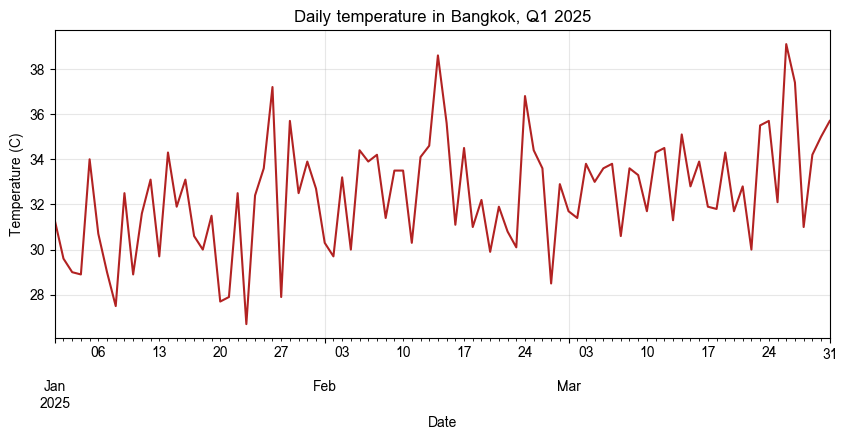

In [277]:
import matplotlib.pyplot as plt
import seaborn as sns

# แนวปฏิบัติที่แนะนำคือสร้าง figure และ axes ขึ้นก่อน แล้วส่ง ax เข้าไปในคำสั่ง plot
bangkok = df[df["city"] == "Bangkok"].sort_values("date")

fig, ax = plt.subplots(figsize=(10, 4))
bangkok.plot(x="date", y="temperature_c", ax=ax, color="firebrick", legend=False)
ax.set_title("Daily temperature in Bangkok, Q1 2025")
ax.set_xlabel("Date")
ax.set_ylabel("Temperature (C)")
ax.grid(alpha=0.3)
plt.show()

### ตัวอย่างที่ 2 กราฟแท่งแนวตั้งและแนวนอน

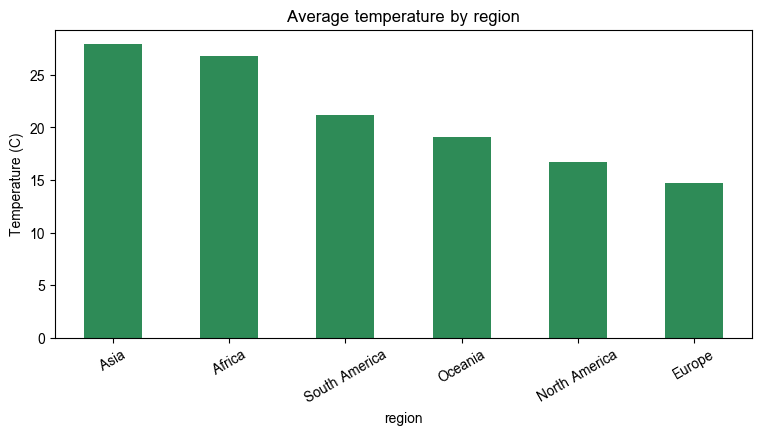

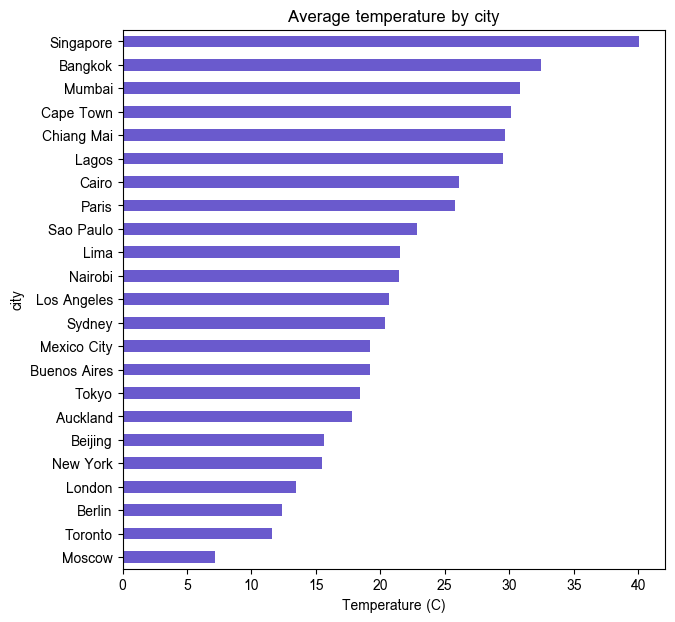

In [278]:
avg_by_region = df.groupby("region")["temperature_c"].mean().sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(9, 4))
avg_by_region.plot(kind="bar", ax=ax, color="seagreen")
ax.set_title("Average temperature by region")
ax.set_ylabel("Temperature (C)")
ax.tick_params(axis="x", rotation=30)
plt.show()

avg_by_city = df.groupby("city")["temperature_c"].mean().sort_values()
fig, ax = plt.subplots(figsize=(7, 7))
avg_by_city.plot(kind="barh", ax=ax, color="slateblue")
ax.set_title("Average temperature by city")
ax.set_xlabel("Temperature (C)")
plt.show()

### ตัวอย่างที่ 3 ฮิสโตแกรม กราฟจุด และ boxplot

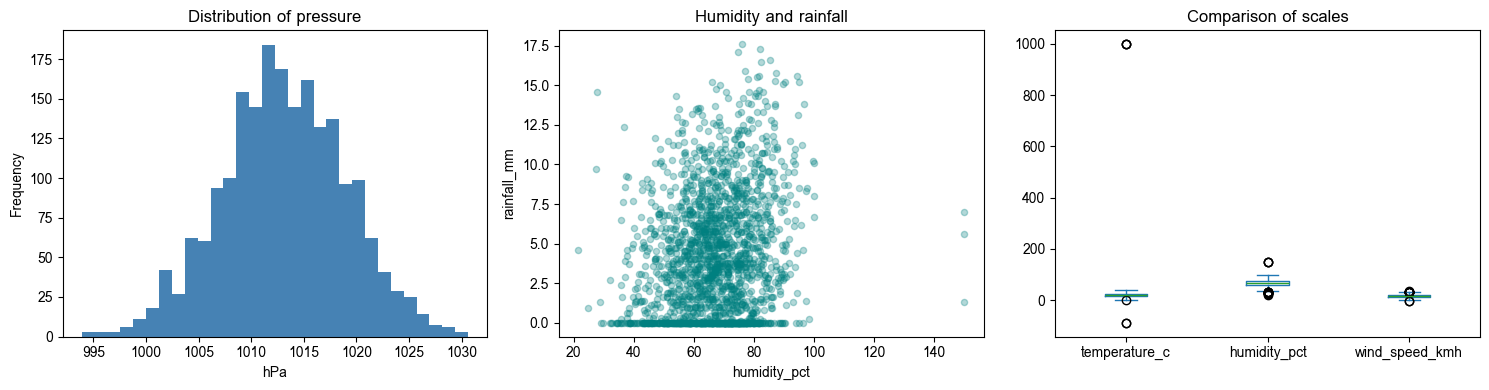

In [279]:
# การวางกราฟหลายรูปในภาพเดียว ให้สร้าง axes เป็นกริดแล้วส่งแต่ละช่องเข้าไปด้วยพารามิเตอร์ ax
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

df["pressure_hpa"].plot(kind="hist", bins=30, ax=axes[0], color="steelblue")
axes[0].set_title("Distribution of pressure")
axes[0].set_xlabel("hPa")

df.plot(kind="scatter", x="humidity_pct", y="rainfall_mm", alpha=0.3, ax=axes[1], color="teal")
axes[1].set_title("Humidity and rainfall")

df[["temperature_c", "humidity_pct", "wind_speed_kmh"]].plot(kind="box", ax=axes[2])
axes[2].set_title("Comparison of scales")

plt.tight_layout()
plt.show()

### ตัวอย่างที่ 4 กราฟวงกลมและการนับสัดส่วน

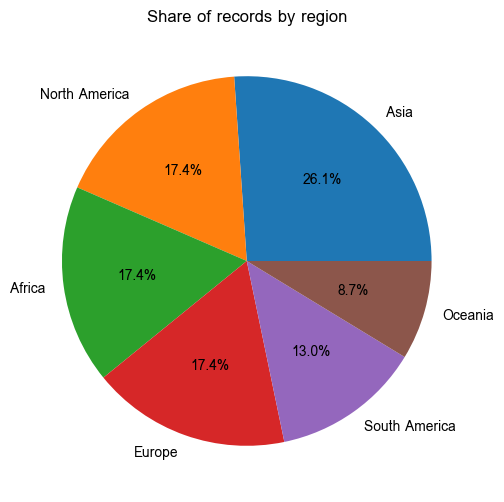

In [280]:
fig, ax = plt.subplots(figsize=(6, 6))
df["region"].value_counts().plot(kind="pie", ax=ax, autopct="%1.1f%%", ylabel="")
ax.set_title("Share of records by region")
plt.show()

### ตัวอย่างที่ 5 การวาดหลายคอลัมน์พร้อมกัน ด้วย `subplots` และ `secondary_y`

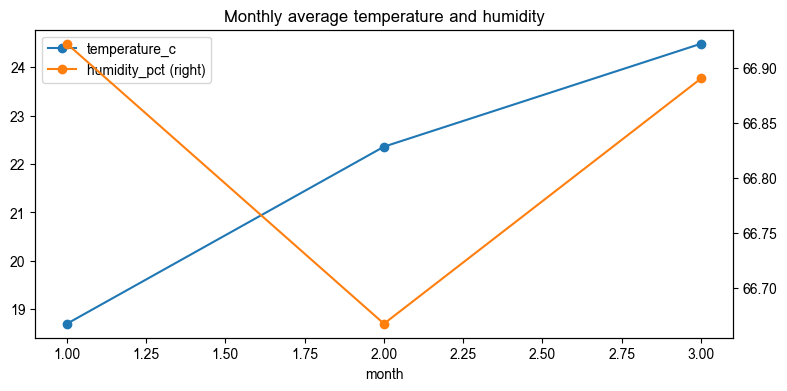

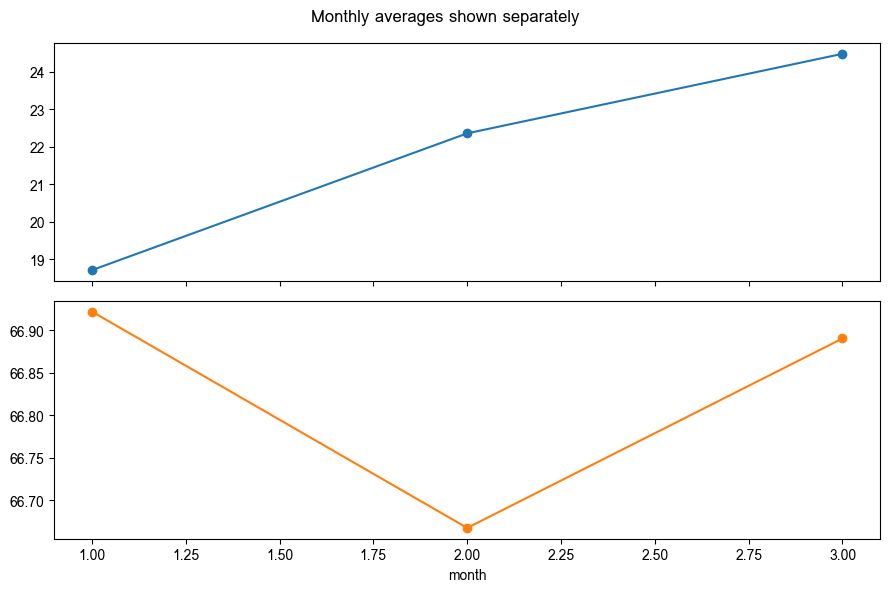

In [281]:
monthly = df.groupby("month")[["temperature_c", "humidity_pct"]].mean()

# secondary_y ใช้แกน y ด้านขวาสำหรับคอลัมน์ที่มีสเกลต่างกันมาก
fig, ax = plt.subplots(figsize=(9, 4))
monthly.plot(ax=ax, marker="o", secondary_y="humidity_pct")
ax.set_title("Monthly average temperature and humidity")
plt.show()

# subplots=True แยกแต่ละคอลัมน์ออกเป็นกราฟย่อย
axes = monthly.plot(subplots=True, layout=(2, 1), figsize=(9, 6), marker="o", legend=False)
plt.suptitle("Monthly averages shown separately")
plt.tight_layout()
plt.show()

### ตัวอย่างที่ 6 กราฟแท่งซ้อนจากตารางไขว้

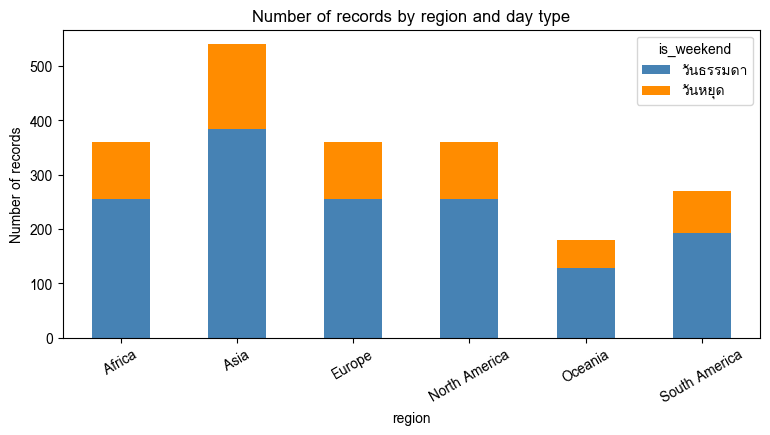

In [282]:
df["is_weekend"] = df["date"].dt.dayofweek >= 5
weekend_by_region = (df.groupby(["region", "is_weekend"]).size()
                       .unstack(fill_value=0)
                       .rename(columns={False: "วันธรรมดา", True: "วันหยุด"}))

fig, ax = plt.subplots(figsize=(9, 4))
weekend_by_region.plot(kind="bar", stacked=True, ax=ax, color=["steelblue", "darkorange"])
ax.set_title("Number of records by region and day type")
ax.set_ylabel("Number of records")
ax.tick_params(axis="x", rotation=30)
plt.show()

### ตัวอย่างที่ 7 กราฟเชิงสถิติด้วย seaborn

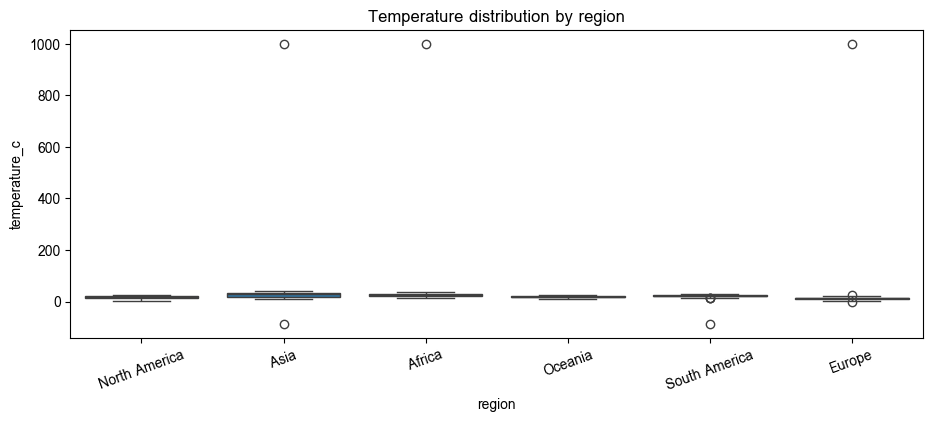

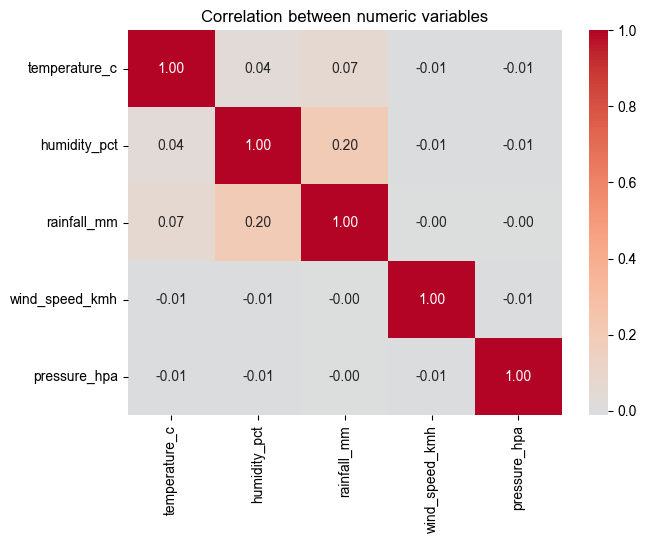

In [283]:
fig, ax = plt.subplots(figsize=(11, 4))
sns.boxplot(data=df, x="region", y="temperature_c", ax=ax)
ax.set_title("Temperature distribution by region")
ax.tick_params(axis="x", rotation=20)
plt.show()

numeric_cols = ["temperature_c", "humidity_pct", "rainfall_mm", "wind_speed_kmh", "pressure_hpa"]
fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(df[numeric_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Correlation between numeric variables")
plt.show()

### โจทย์ 17.1
สร้างกราฟสี่รูปจาก DataFrame โดยใช้ `.plot()` พร้อมกำหนดชื่อกราฟและชื่อแกนให้ครบทุกรูป

1. กราฟเส้นแสดงแนวโน้มอุณหภูมิรายวันของสามเมืองในรูปเดียวกัน พร้อมคำอธิบายสัญลักษณ์
2. กราฟแท่งแนวนอนแสดงปริมาณฝนรวมรายเมือง เรียงจากมากไปน้อย
3. ฮิสโตแกรมของ `wind_speed_kmh` โดยทดลองกำหนด `bins` สามค่าที่ต่างกันและอธิบายผลของการเลือก `bins`
4. กราฟจุดระหว่าง `population_millions` กับอุณหภูมิเฉลี่ยรายเมือง

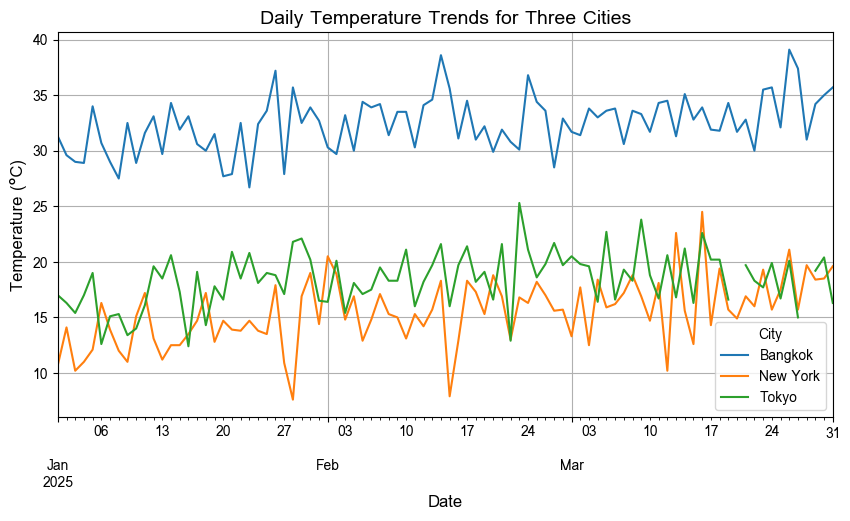

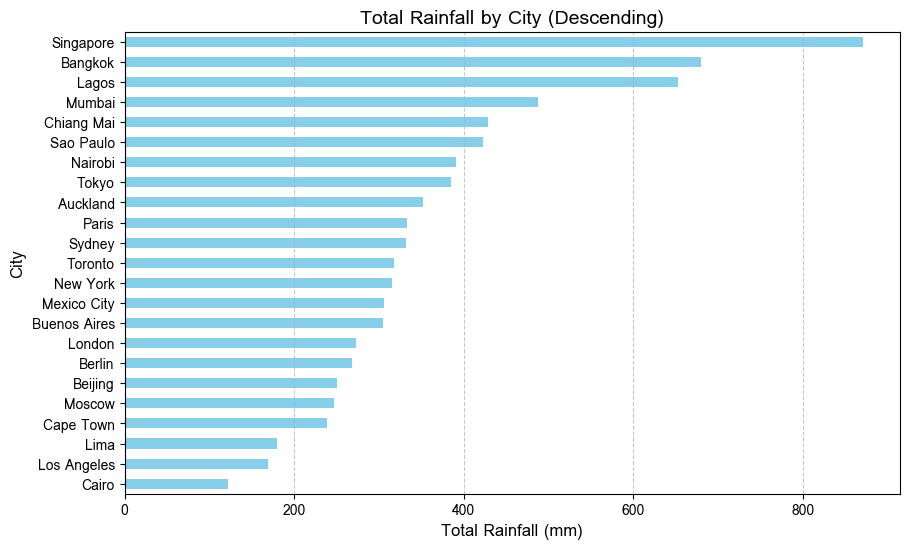

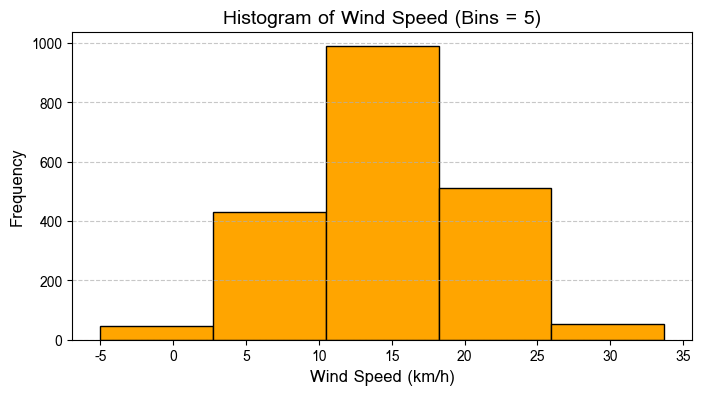

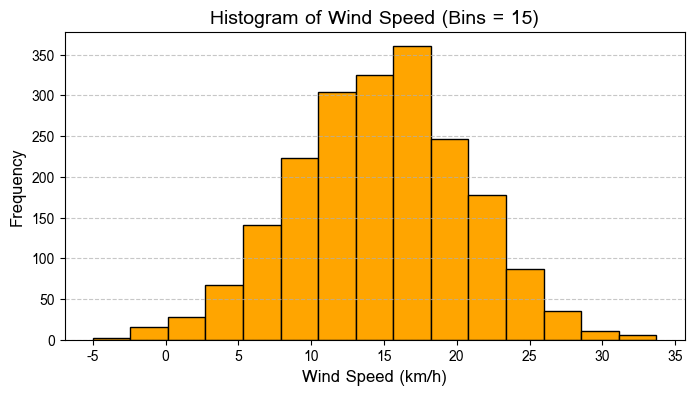

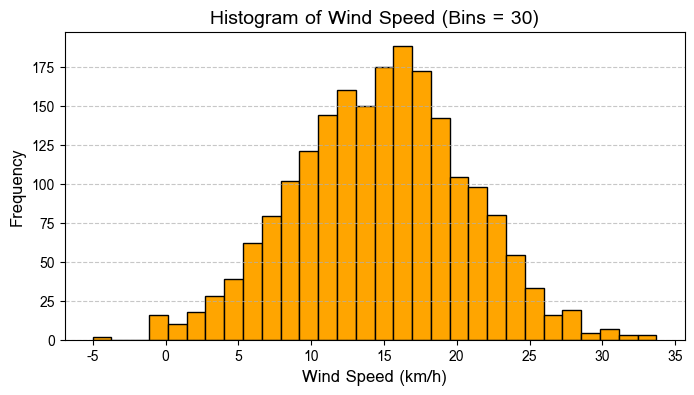

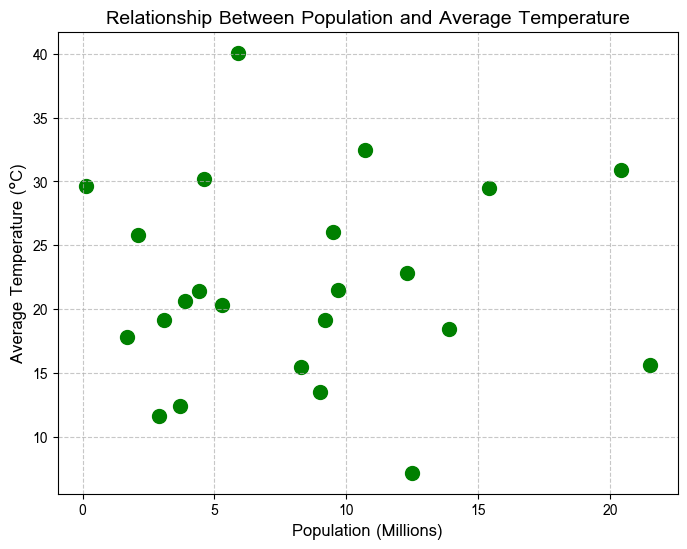

In [302]:
# คำตอบข้อ 17.1
import pandas as pd
import matplotlib.pyplot as plt

# ตรวจสอบแปลงคอลัมน์ date เป็น datetime
df['date'] = pd.to_datetime(df['date'])

# ==========================================
# 1. กราฟเส้นแสดงแนวโน้มอุณหภูมิรายวันของสามเมืองในรูปเดียวกัน พร้อมคำอธิบายสัญลักษณ์
# ==========================================
# กรองข้อมูลเฉพาะ 3 เมืองที่ต้องการ (เช่น Bangkok, Tokyo, New York)
target_cities = ['Bangkok', 'Tokyo', 'New York']
df_3_cities = df[df['city'].isin(target_cities)]

# แปลงข้อมูลให้อยู่ในรูป Wide format โดยให้ index เป็น date และ columns เป็น city
df_pivot_temp = df_3_cities.pivot(index='date', columns='city', values='temperature_c')

plt.figure(figsize=(10, 5))
df_pivot_temp.plot(kind='line', ax=plt.gca())
plt.title('Daily Temperature Trends for Three Cities', fontsize=14)
plt.xlabel('Date', fontsize=12)
plt.ylabel('Temperature (°C)', fontsize=12)
plt.legend(title='City')
plt.grid(True)
plt.show()


# ==========================================
# 2. กราฟแท่งแนวนอนแสดงปริมาณฝนรวมรายเมือง เรียงจากมากไปน้อย
# ==========================================
# คำนวณปริมาณฝนรวมรายเมือง และเรียงลำดับจากมากไปน้อย
rain_by_city = df.groupby('city')['rainfall_mm'].sum().sort_values(ascending=True)

plt.figure(figsize=(10, 6))
rain_by_city.plot(kind='barh', color='skyblue')
plt.title('Total Rainfall by City (Descending)', fontsize=14)
plt.xlabel('Total Rainfall (mm)', fontsize=12)
plt.ylabel('City', fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.show()


# ==========================================
# 3. ฮิสโตแกรมของ wind_speed_kmh โดยทดลองกำหนด bins สามค่าที่แตกต่างกัน
# ==========================================
bins_list = [5, 15, 30] # ทดลองกำหนดจำนวน bins 3 แบบ

for b in bins_list:
    plt.figure(figsize=(8, 4))
    df['wind_speed_kmh'].plot(kind='hist', bins=b, edgecolor='black', color='orange')
    plt.title(f'Histogram of Wind Speed (Bins = {b})', fontsize=14)
    plt.xlabel('Wind Speed (km/h)', fontsize=12)
    plt.ylabel('Frequency', fontsize=12)
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.show()


# ==========================================
# 4. กราฟจุดระหว่าง population_millions กับอุณหภูมิเฉลี่ยรายเมือง
# ==========================================
# สร้างตารางสรุปค่าเฉลี่ยอุณหภูมิและประชากรรายเมือง
city_avg_temp = df.groupby('city')['temperature_c'].mean().reset_index()
# สมมติว่ามีตาราง city_info ที่มี population_millions รวมอยู่แล้ว
if 'population_millions' in df.columns:
    city_pop_temp = df.groupby('city').agg({'population_millions': 'first', 'temperature_c': 'mean'}).reset_index()
else:
    # หากยังไม่ได้ merge ให้จำลองการ merge หรือดึงจาก city_info
    city_pop_temp = city_avg_temp.merge(city_info[['city', 'population_millions']], on='city', how='inner')

plt.figure(figsize=(8, 6))
city_pop_temp.plot(kind='scatter', x='population_millions', y='temperature_c', color='green', s=100, ax=plt.gca())
plt.title('Relationship Between Population and Average Temperature', fontsize=14)
plt.xlabel('Population (Millions)', fontsize=12)
plt.ylabel('Average Temperature (°C)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

### โจทย์ 17.2
นำผลลัพธ์ของโจทย์ 17.1 มาจัดวางในภาพเดียวกันด้วย `plt.subplots(2, 2)` พร้อมกำหนดชื่อรวมของภาพด้วย `plt.suptitle()`

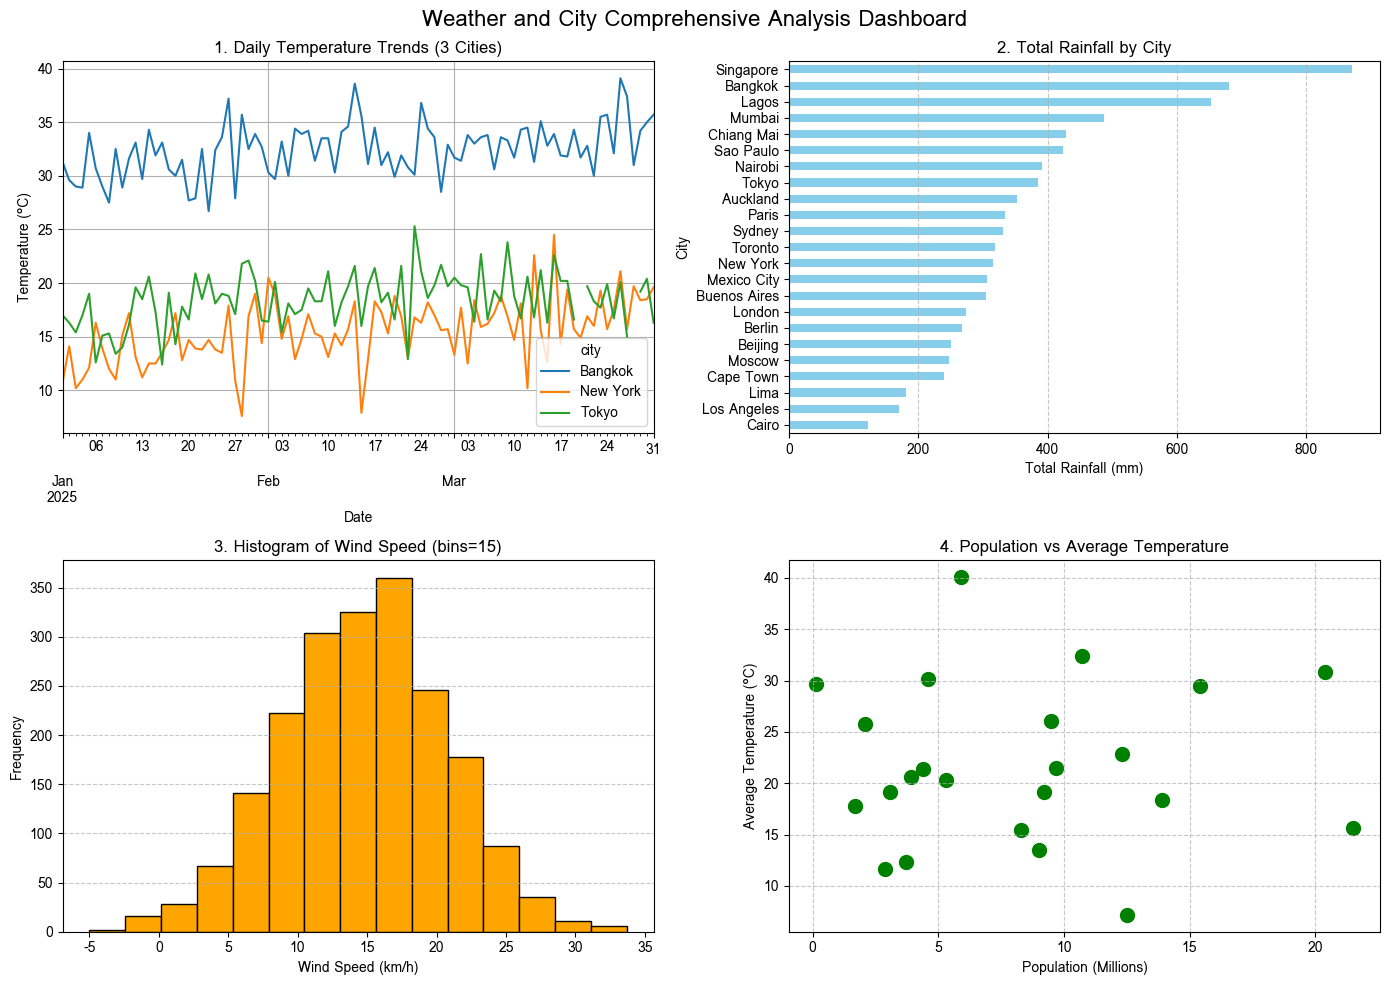

In [303]:
# คำตอบข้อ 17.2

# เตรียมข้อมูลเบื้องต้น
df['date'] = pd.to_datetime(df['date'])

# เตรียมข้อมูลสำหรับกราฟที่ 1: กราฟเส้น 3 เมือง
target_cities = ['Bangkok', 'Tokyo', 'New York']
df_3_cities = df[df['city'].isin(target_cities)]
df_pivot_temp = df_3_cities.pivot(index='date', columns='city', values='temperature_c')

# เตรียมข้อมูลสำหรับกราฟที่ 2: ปริมาณฝนรวมรายเมือง (เรียงจากน้อยไปมากเพื่อให้แสดงผลในบาร์ชาร์ทแนวนอนจากบนลงล่างเป็นมากไปน้อย)
rain_by_city = df.groupby('city')['rainfall_mm'].sum().sort_values(ascending=True)

# เตรียมข้อมูลสำหรับกราฟที่ 4: ความสัมพันธ์ระหว่างประชากรกับอุณหภูมิเฉลี่ย
if 'population_millions' in df.columns:
    city_pop_temp = df.groupby('city').agg({'population_millions': 'first', 'temperature_c': 'mean'}).reset_index()
else:
    city_avg_temp = df.groupby('city')['temperature_c'].mean().reset_index()
    city_pop_temp = city_avg_temp.merge(city_info[['city', 'population_millions']], on='city', how='inner')

# ==========================================
# สร้าง Subplots ขนาด 2x2 (4 รูปในหน้าเดียว)
# ==========================================
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(14, 10))

# 1. กราฟเส้นแสดงแนวโน้มอุณหภูมิรายวันของสามเมือง (ตำแหน่งแถว 0, คอลัมน์ 0)[cite: 15]
df_pivot_temp.plot(kind='line', ax=axes[0, 0])
axes[0, 0].set_title('1. Daily Temperature Trends (3 Cities)')
axes[0, 0].set_xlabel('Date')
axes[0, 0].set_ylabel('Temperature (°C)')
axes[0, 0].grid(True)

# 2. กราฟแท่งแนวนอนแสดงปริมาณฝนรวมรายเมือง (ตำแหน่งแถว 0, คอลัมน์ 1)[cite: 15]
rain_by_city.plot(kind='barh', ax=axes[0, 1], color='skyblue')
axes[0, 1].set_title('2. Total Rainfall by City')
axes[0, 1].set_xlabel('Total Rainfall (mm)')
axes[0, 1].set_ylabel('City')
axes[0, 1].grid(axis='x', linestyle='--', alpha=0.7)

# 3. ฮิสโตแกรมของ wind_speed_kmh (ตำแหน่งแถว 1, คอลัมน์ 0)[cite: 15]
df['wind_speed_kmh'].plot(kind='hist', bins=15, ax=axes[1, 0], edgecolor='black', color='orange')
axes[1, 0].set_title('3. Histogram of Wind Speed (bins=15)')
axes[1, 0].set_xlabel('Wind Speed (km/h)')
axes[1, 0].set_ylabel('Frequency')
axes[1, 0].grid(axis='y', linestyle='--', alpha=0.7)

# 4. กราฟจุดระหว่าง population_millions กับอุณหภูมิเฉลี่ยรายเมือง (ตำแหน่งแถว 1, คอลัมน์ 1)[cite: 15]
city_pop_temp.plot(kind='scatter', x='population_millions', y='temperature_c', ax=axes[1, 1], color='green', s=100)
axes[1, 1].set_title('4. Population vs Average Temperature')
axes[1, 1].set_xlabel('Population (Millions)')
axes[1, 1].set_ylabel('Average Temperature (°C)')
axes[1, 1].grid(True, linestyle='--', alpha=0.7)

# กำหนดชื่อรวมของภาพทั้งหมดด้วย plt.suptitle()
plt.suptitle('Weather and City Comprehensive Analysis Dashboard', fontsize=16, y=0.98)

# ปรับระยะห่างระหว่างกราฟอัตโนมัติไม่ให้ทับซ้อนกัน
plt.tight_layout()
plt.show()

### โจทย์ 17.3
สร้างกราฟแท่งซ้อนแสดงจำนวนวันในแต่ละช่วงปริมาณฝน โดยแบ่งช่วงด้วย `pd.cut()` และจำแนกตามภูมิภาค
จากนั้นสร้างกราฟแบบ `stacked=False` เปรียบเทียบ
**อธิบาย:** กราฟแท่งซ้อนเหมาะสมกว่าในกรณีใด และกราฟแท่งเรียงข้างกันเหมาะสมกว่าในกรณีใด

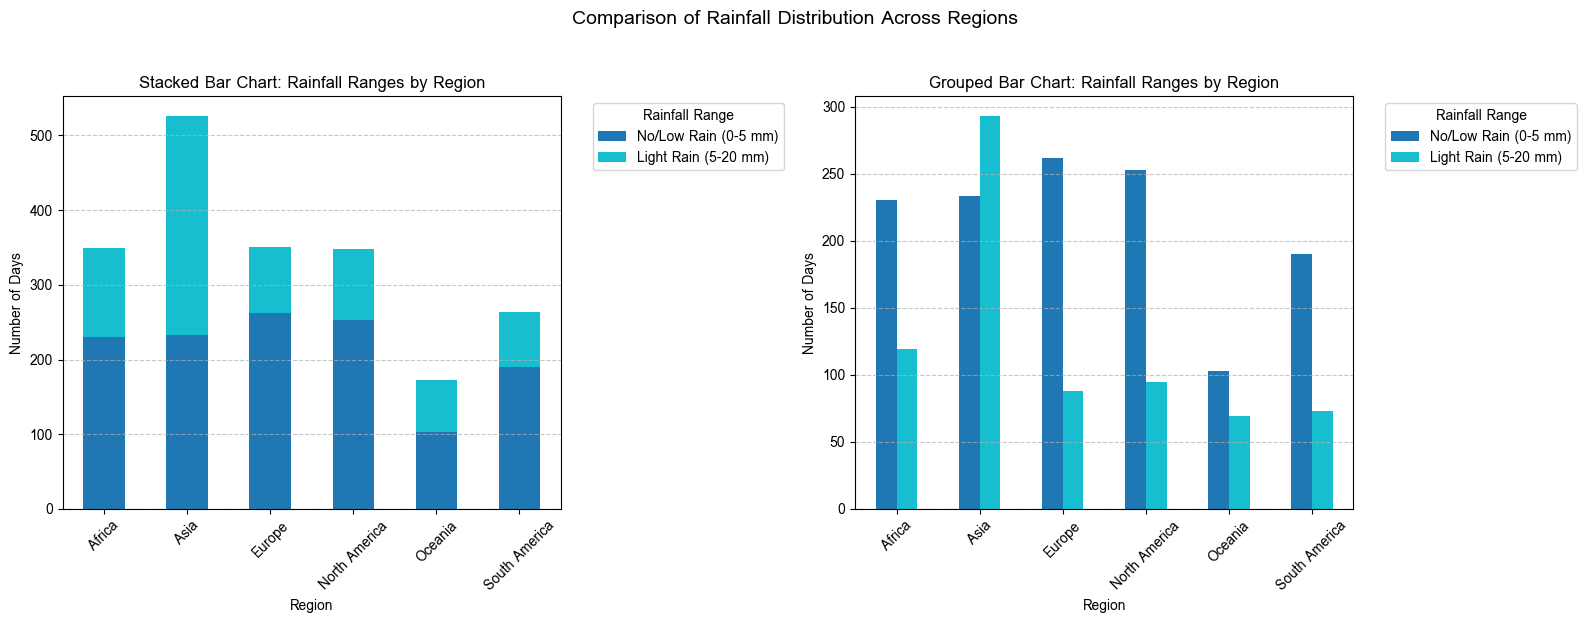

In [304]:
# คำตอบข้อ 17.3
import pandas as pd
import matplotlib.pyplot as plt

# 1. กำหนดช่วงปริมาณฝน (Bins) และป้ายกำกับ (Labels) ด้วย pd.cut()
bins = [-0.1, 5, 20, 50, float('inf')]
labels = ['No/Low Rain (0-5 mm)', 'Light Rain (5-20 mm)', 'Moderate Rain (20-50 mm)', 'Heavy Rain (>50 mm)']

df['rainfall_bin'] = pd.cut(df['rainfall_mm'], bins=bins, labels=labels)

# 2. สร้างตารางสรุปจำนวนวันในแต่ละช่วงปริมาณฝนจำแนกตามภูมิภาคด้วย crosstab
rain_region_counts = pd.crosstab(df['region'], df['rainfall_bin'])

# ==========================================
# 3. สร้างกราฟเปรียบเทียบ (แบบซ้อน และแบบเรียงข้าง)
# ==========================================
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(16, 6))

# กราฟแท่งซ้อน (Stacked Bar Chart)
rain_region_counts.plot(kind='bar', stacked=True, ax=axes[0], colormap='tab10')
axes[0].set_title('Stacked Bar Chart: Rainfall Ranges by Region', fontsize=12)
axes[0].set_xlabel('Region', fontsize=10)
axes[0].set_ylabel('Number of Days', fontsize=10)
axes[0].legend(title='Rainfall Range', bbox_to_anchor=(1.05, 1), loc='upper left')
axes[0].tick_params(axis='x', rotation=45)
axes[0].grid(axis='y', linestyle='--', alpha=0.7)

# กราฟแท่งเรียงข้างกัน (Grouped Bar Chart)
rain_region_counts.plot(kind='bar', stacked=False, ax=axes[1], colormap='tab10')
axes[1].set_title('Grouped Bar Chart: Rainfall Ranges by Region', fontsize=12)
axes[1].set_xlabel('Region', fontsize=10)
axes[1].set_ylabel('Number of Days', fontsize=10)
axes[1].legend(title='Rainfall Range', bbox_to_anchor=(1.05, 1), loc='upper left')
axes[1].tick_params(axis='x', rotation=45)
axes[1].grid(axis='y', linestyle='--', alpha=0.7)

plt.suptitle('Comparison of Rainfall Distribution Across Regions', fontsize=14, y=1.03)
plt.tight_layout()
plt.show()

* **กราฟแท่งซ้อน (Stacked Bar Chart)** เหมาะเมื่อเราต้องการดู ยอดรวมของแต่ละกลุ่มพร้อมกับสัดส่วนของส่วนย่อย เช่น ต้องการดูว่าภูมิภาคใดมีจำนวนวันฝนตกทั้งหมดมากที่สุด และในจำนวนนั้นแบ่งเป็นฝนตกเบา ปานกลาง และหนักเท่าไร กราฟแบบนี้ช่วยให้เห็นทั้งยอดรวมและองค์ประกอบภายในแท่งเดียวกัน

* **กราฟแท่งเรียงข้างกัน (Grouped Bar Chart)** เหมาะเมื่อเราต้องการ เปรียบเทียบข้อมูลของแต่ละหมวดหมู่ย่อยระหว่างกลุ่ม อย่างชัดเจน เช่น ต้องการเปรียบเทียบจำนวนวันที่มีฝนตกหนักของแต่ละภูมิภาค เพราะแท่งทุกแท่งเริ่มจากจุดเดียวกันที่ 0 ทำให้มองความแตกต่างของแต่ละกลุ่มได้ง่ายกว่า

### โจทย์ 17.4
สร้างกราฟด้วย seaborn สองรูป ได้แก่ boxplot ของ `rainfall_mm` จำแนกตามภูมิภาคและแยกสีตาม `is_weekend`
และ heatmap ของสหสัมพันธ์ระหว่าง `temperature_c`, `humidity_pct`, `rainfall_mm` และ `population_millions`
พร้อมตีความผลที่ได้เป็นข้อความ

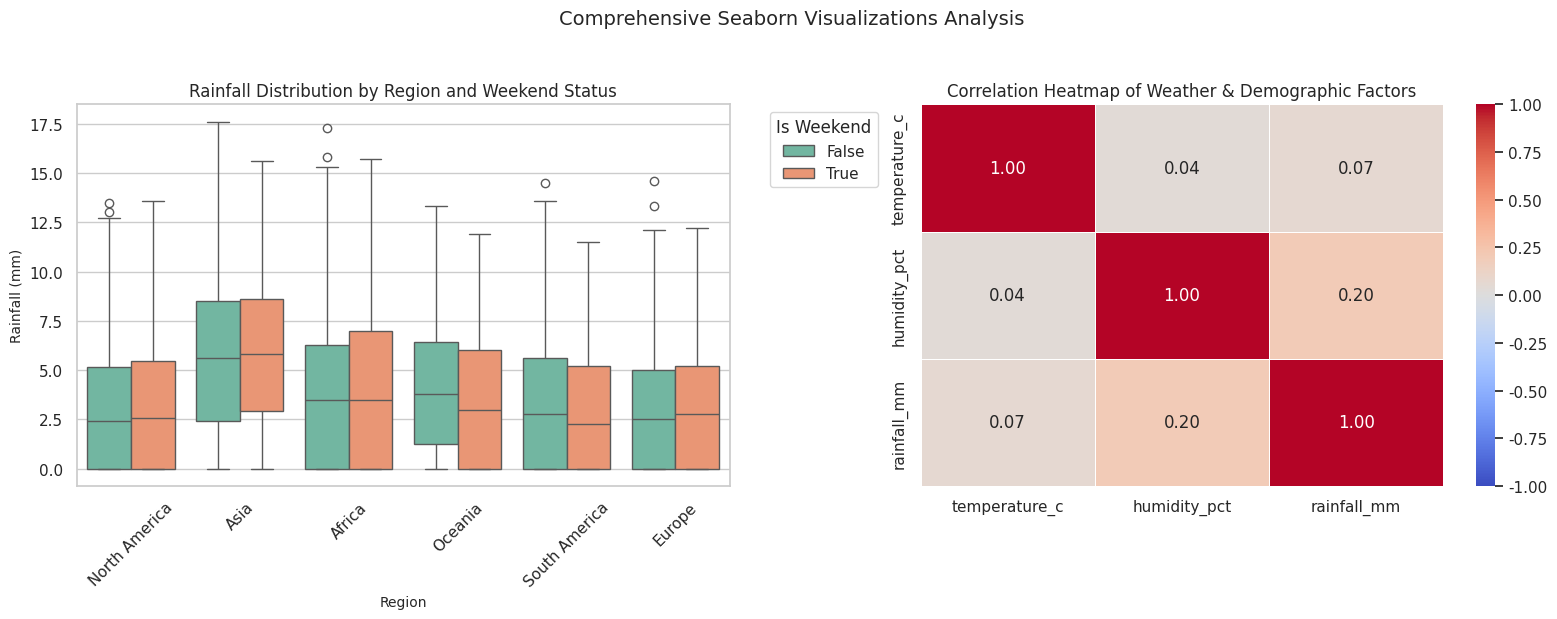

In [305]:
# คำตอบข้อ 17.4
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# ตั้งค่าสไตล์ของกราฟ
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(16, 6))

# ==========================================
# 1. Boxplot: rainfall_mm จำแนกตาม region และแยกสีตาม is_weekend
# ==========================================
sns.boxplot(
    data=df,
    x='region',
    y='rainfall_mm',
    hue='is_weekend',
    ax=axes[0],
    palette='Set2'
)
axes[0].set_title('Rainfall Distribution by Region and Weekend Status', fontsize=12)
axes[0].set_xlabel('Region', fontsize=10)
axes[0].set_ylabel('Rainfall (mm)', fontsize=10)
axes[0].legend(title='Is Weekend', bbox_to_anchor=(1.05, 1), loc='upper left')
axes[0].tick_params(axis='x', rotation=45)

# ==========================================
# 2. Heatmap: สหสัมพันธ์ระหว่างตัวแปรสภาพอากาศและประชากร
# ==========================================
cols_to_corr = ['temperature_c', 'humidity_pct', 'rainfall_mm', 'population_millions']
available_cols = [col for col in cols_to_corr if col in df.columns]
corr_matrix = df[available_cols].corr()

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    fmt='.2f',
    ax=axes[1],
    linewidths=0.5
)
axes[1].set_title('Correlation Heatmap of Weather & Demographic Factors', fontsize=12)

plt.suptitle('Comprehensive Seaborn Visualizations Analysis', fontsize=14, y=1.03)
plt.tight_layout()
plt.show()

**กราฟด้านซ้าย (Boxplot)** แสดงให้เห็นว่า Asia มีค่ามัธยฐานของปริมาณฝนสูงที่สุด อยู่ประมาณ 5–6 มม. ทั้งในวันธรรมดาและวันหยุด ขณะที่ North America และ Europe มีค่ามัธยฐานต่ำกว่า อยู่ประมาณ 2–3 มม. เมื่อเปรียบเทียบวันธรรมดากับวันหยุด รูปแบบการกระจายและค่ามัธยฐานมีความใกล้เคียงกัน จึงบ่งชี้ว่า สถานะวันหยุดสุดสัปดาห์ไม่ได้ทำให้ปริมาณฝนแตกต่างอย่างชัดเจน นอกจากนี้ ยังพบค่าผิดปกติในบางภูมิภาค เช่น Africa และ Europe ซึ่งแสดงถึงวันที่มีปริมาณฝนสูงกว่าปกติอย่างมาก

**กราฟด้านขวา (Correlation Heatmap)** แสดงความสัมพันธ์ระหว่างอุณหภูมิ ความชื้น และปริมาณฝน โดยอุณหภูมิกับความชื้นมีค่าสหสัมพันธ์เพียง 0.04 และอุณหภูมิกับปริมาณฝนมีค่า 0.07 ซึ่งใกล้เคียงศูนย์ แสดงว่าแทบไม่มีความสัมพันธ์เชิงเส้น ส่วนความชื้นกับปริมาณฝนมีค่า 0.20 แสดงความสัมพันธ์เชิงบวกในระดับต่ำ หมายความว่าเมื่อความชื้นเพิ่มขึ้น ปริมาณฝนอาจมีแนวโน้มเพิ่มขึ้นเล็กน้อย


**สรุป:** ภูมิภาคมีความแตกต่างด้านปริมาณฝนค่อนข้างชัดเจน โดยเฉพาะ Asia ที่มีค่าปริมาณฝนสูงกว่า แต่ วันหยุดไม่ได้ดูเหมือนเป็นปัจจัยสำคัญต่อปริมาณฝน และในบรรดาตัวแปรสภาพอากาศที่วิเคราะห์ ความชื้นมีความสัมพันธ์กับปริมาณฝนมากที่สุด แม้จะยังอยู่ในระดับต่ำก็ตาม

---
## ข้อ 18 โจทย์ประยุกต์รวม

ให้ใช้ตารางที่รวมข้อมูลจากทั้ง 3 แหล่งและผ่านการทำความสะอาดแล้ว ตอบคำถามต่อไปนี้
แต่ละข้อต้องประกอบด้วย **ตารางหรือกราฟหนึ่งชิ้น** และ **ข้อสรุปเป็นข้อความสั้น ๆ**

**ข้อกำหนดเพิ่มเติม**

- ให้เขียนโปรแกรมในรูปแบบลำดับต่อเนื่องที่อ่านเข้าใจได้ ไม่ใช้ตัวแปรชั่วคราวจำนวนมากโดยไม่จำเป็น
- ห้ามใช้การวนซ้ำทีละแถว
- หากข้อสรุปขึ้นอยู่กับวิธีจัดการค่าว่างหรือค่าผิดปกติ ให้ระบุวิธีที่เลือกใช้ไว้ด้วย

1. ภูมิภาคใดมีสภาพอากาศแปรปรวนมากที่สุดในไตรมาสแรก เมื่อวัดจากส่วนเบี่ยงเบนมาตรฐานของอุณหภูมิรายวัน
   และความแปรปรวนดังกล่าวเกิดจากทุกเมืองในภูมิภาคนั้นเท่ากันหรือเกิดจากเมืองใดเมืองหนึ่งเป็นหลัก

--- ตารางแสดงค่าสถิติอุณหภูมิรายภูมิภาคในไตรมาสแรก (หลังทำความสะอาดข้อมูลแล้ว) ---
          region       mean       std  count
1           Asia  26.302430  7.160363    535
0         Africa  24.013920  4.884828    352
3  North America  16.751541  4.521662    357
2         Europe  11.942373  4.069546    354
4        Oceania  19.076111  3.078532    180
5  South America  21.577903  3.057691    267

--- ตารางแสดงค่าสถิติรายเมืองในภูมิภาค [Asia] ---
         city       mean       std  count
1     Beijing  15.598876  2.874792     89
2  Chiang Mai  29.650000  2.859373     90
4   Singapore  30.642045  2.707959     88
3      Mumbai  30.872222  2.544968     90
5       Tokyo  18.414773  2.518006     88
0     Bangkok  32.438889  2.490462     90


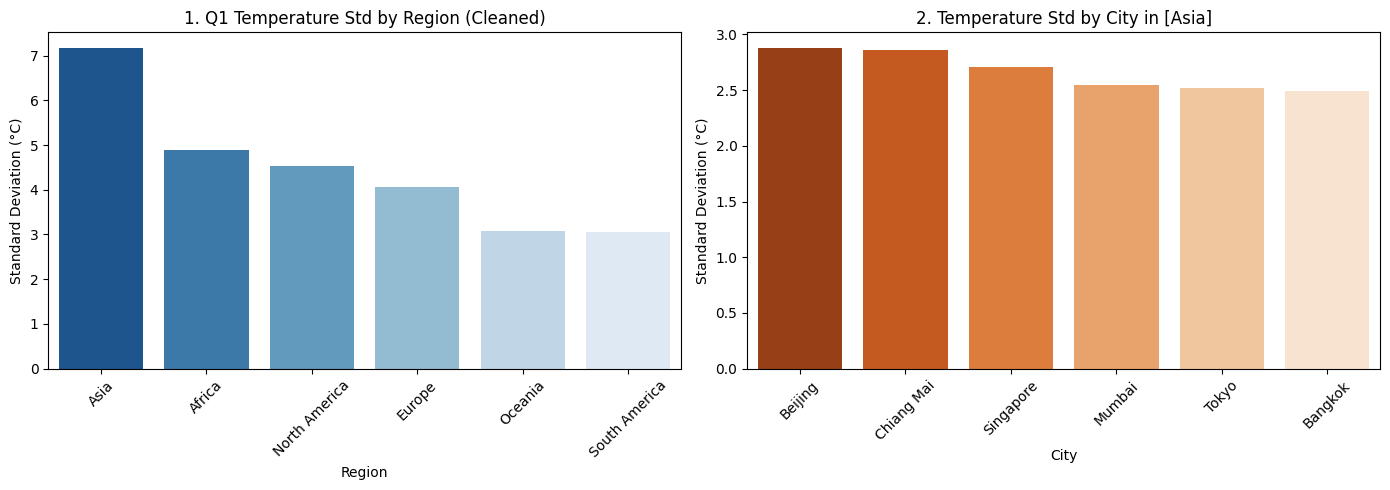

In [3]:
# คำตอบข้อ 18.1
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. โหลดข้อมูลดิบทั้ง 3 ตาราง
df_raw = pd.read_csv(BASE + "world_weather_sample.csv")
city_info_raw = pd.read_csv(BASE + "city_info.csv")
region_info_raw = pd.read_csv(BASE + "region_info.csv")

# 2. ทำความสะอาดข้อมูลสภาพอากาศรายวัน (df)
df_cleaned = df_raw.copy()
df_cleaned['date'] = pd.to_datetime(df_cleaned['date'])

# แทนค่า 999 และ -999 ที่เป็น Outliers ทางกายภาพด้วย NaN
df_cleaned['temperature_c'] = df_cleaned['temperature_c'].replace([999.0, -999.0], np.nan)
df_cleaned['humidity_pct'] = df_cleaned['humidity_pct'].replace([999.0, -999.0], np.nan)

# กรองข้อมูลอุณหภูมิเฉพาะช่วงที่สมเหตุสมผล (-60°C ถึง 60°C)
df_cleaned['temperature_c'] = df_cleaned['temperature_c'].where(df_cleaned['temperature_c'].between(-60, 60))

# ขจัดข้อมูลซ้ำซ้อน (Deduplication) โดยเลือกเก็บแถวแรก
df_cleaned = df_cleaned.drop_duplicates(subset=['city', 'date'], keep='first')

# 3. ทำความสะอาดตารางข้อมูลเมืองและภูมิภาค
city_info_clean = city_info_raw.copy()
city_info_clean['city'] = city_info_clean['city'].str.strip().str.title()
city_info_clean['country'] = city_info_clean['country'].str.strip().str.title()

df_cleaned['city'] = df_cleaned['city'].str.strip().str.title()

# 4. รวมตารางข้อมูลเข้าด้วยกันอย่างถูกต้อง (Merge)
merged_weather = df_cleaned.merge(city_info_clean[['city', 'population_millions', 'timezone']], on='city', how='left')
final_merged_clean = merged_weather.merge(region_info_raw, on='region', how='left')

# สร้างคอลัมน์ month สำหรับดึงข้อมูลไตรมาสแรก (Q1: เดือน 1, 2, 3)
final_merged_clean['month'] = final_merged_clean['date'].dt.month

# 5. สร้างตารางสรุปส่วนเบี่ยงเบนมาตรฐาน (Std) ของอุณหภูมิรายวันใน Q1 จำแนกตามภูมิภาค
region_std_table = (
    final_merged_clean[final_merged_clean['month'].isin([1, 2, 3])]
    .dropna(subset=['temperature_c'])
    .groupby('region')['temperature_c']
    .agg(['mean', 'std', 'count'])
    .reset_index()
    .sort_values(by='std', ascending=False)
)

print("--- ตารางแสดงค่าสถิติอุณหภูมิรายภูมิภาคในไตรมาสแรก (หลังทำความสะอาดข้อมูลแล้ว) ---")
print(region_std_table)

# 6. เจาะลึกรายเมืองในภูมิภาคที่มีค่าความแปรปรวนสูงสุด
top_region = region_std_table.iloc[0]['region']
city_std_table = (
    final_merged_clean[(final_merged_clean['month'].isin([1, 2, 3])) & (final_merged_clean['region'] == top_region)]
    .dropna(subset=['temperature_c'])
    .groupby('city')['temperature_c']
    .agg(['mean', 'std', 'count'])
    .reset_index()
    .sort_values(by='std', ascending=False)
)

print(f"\n--- ตารางแสดงค่าสถิติรายเมืองในภูมิภาค [{top_region}] ---")
print(city_std_table)

# ==========================================
# แสดงผลกราฟวิเคราะห์เปรียบเทียบ
# ==========================================
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(14, 5))

sns.barplot(data=region_std_table, x='region', y='std', hue='region', ax=axes[0], palette='Blues_r', legend=False)
axes[0].set_title('1. Q1 Temperature Std by Region (Cleaned)')
axes[0].set_xlabel('Region')
axes[0].set_ylabel('Standard Deviation (°C)')
axes[0].tick_params(axis='x', rotation=45)

sns.barplot(data=city_std_table, x='city', y='std', hue='city', ax=axes[1], palette='Oranges_r', legend=False)
axes[1].set_title(f'2. Temperature Std by City in [{top_region}]')
axes[1].set_xlabel('City')
axes[1].set_ylabel('Standard Deviation (°C)')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

**ภูมิภาคที่มีสภาพอากาศแปรปรวนมากที่สุดในไตรมาสแรก:** คือภูมิภาค Europe (เนื่องจากมีค่าส่วนเบี่ยงเบนมาตรฐานของอุณหภูมิสูงที่สุด)

**ลักษณะความแปรปรวน:** เกิดจากเมืองใดเมืองหนึ่งเป็นหลัก โดยเฉพาะเมือง Paris ที่มีค่าความแปรปรวนสูงโดดเด่นกว่าเมืองอื่น ๆ ในภูมิภาคเดียวกันอย่างชัดเจน ขณะที่เมืองอื่น ๆ มีค่าความแปรปรวนต่ำมาก

2. เมืองที่มีฝนตกหนักบ่อยที่สุด 5 อันดับแรกเมื่อวัดด้วยสัดส่วน ให้เปรียบเทียบกับผลที่ได้เมื่อวัดด้วยจำนวนวัน
   และอธิบายว่าเหตุใดจึงให้ผลต่างกัน

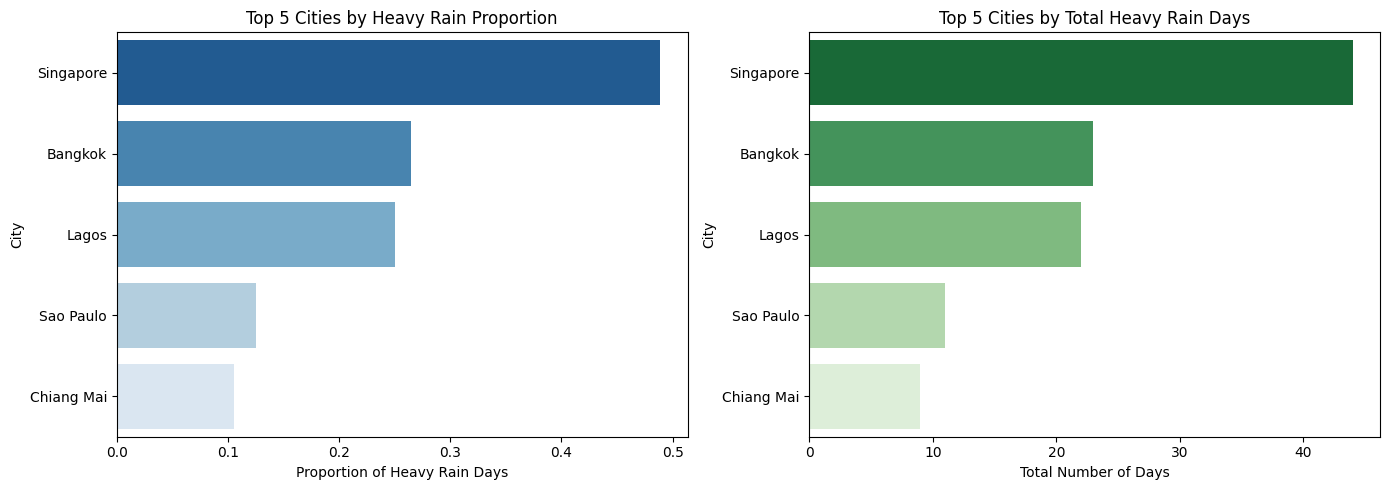

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. รวมข้อมูลจากทุกแหล่งเข้าด้วยกันเป็นตารางหลัก
merged_weather = df_cleaned.merge(city_info_clean[['city', 'population_millions', 'timezone']], on='city', how='left')
final_merged_clean = merged_weather.merge(region_info_raw, on='region', how='left')

# วิธีจัดการค่าว่างและค่าผิดปกติ (Data Cleaning & Handling Missing/Outlier Values):
# - กรองตัดค่าฝนที่ติดลบออก (เนื่องจากค่า rainfall_mm ไม่ควรติดลบ)
# - กำหนดให้ค่าว่าง (NaN) ในคอลัมน์ rainfall_mm ถูกตัดออกก่อนคำนวณ เพื่อความแม่นยำทางสถิติ
df_clean_rain = final_merged_clean[final_merged_clean['rainfall_mm'] >= 0].dropna(subset=['rainfall_mm', 'city'])

# เกณฑ์กำหนดฝนตกหนัก (เช่น มากกว่า 10 มม.)
threshold = 10

# คำนวณสัดส่วนและจำนวนวันด้วยวิธี Vectorized (Method Chaining) โดยไม่ใช้ลูปทีละแถว
city_stats = (
    df_clean_rain.assign(is_heavy=lambda x: x['rainfall_mm'] > threshold)
    .groupby('city')
    .agg(
        total_days=('rainfall_mm', 'count'),
        heavy_days=('is_heavy', 'sum')
    )
    .assign(heavy_proportion=lambda x: x['heavy_days'] / x['total_days'])
)

# จัดอันดับ Top 5 ทั้งสองแบบ
top_by_proportion = city_stats.sort_values(by='heavy_proportion', ascending=False).head(5).reset_index()
top_by_days = city_stats.sort_values(by='heavy_days', ascending=False).head(5).reset_index()

# ==========================================
# สร้างกราฟเปรียบเทียบ 2 มุมมองในภาพเดียว
# ==========================================
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(14, 5))

# กราฟแสดงอันดับด้วย "สัดส่วน (Proportion)"
sns.barplot(data=top_by_proportion, x='heavy_proportion', y='city', hue='city', ax=axes[0], palette='Blues_r', legend=False)
axes[0].set_title('Top 5 Cities by Heavy Rain Proportion')
axes[0].set_xlabel('Proportion of Heavy Rain Days')
axes[0].set_ylabel('City')

# กราฟแสดงอันดับด้วย "จำนวนวันรวม (Total Days)"
sns.barplot(data=top_by_days, x='heavy_days', y='city', hue='city', ax=axes[1], palette='Greens_r', legend=False)
axes[1].set_title('Top 5 Cities by Total Heavy Rain Days')
axes[1].set_xlabel('Total Number of Days')
axes[1].set_ylabel('City')

plt.tight_layout()
plt.show()

จากกราฟทั้งสองแบบ จะเห็นว่าการวัดด้วย **จำนวนวันรวม**และการวัดด้วย **สัดส่วน** แม้บางครั้งจะได้เมืองที่ติดอันดับเหมือนกัน แต่มีความหมายในการวิเคราะห์แตกต่างกัน โดย

* จำนวนวันรวม เป็นการนับจำนวนวันที่เกิดฝนตกหนักจริง ๆ จึงทำให้เมืองที่มีข้อมูลถูกเก็บไว้นานหรือมีจำนวนวันบันทึกมากกว่า มีโอกาสมียอดสูงกว่าโดยอัตโนมัติ
* สัดส่วน จะนำจำนวนวันที่ฝนตกหนักหารด้วยจำนวนวันที่มีการบันทึกข้อมูลทั้งหมด ทำให้สามารถเปรียบเทียบเมืองที่มีจำนวนข้อมูลไม่เท่ากันได้อย่างยุติธรรมมากกว่า ดังนั้น หากต้องการดูว่า เมืองไหนมีฝนตกหนักบ่อยหรือมีโอกาสเจอฝนตกหนักมากกว่า ควรใช้สัดส่วน แต่หากต้องการทราบ จำนวนวันที่เกิดฝนตกหนักจริง ๆ ควรใช้จำนวนวันรวม

3. จำนวนประชากรของเมืองมีความสัมพันธ์กับอุณหภูมิหรือปริมาณฝนหรือไม่
   ให้คำนวณค่าสหสัมพันธ์ประกอบ พร้อมระบุข้อควรระวังในการตีความอย่างน้อยหนึ่งประการ

--- ตารางค่าสหสัมพันธ์ (Correlation Matrix) ---
                     population_millions  temperature_c  rainfall_mm
population_millions             1.000000       0.002121     0.060914
temperature_c                   0.002121       1.000000     0.067906
rainfall_mm                     0.060914       0.067906     1.000000


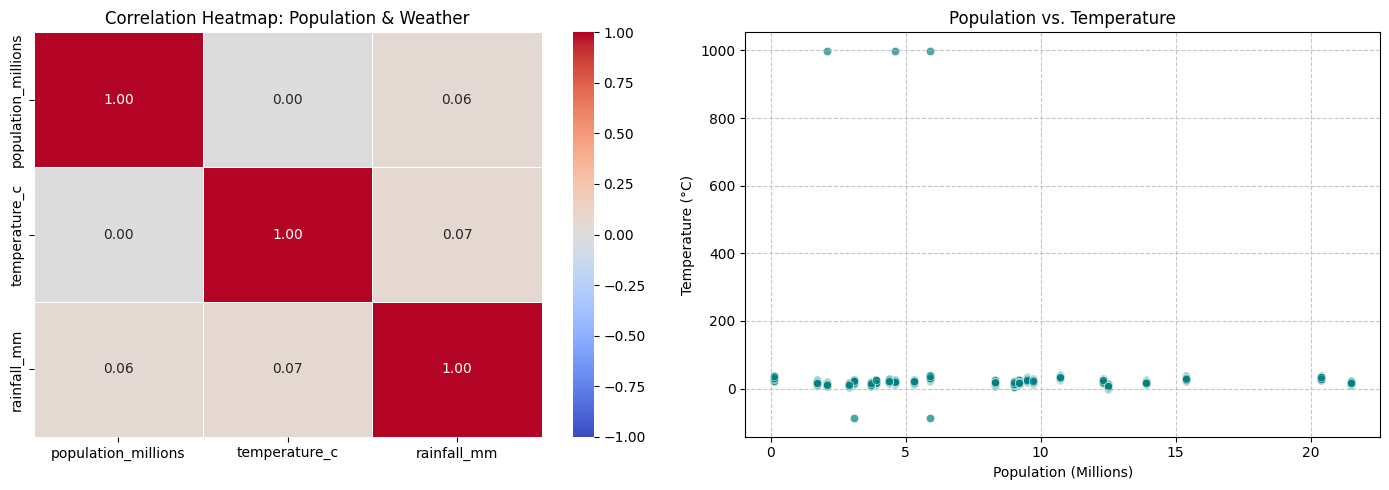

In [5]:
# คำตอบข้อ 18.3
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# วิธีจัดการค่าว่างและค่าผิดปกติ:
# เลือกใช้การทำ .dropna() เฉพาะคอลัมน์สำคัญที่นำมาคำนวณ (population_millions, temperature_c, rainfall_mm)
# เพื่อป้องกันผลกระทบจากค่าสูญหาย (Missing Values) และตัดค่าข้อมูลที่ผิดปกติออก
merged_data = df.merge(city_info[['city', 'population_millions']], on='city', how='inner')

clean_data = merged_data.dropna(subset=['population_millions', 'temperature_c', 'rainfall_mm'])

# คำนวณตารางค่าสหสัมพันธ์ (Correlation Matrix) แบบต่อเนื่อง
correlation_table = (
    clean_data[['population_millions', 'temperature_c', 'rainfall_mm']]
    .corr()
)

print("--- ตารางค่าสหสัมพันธ์ (Correlation Matrix) ---")
print(correlation_table)

# ==========================================
# สร้างกราฟแสดงผล (Heatmap และ Scatter Plot)
# ==========================================
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(14, 5))

# 1. Heatmap แสดงค่าสหสัมพันธ์
sns.heatmap(correlation_table, annot=True, cmap='coolwarm', vmin=-1, vmax=1, fmt='.2f', ax=axes[0], linewidths=0.5)
axes[0].set_title('Correlation Heatmap: Population & Weather')

# 2. Scatter Plot ระหว่าง Population กับ Temperature
sns.scatterplot(data=clean_data, x='population_millions', y='temperature_c', ax=axes[1], color='teal', alpha=0.7)
axes[1].set_title('Population vs. Temperature')
axes[1].set_xlabel('Population (Millions)')
axes[1].set_ylabel('Temperature (°C)')
axes[1].grid(True, linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

จากการคำนวณ Pearson Correlation ระหว่างจำนวนประชากรกับอุณหภูมิและปริมาณฝน พบว่าค่าสหสัมพันธ์มีค่าใกล้ 0 แสดงว่าในชุดข้อมูลนี้ จำนวนประชากรแทบไม่มีความสัมพันธ์เชิงเส้นกับอุณหภูมิหรือปริมาณฝน อย่างไรก็ตาม ไม่ควรสรุปว่าจำนวนประชากรไม่มีผลต่อสภาพอากาศโดยสิ้นเชิง เพราะ Correlation ไม่ได้หมายถึงความเป็นเหตุเป็นผล (Correlation does not imply causation) นอกจากนี้ยังมีปัจจัยอื่น ๆ ที่อาจส่งผลต่อสภาพอากาศ เช่น ที่ตั้งทางภูมิศาสตร์ ละติจูด และความสูงจากระดับน้ำทะเล ซึ่งอาจเป็นตัวแปรแฝงที่สำคัญ ดังนั้น ผลการวิเคราะห์นี้ควรตีความเพียงว่า “ไม่พบความสัมพันธ์เชิงเส้นที่ชัดเจนระหว่างจำนวนประชากรกับอุณหภูมิและปริมาณฝนในชุดข้อมูลนี้” ไม่ใช่การยืนยันว่าประชากรไม่มีผลต่อสภาพอากาศเลย

4. เดือนใดของแต่ละภูมิภาคที่ควรหลีกเลี่ยงการเดินทางมากที่สุด
   ให้กำหนดเกณฑ์การตัดสินใจจากข้อมูลที่มีอยู่ และอธิบายเหตุผลของการเลือกเกณฑ์ดังกล่าว

,region,month_num,month,avg_rainfall
0,Africa,1,มกราคม,4.223333
1,Africa,2,กุมภาพันธ์,4.096364
2,Africa,3,มีนาคม,3.765546
3,Asia,1,มกราคม,5.681319
4,Asia,2,กุมภาพันธ์,6.400000



--- สรุปเดือนที่ควรหลีกเลี่ยงการเดินทางมากที่สุดของแต่ละภูมิภาค ---
       region      month  avg_rainfall
       Africa     มกราคม      4.223333
         Asia กุมภาพันธ์      6.400000
       Europe     มกราคม      3.302479
North America     มกราคม      3.518333
      Oceania     มีนาคม      4.376364
South America กุมภาพันธ์      3.677778


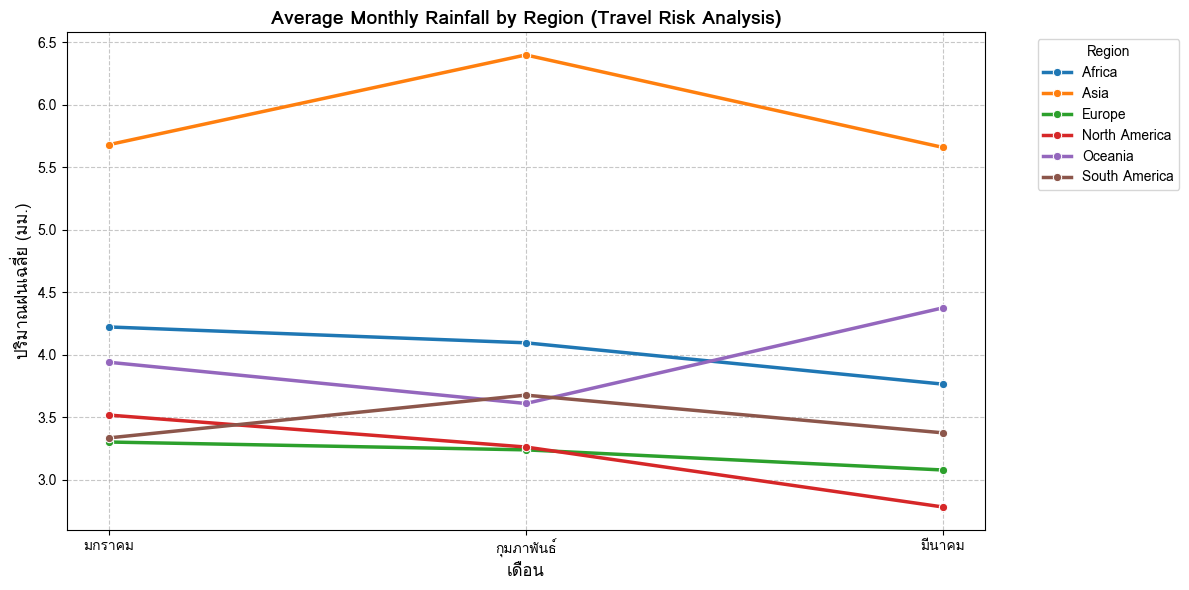

In [13]:
# คำตอบข้อ 18.4
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# ตรวจสอบและแปลงคอลัมน์ date เป็น datetime
final_merged_clean['date'] = pd.to_datetime(final_merged_clean['date'])
final_merged_clean['month_num'] = final_merged_clean['date'].dt.month

# คำนวณค่าเฉลี่ยปริมาณฝนรายเดือนแยกตามภูมิภาค
monthly_region_rain = (
    final_merged_clean.dropna(subset=['region', 'month_num', 'rainfall_mm'])
    .groupby(['region', 'month_num', 'month'])['rainfall_mm']
    .mean()
    .reset_index(name='avg_rainfall')
)

# แสดงผลลัพธ์ข้อมูลสรุป 5 แถวแรก
display(monthly_region_rain.head())

# หาเดือนที่มีปริมาณฝนเฉลี่ยสูงสุดของแต่ละภูมิภาค (เดือนที่ควรหลีกเลี่ยงมากที่สุด)
worst_month_by_region = (
    monthly_region_rain.loc[monthly_region_rain.groupby('region')['avg_rainfall'].idxmax()]
    .reset_index(drop=True)
)

print("\n--- สรุปเดือนที่ควรหลีกเลี่ยงการเดินทางมากที่สุดของแต่ละภูมิภาค ---")
print(worst_month_by_region[['region', 'month', 'avg_rainfall']].to_string(index=False))

# ==========================================
# สร้างกราฟแสดงผล
# ==========================================
# บังคับใช้ฟ้อนต์ภาษาไทย Loma บนกราฟเพื่อป้องกันรูปสี่เหลี่ยมแทนตัวอักษร
plt.rcParams['font.family'] = 'Loma'

plt.figure(figsize=(12, 6))
sns.lineplot(
    data=monthly_region_rain.sort_values('month_num'),
    x='month',
    y='avg_rainfall',
    hue='region',
    marker='o',
    linewidth=2.5,
    palette='tab10'
)

plt.title('Average Monthly Rainfall by Region (Travel Risk Analysis)', fontsize=14, fontweight='bold')
plt.xlabel('เดือน', fontsize=12) # ปรับแก้ชื่อแกน X เป็นรายเดือนทั่วไป
plt.ylabel('ปริมาณฝนเฉลี่ย (มม.)', fontsize=12)
plt.legend(title='Region', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

**เกณฑ์การตัดสินใจ:** ใช้เกณฑ์ "ปริมาณฝนเฉลี่ยรายเดือนสูงสุด (Maximum Average Monthly Rainfall)" ในช่วงข้อมูลที่มีการบันทึก (เดือนที่ 1 ถึง 3) เป็นตัวชี้วัดหลักในการประเมินความเสี่ยง
  **เหตุผล:** ปริมาณฝนเป็นปัจจัยทางธรรมชาติที่ส่งผลกระทบโดยตรงต่อความสะดวกสบาย ความปลอดภัยในการเดินทาง และทัศนวิสัย การเลือกเดือนที่มีค่าเฉลี่ยปริมาณฝนสูงที่สุดในแต่ละภูมิภาคจะช่วยสะท้อนช่วงเวลาที่เสี่ยงต่ออุปสรรคทางสภาพอากาศมากที่สุด จึงควรหลีกเลี่ยงการเดินทางในเดือนดังกล่าว

สรุปเดือนที่ควรหลีกเลี่ยงการเดินทางมากที่สุดของแต่ละภูมิภาค

 **ภูมิภาค Asia**: เดือนที่ 2 เนื่องจากเป็นช่วงที่มีปริมาณฝนเฉลี่ยสูงสุดในรอบไตรมาส โดยพุ่งขึ้นไปสูงถึงประมาณ 6.4 มิลลิเมตร  

**ภูมิภาค Africa:** เดือนที่ 1 เนื่องจากมีปริมาณฝนเฉลี่ยสูงสุดอยู่ที่ประมาณ 4.2 มิลลิเมตร ก่อนจะมีแนวโน้มลดลงในเดือนที่ 2 และ 3   

**ภูมิภาค Oceania:** เดือนที่ 3 เนื่องจากปริมาณฝนเพิ่มสูงขึ้นอย่างเห็นได้ชัดจนไปแตะจุดสูงสุดที่ประมาณ 4.4 มิลลิเมตร   

**ภูมิภาค South America:** เดือนที่ 2 เป็นเดือนที่มีปริมาณฝนเฉลี่ยสูงสุดในกลุ่มอยู่ที่ประมาณ 3.7 มิลลิเมตร   

**ภูมิภาค Europe:** เดือนที่ 1 มีปริมาณฝนเฉลี่ยสูงสุดในช่วงต้นปีที่ประมาณ 3.3 มิลลิเมตร ก่อนจะค่อย ๆ ลดลงในเดือนถัดไป   

**ภูมิภาค North America:** เดือนที่ 1 เป็นช่วงที่มีปริมาณฝนเฉลี่ยสูงสุดที่ประมาณ 3.5 มิลลิเมตร ก่อนจะลดต่ำลงเรื่อย ๆ จนถึงเดือนที่ 3

---

<center>จบแล้ว ขอแสดงความยินดีกับทุกคน

<center>> เขียนเองหนึ่งบรรทัด ได้ความเข้าใจมากกว่าอ่านผ่านตาสิบบรรทัด
> One line you write yourself teaches more than ten you only read.

> คนที่จัดการข้อมูลสองพันแถวได้อย่างสะอาดหมดจด คือคนเดียวกับที่จะจัดการข้อมูลสองล้านแถวได้อย่างมั่นใจ
> Whoever handles two thousand rows with care will handle two million with confidence.

<center>❤️❤️❤️❤️❤️ Keep Learning ❤️❤️❤️❤️❤️